# EDA – komentarze YouTube wokół wydarzeń związanych z migracją

Eksploracyjna analiza danych zebranych przez `amc.py` (YouTube Data API), połączonych w `laczenie_plikow.py`
w jeden plik `zbiorczy_analiza_komentarzy_youtube_polaczony.csv`.

Każdy wiersz pliku to **jeden komentarz najwyższego poziomu** (bez odpowiedzi w wątkach) pod filmem opublikowanym
na kanale w oknie **−7 … +14 dni** wokół wydarzenia:

| kolumna | znaczenie |
|---|---|
| `anon_comment_id` | anonimowy identyfikator komentarza (`c_1`, `c_2`, …) |
| `event_name`, `event_date` | wydarzenie (T0) i jego data |
| `channel_name` | kanał YouTube|
| `video_id`, `video_title`, `video_published_at` | film, pod którym jest komentarz |
| `published_at` | data i godzina komentarza (UTC) |
| `like_count` | liczba polubień komentarza |
| `text` | treść komentarza |

**Spis treści**
1. Ustawienia i wczytanie danych
2. Przegląd zbioru – komentarze, filmy, kanały na wydarzenie
3. Wolumen w czasie – filmy i komentarze względem dnia wydarzenia, przed vs po
4. Słowa kluczowe – obraz globalny, profil wydarzeń, **osie czasu per wydarzenie**, zmiany przed→po, współwystępowanie
5. Zaangażowanie – polubienia, najbardziej lubiane komentarze
6. Filmy – koncentracja komentarzy, najpopularniejsze filmy, typ filmu
7. Czas komentowania – opóźnienie względem publikacji filmu, dzień tygodnia × godzina
8. Tekst – długość, cechy, najczęstsze słowa, słowa rosnące po wydarzeniu
9. Jakość komentarzy – same emoji, zbyt krótkie, inny język, duplikaty; nakładanie się okien wydarzeń
10. Najważniejsze wnioski (generowane automatycznie)

> **Uwagi do interpretacji**
> * W pliku są tylko filmy, pod którymi **jest co najmniej jeden komentarz** – liczba filmów to liczba filmów z komentarzami.
> * Komentarze są pobierane **po czasie** (pod filmem są komentarze z całego okresu do momentu pobrania), dlatego
>   `MAX_AGE_DAYS` (sekcja 1) obcina je do N dni od publikacji filmu, tak jak `kom.py`.
> * Identyfikatory autorów celowo nie są zbierane – analiza nie obejmuje autorów komentarzy.

## 1. Ustawienia i wczytanie danych

In [ ]:
import html
import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)

# ---- ustawienia --------------------------------------------------------------------------
DATA_FILE = None           
DATA_CANDIDATES = [
    'komentarze_2tygodnie_po_publikacji_filmu.csv'
]
TZ = 'Europe/Warsaw'
WINDOW_BEFORE, WINDOW_AFTER = 7, 14   # okno filmów wokół wydarzenia (jak w amc.py: -7 / +14 dni)
MAX_AGE_DAYS = 14                 # bierz komentarze do N dni po publikacji filmu (jak kom.py); None = bez filtra
SAVE_FIGS = False                 # True = zapisuj każdy wykres jako PNG do FIG_DIR
FIG_DIR = Path('eda_figures')

In [ ]:
# ---- styl wykresów -----------------------------------------------
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
TEXT_PRIMARY, TEXT_SECONDARY = '#0b0b0b', '#52514e'
GRID, SURFACE, NEUTRAL, SHADE = '#e6e5e0', '#fcfcfb', '#a9a8a2', '#f1f0ea'
POS, NEG = '#2a78d6', '#eb6834'   # bieguny skali rozbieżnej: wzrost / spadek
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fd', '#a9c9ef', '#2a78d6', '#0f3f7a'])
DIV = LinearSegmentedColormap.from_list('div', [NEG, SURFACE, POS])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': TEXT_SECONDARY, 'axes.edgecolor': GRID, 'text.color': TEXT_PRIMARY,
    'xtick.color': TEXT_SECONDARY, 'ytick.color': TEXT_SECONDARY,
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=SERIES), 'lines.linewidth': 2,
    'legend.frameon': False, 'figure.titlesize': 14, 'figure.titleweight': 'bold',
})


def savefig(fig, name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


def hbar(ax, values, labels=None, color=SERIES[0], fmt='{:,.0f}'):
    # Poziomy wykres słupkowy z wartościami na końcach słupków; pierwszy element na górze.
    values = pd.Series(values)
    y = np.arange(len(values))
    ax.barh(y, values.values, color=color, height=0.7)
    ax.set_yticks(y, labels if labels is not None else values.index)
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    xmax = np.nanmax(values.values) if len(values) and np.nanmax(values.values) > 0 else 1
    for yi, v in zip(y, values.values):
        if pd.notna(v):
            ax.text(v + xmax * 0.01, yi, fmt.format(v), va='center', fontsize=8.5, color=TEXT_SECONDARY)
    ax.set_xlim(0, xmax * 1.18)


def small_multiples(n, ncols=3, w=5.2, h=2.7, **kw):
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False, **kw)
    axes = axes.flatten()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def mark_event_day(ax, xmax=None):
    # Przerywana linia w dniu 0 i jasne tło dla fazy "po".
    ax.axvline(0, color=TEXT_SECONDARY, lw=1, ls='--')
    if xmax is not None:
        ax.axvspan(0, xmax, color=SHADE, zorder=0, lw=0)


def short(t, n=180):
    # Zwija białe znaki i skraca długie teksty do wyświetlenia w tabelach.
    t = re.sub(r'\s+', ' ', str(t))
    return t if len(t) <= n else t[:n - 1] + '…'


def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    if len(x) == 0 or x.sum() == 0:
        return np.nan
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

In [83]:
# ---- wczytanie pliku ---------------------------------------------------------------------
if DATA_FILE is None:
    DATA_FILE = next((Path(p) for p in DATA_CANDIDATES if Path(p).exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError('Nie znaleziono pliku z danymi. Ustaw DATA_FILE lub dodaj ścieżkę do DATA_CANDIDATES.')

raw = pd.read_csv(DATA_FILE, encoding='utf-8-sig', low_memory=False)

REQUIRED = ['event_name', 'event_date', 'channel_name', 'video_id', 'video_title',
            'video_published_at', 'published_at', 'like_count', 'text']
missing = [c for c in REQUIRED if c not in raw.columns]
if missing:
    raise ValueError(f'W pliku brakuje kolumn: {missing}')

TAG_RE = re.compile(r'<[^>]+>')

def clean_text(t):
    # YouTube potrafi zwrócić encje HTML (&#39;, &amp;) i <br> – normalizujemy do zwykłego tekstu.
    t = re.sub(r'<br\s*/?>', ' ', str(t))
    return html.unescape(TAG_RE.sub('', t)).strip()

df_full = raw.copy()
df_full['text'] = df_full['text'].fillna('').map(clean_text)
df_full['video_title'] = df_full['video_title'].fillna('').map(lambda s: html.unescape(str(s)))
df_full['like_count'] = pd.to_numeric(df_full['like_count'], errors='coerce').fillna(0).astype(int)

df_full['comment_at'] = pd.to_datetime(df_full['published_at'], utc=True, errors='coerce')
df_full['video_at'] = pd.to_datetime(df_full['video_published_at'], utc=True, errors='coerce')
df_full['comment_local'] = df_full['comment_at'].dt.tz_convert(TZ)
df_full['video_local'] = df_full['video_at'].dt.tz_convert(TZ)
df_full['event_date'] = pd.to_datetime(df_full['event_date'], errors='coerce')

def local_day(s):
    return s.dt.tz_localize(None).dt.normalize()

df_full['video_rel_day'] = (local_day(df_full['video_local']) - df_full['event_date']).dt.days
df_full['comment_rel_day'] = (local_day(df_full['comment_local']) - df_full['event_date']).dt.days
df_full['days_since_video'] = (local_day(df_full['comment_local']) - local_day(df_full['video_local'])).dt.days
df_full['hours_since_video'] = (df_full['comment_at'] - df_full['video_at']).dt.total_seconds() / 3600
df_full['video_phase'] = np.select([df_full['video_rel_day'] < 0, df_full['video_rel_day'] == 0],
                                   ['before', 'day_0'], 'after')

n_bad = int(df_full[['comment_at', 'video_at', 'event_date']].isna().any(axis=1).sum())
df_full = df_full.dropna(subset=['comment_at', 'video_at', 'event_date'])

# Filtr wieku komentarza (jak w kom.py: 0..14 dni od publikacji filmu)
if MAX_AGE_DAYS is None:
    df = df_full.copy()
else:
    df = df_full[df_full['days_since_video'].between(0, MAX_AGE_DAYS)].copy()
df = df.reset_index(drop=True)

print(f'Plik: {DATA_FILE}')
print(f'Wczytano {len(raw):,} wierszy; odrzucono {n_bad:,} z błędną datą.')
if MAX_AGE_DAYS is not None:
    print(f'Filtr wieku (0..{MAX_AGE_DAYS} dni od publikacji filmu): zostaje {len(df):,} z {len(df_full):,} komentarzy '
          f'({len(df) / max(len(df_full), 1) * 100:.1f}%).')
print(f'Zakres dat komentarzy: {df.comment_local.min():%Y-%m-%d} – {df.comment_local.max():%Y-%m-%d}')

Plik: komentarze_2tygodnie_po_publikacji_filmu.csv
Wczytano 1,502,074 wierszy; odrzucono 0 z błędną datą.
Filtr wieku (0..14 dni od publikacji filmu): zostaje 1,501,833 z 1,502,074 komentarzy (100.0%).
Zakres dat komentarzy: 2022-02-17 – 2026-10-12


In [84]:
# ---- wydarzenia, etykiety, kompletność okna ----------------------------------------------
EVENT_DATES = df.groupby('event_name')['event_date'].first().sort_values()
EVENTS = list(EVENT_DATES.index)
CHANNELS = list(df['channel_name'].value_counts().index)
CH_COLOR = {c: SERIES[i % len(SERIES)] for i, c in enumerate(CHANNELS)}

# Moment pobrania ~ najnowszy komentarz. Wydarzenia, dla których okno filmów + okno wieku komentarzy
# jeszcze się nie zakończyło, oznaczamy gwiazdką (ich ostatnie filmy mają mniej "dojrzałych" komentarzy).
COLLECTED = df_full['comment_local'].max().tz_localize(None).normalize()
INCOMPLETE = [e for e in EVENTS
              if EVENT_DATES[e] + pd.Timedelta(days=WINDOW_AFTER + (MAX_AGE_DAYS or 0)) > COLLECTED]

LABEL = {e: f"{e.replace('_', ' ')} ({d:%Y-%m-%d})" + (' *' if e in INCOMPLETE else '')
         for e, d in EVENT_DATES.items()}
LABELS = [LABEL[e] for e in EVENTS]
COMMENT_HI = WINDOW_AFTER + (MAX_AGE_DAYS if MAX_AGE_DAYS is not None else 60)   # zakres osi dni komentarzy

print(f'{len(EVENTS)} wydarzeń, {len(CHANNELS)} kanałów: {", ".join(CHANNELS)}')
for e in INCOMPLETE:
    print(f'* {e}: dane zebrane przed końcem okna (data pobrania ≈ {COLLECTED:%Y-%m-%d}) – możliwe niepełne komentarze')

16 wydarzeń, 10 kanałów: Kanal_Zero, Telewizja_Republika, tvp_info, SławomirMentzen, Onet, polsatnews.pl, Praktycznieopieniadzach, TVN24, Orb, Razem
* Atak_Jaroslaw: dane zebrane przed końcem okna (data pobrania ≈ 2026-10-12) – możliwe niepełne komentarze


In [85]:
# ---- słowniki słów kluczowych (rdzenie, dopasowanie po fragmencie słowa) --------------------
# Zmień dowolnie: nazwa -> regex (na tekście zapisanym małymi literami).
KEYWORDS = {
    'migrant / imigrant': r'migran',
    'uchodźc*':           r'uchod[źz]c',
    'nachodźc*':          r'nachod[źz]c',
    'azyl':               r'azyl',
    'relokacja':          r'relokac',
    'cudzoziemcy':        r'cudzoziem',
    'obcokrajowcy':       r'obcokrajow',
    'deportacja':         r'deportac',
    'granica':            r'granic',
    'pakt':               r'\bpakt',
    'socjal / 800+':      r'socjal|800\s?\+',
    'Ukraina / Ukraińcy': r'ukra[ií]',
    'islam / muzułmanie': r'islam|muzu[łl]ma',
    'wojna':              r'wojn',
}
# Słowa "rdzeniowe" – komentarz/film "o migracji" (zgodne z analiza.py; granica i pakt są niejednoznaczne,
# więc zostają, ale możesz je usunąć z CORE_KEYS, żeby zawęzić definicję).
CORE_KEYS = ['migrant / imigrant', 'uchodźc*', 'nachodźc*', 'azyl', 'relokacja',
             'cudzoziemcy', 'obcokrajowcy', 'deportacja', 'granica']
CORE_RE = re.compile('|'.join(KEYWORDS[k] for k in CORE_KEYS))

# ---- kolumny pochodne ------------------------------------------------------------------
df['text_lc'] = df['text'].str.lower()
df['title_lc'] = df['video_title'].str.lower()
df['text_len'] = df['text'].str.len()
df['is_migr'] = df['text_lc'].str.contains(CORE_RE)
df['title_migr'] = df['title_lc'].str.contains(CORE_RE)
df['typ_filmu'] = np.where(df['title_migr'], 'film o migracji', 'inny film')

# Macierz komentarz x słowo kluczowe (True/False)
KWM = pd.DataFrame({name: df['text_lc'].str.contains(rx, regex=True) for name, rx in KEYWORDS.items()})
df['n_keywords'] = KWM.sum(axis=1)

# Tabela filmów (jeden wiersz = film w obrębie wydarzenia; tylko filmy z komentarzami)
videos = (df.groupby(['event_name', 'video_id'])
          .agg(channel_name=('channel_name', 'first'), video_title=('video_title', 'first'),
               video_local=('video_local', 'first'), video_rel_day=('video_rel_day', 'first'),
               video_phase=('video_phase', 'first'), title_migr=('title_migr', 'first'),
               comments=('like_count', 'size'), likes=('like_count', 'sum'),
               migr_comments=('is_migr', 'sum'))
          .reset_index())

print(f'Komentarzy w analizie: {len(df):,} | filmów z komentarzami: {len(videos):,}')
df[['event_name', 'channel_name', 'video_title', 'video_rel_day', 'days_since_video', 'like_count', 'is_migr', 'text']].head(5)

Komentarzy w analizie: 1,501,833 | filmów z komentarzami: 10,566


,event_name,channel_name,video_title,video_rel_day,days_since_video,like_count,is_migr,text
0,Atak_Rosji_Ukraina,Onet,"""Bardzo doceniamy to, co robią Polacy"". Premiera filmu pt. ""Kto jest bratem"" dziś wieczorem w #onet",11,6,2,False,Nasi bracia leza w dolach pomordowani \nprzez ukraincow.
1,Atak_Rosji_Ukraina,Onet,"""Bardzo doceniamy to, co robią Polacy"". Premiera filmu pt. ""Kto jest bratem"" dziś wieczorem w #onet",11,5,1,False,Siostrzanstwo też nie jest pustym słowem ❤️❤️❤️
2,Atak_Rosji_Ukraina,Onet,"""Bardzo doceniamy to, co robią Polacy"". Premiera filmu pt. ""Kto jest bratem"" dziś wieczorem w #onet",11,5,7,False,Myśle ze już pora przeprosić za Wołyń i zakazać znaków banderowskich na terenie całej ukrainy
3,Atak_Rosji_Ukraina,Onet,"""Bardzo doceniamy to, co robią Polacy"". Premiera filmu pt. ""Kto jest bratem"" dziś wieczorem w #onet",11,3,3,False,Broncie Polski jak. Polska umie bronić bezbronnych . A eliminujcie z Polski wszystkich takich jak Po-wcy ktozy sprzedaja nasz kraj i nas...
4,Atak_Rosji_Ukraina,Onet,"""Bardzo doceniamy to, co robią Polacy"". Premiera filmu pt. ""Kto jest bratem"" dziś wieczorem w #onet",11,3,4,False,Jakie braterstwo???


## 2. Przegląd zbioru

Ile komentarzy i filmów dał każdy kanał i każde wydarzenie, jaka część komentarzy dotyczy migracji
(wg słów rdzeniowych `CORE_KEYS`) i jak rozkładają się polubienia.

In [86]:
g = df.groupby('event_name')
summary = pd.DataFrame(index=pd.Index(EVENTS, name='event'))
summary['event_date'] = EVENT_DATES.dt.date
summary['channels'] = g['channel_name'].nunique()
summary['videos'] = videos.groupby('event_name').size()
summary['comments'] = g.size()
summary['comments_per_video'] = (summary['comments'] / summary['videos']).round(1)
summary['likes_total'] = g['like_count'].sum()
summary['migr_comments_%'] = (g['is_migr'].mean() * 100).round(1)
summary['migr_title_videos_%'] = (videos.groupby('event_name')['title_migr'].mean() * 100).round(1)
summary['first_comment'] = g['comment_local'].min().dt.strftime('%Y-%m-%d')
summary['last_comment'] = g['comment_local'].max().dt.strftime('%Y-%m-%d')

totals = summary[['videos', 'comments', 'likes_total']].sum()
display(Markdown(f"**Razem:** {totals['comments']:,} komentarzy · {totals['videos']:,} filmów · "
                 f"{totals['likes_total']:,} polubień · {len(EVENTS)} wydarzeń · {len(CHANNELS)} kanałów"))
summary

**Razem:** 1,501,833 komentarzy · 10,566 filmów · 16,097,527 polubień · 16 wydarzeń · 10 kanałów

,event_date,channels,videos,comments,comments_per_video,likes_total,migr_comments_%,migr_title_videos_%,first_comment,last_comment
event,,,,,,,,,,
Atak_Rosji_Ukraina,2022-02-24,5,672,60766,90.4,390528,3.6,4.9,2022-02-17,2022-03-24
Zabojstwo_Nowy_Swiat,2022-05-08,5,466,25868,55.5,245870,1.7,2.4,2022-05-01,2022-06-05
Premiera_Zielona_Granica,2023-09-22,7,497,66662,134.1,590816,5.1,6.4,2023-09-15,2023-10-20
Referendum_Wybory,2023-10-15,7,743,86878,116.9,853212,3.1,2.7,2023-10-08,2023-11-12
Pakt_Azyl_PE,2024-04-10,9,515,109736,213.1,1458039,1.8,1.0,2024-04-03,2024-05-08
Atak_Zolnierz_Granica,2024-05-28,9,579,124322,214.7,1488782,6.6,4.8,2024-05-21,2024-06-25
Smierc_Zolnierza,2024-06-06,9,233,44594,191.4,528272,8.1,8.6,2024-06-01,2024-07-04
Bojka_Srem,2024-09-08,9,867,134033,154.6,1439274,1.7,0.7,2024-09-01,2024-10-06
Strategia_Migracyjna,2024-10-12,9,930,145179,156.1,1671017,2.5,2.5,2024-10-05,2024-11-09


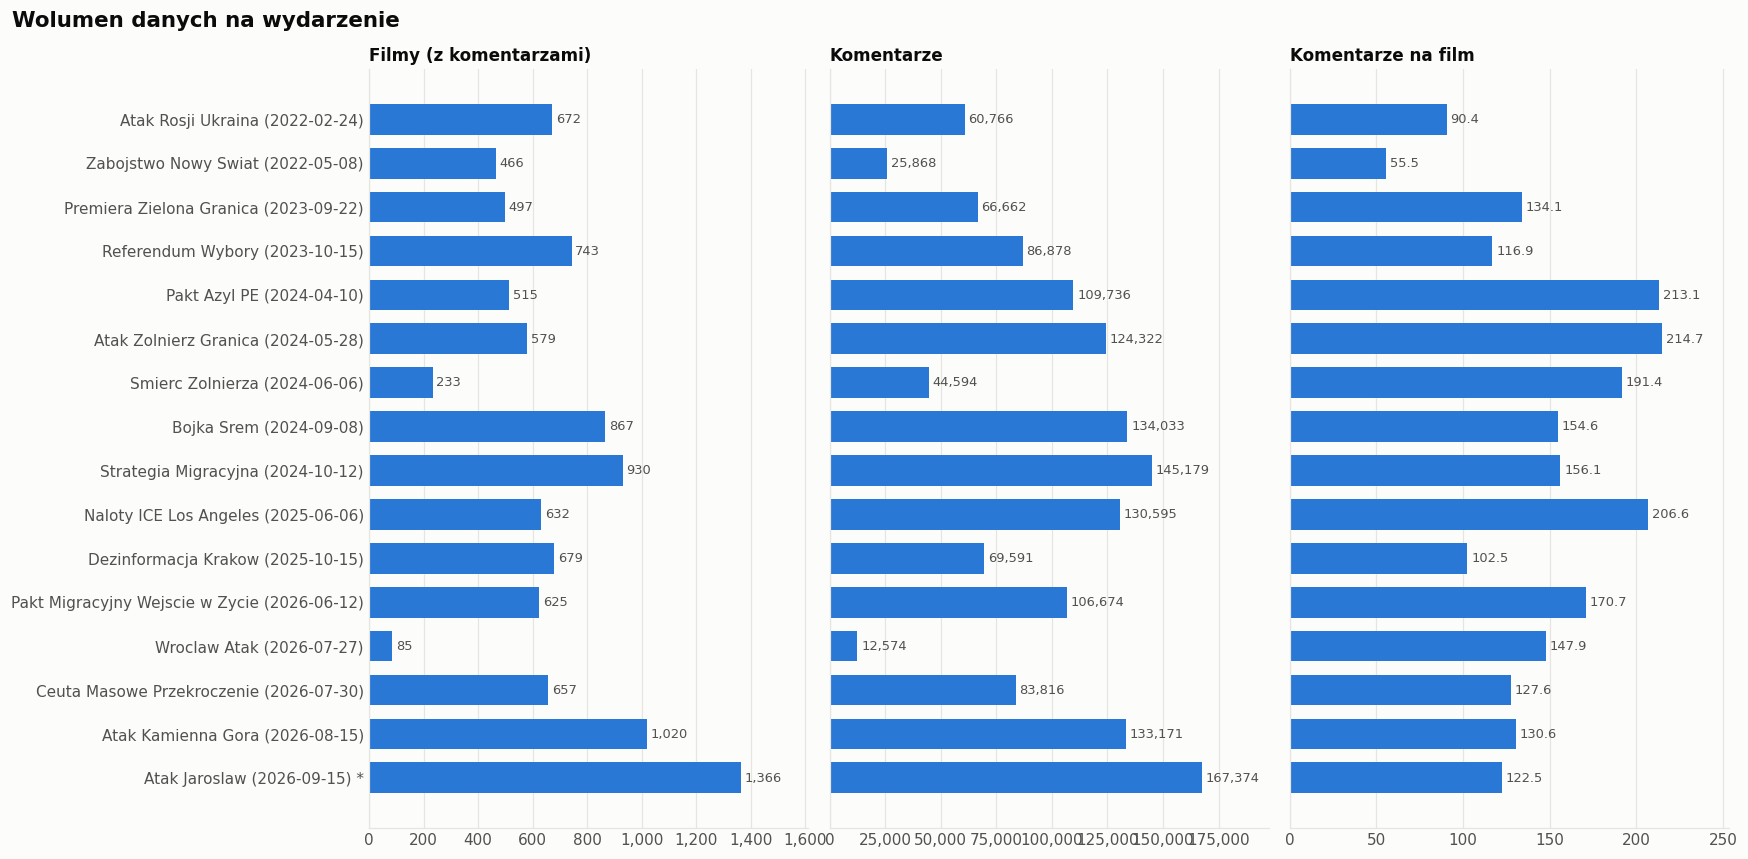

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(16, 0.42 * len(EVENTS) + 1.2), sharey=True)
hbar(axes[0], summary['videos'], LABELS, SERIES[0])
axes[0].set_title('Filmy (z komentarzami)')
hbar(axes[1], summary['comments'], LABELS, SERIES[0])
axes[1].set_title('Komentarze')
hbar(axes[2], summary['comments_per_video'], LABELS, SERIES[0], fmt='{:.1f}')
axes[2].set_title('Komentarze na film')
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
fig.suptitle('Wolumen danych na wydarzenie', x=0.01, ha='left')
fig.tight_layout()
savefig(fig, '01_volume_per_event')

Liczby bezwzględne zależą od tego, ile filmów dany kanał opublikował w oknie wydarzenia i jak głośny był temat.
Dlatego w kolejnych sekcjach używam też **udziałów** i wartości **na film**.

,comments,videos,events,likes_total,likes_mean,likes_median,migr_comments_pct,comments_per_video
channel_name,,,,,,,,
Kanal_Zero,630804,2150,12,7749040,12.28,0.0,2.58,293.4
Telewizja_Republika,387711,3140,16,3855534,9.94,1.0,3.65,123.5
tvp_info,190122,1991,16,1474128,7.75,1.0,3.07,95.5
SławomirMentzen,128333,296,14,1174076,9.15,0.0,3.01,433.6
Onet,78422,1487,16,620934,7.92,1.0,2.65,52.7
polsatnews.pl,42308,1154,16,557115,13.17,3.0,0.34,36.7
Praktycznieopieniadzach,31365,55,16,494416,15.76,0.0,0.72,570.3
TVN24,12007,278,13,167406,13.94,2.0,1.56,43.2
Orb,727,8,6,4750,6.53,0.0,1.38,90.9


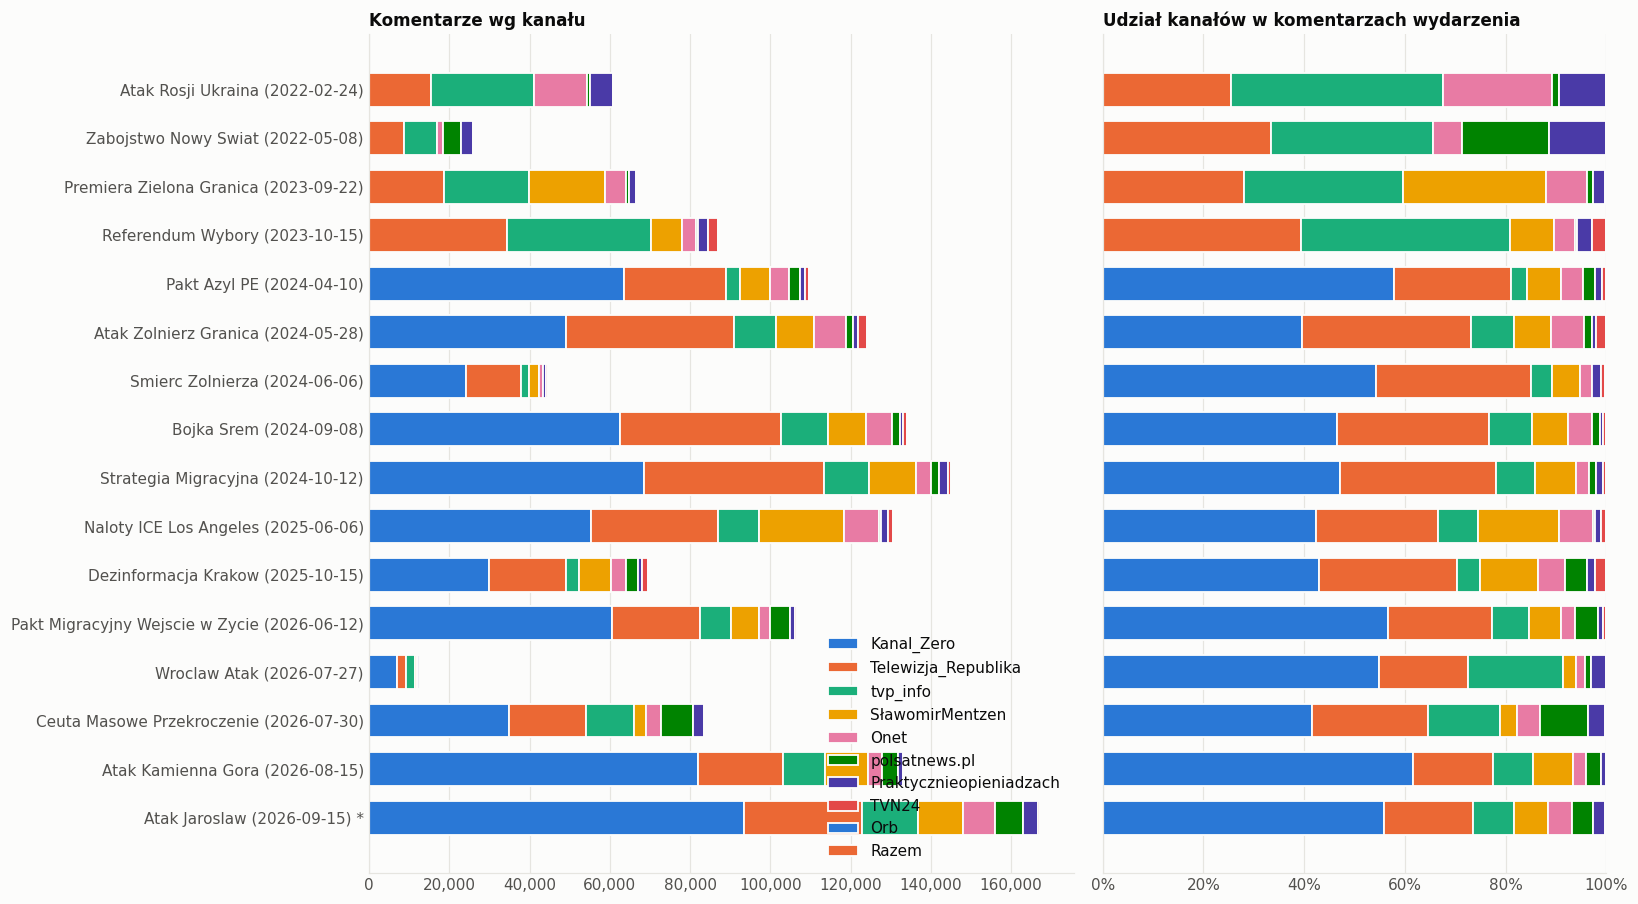

In [88]:
# Komentarze według kanału w obrębie wydarzenia + tabela kanałów
by_ch = df.groupby(['event_name', 'channel_name']).size().unstack(fill_value=0).reindex(index=EVENTS, columns=CHANNELS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(EVENTS) + 1.6), sharey=True,
                         gridspec_kw={'width_ratios': [1.4, 1]})
left = np.zeros(len(EVENTS)); y = np.arange(len(EVENTS))
for c in CHANNELS:
    axes[0].barh(y, by_ch[c].values, left=left, color=CH_COLOR[c], height=0.7, edgecolor=SURFACE, linewidth=1.2, label=c)
    left += by_ch[c].values
axes[0].set_yticks(y, LABELS); axes[0].invert_yaxis(); axes[0].grid(axis='y', visible=False)
axes[0].set_title('Komentarze wg kanału'); axes[0].legend(loc='lower right')
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

share = by_ch.div(by_ch.sum(axis=1).replace(0, np.nan), axis=0) * 100
left = np.zeros(len(EVENTS))
for c in CHANNELS:
    v = share[c].fillna(0).values
    axes[1].barh(y, v, left=left, color=CH_COLOR[c], height=0.7, edgecolor=SURFACE, linewidth=1.2)
    left += v
axes[1].set_xlim(0, 100); axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].grid(axis='y', visible=False); axes[1].set_title('Udział kanałów w komentarzach wydarzenia')
fig.tight_layout()
savefig(fig, '02_channels_per_event')

ch_summary = df.groupby('channel_name').agg(
    comments=('like_count', 'size'), videos=('video_id', 'nunique'), events=('event_name', 'nunique'),
    likes_total=('like_count', 'sum'), likes_mean=('like_count', 'mean'),
    likes_median=('like_count', 'median'), migr_comments_pct=('is_migr', lambda s: s.mean() * 100)).round(2)
ch_summary['comments_per_video'] = (ch_summary['comments'] / ch_summary['videos']).round(1)
ch_summary.loc[CHANNELS]

## 3. Wolumen w czasie

Wszystkie osie czasu używają dni względem wydarzenia (0 = dzień wydarzenia, strefa Europe/Warsaw).
Jasne tło oznacza fazę *po* wydarzeniu. Osie Y są niezależne w każdym panelu, bo wydarzenia różnią się wielkością
o rząd wielkości lub więcej.

### 3.1 Filmy i komentarze według dnia publikacji filmu

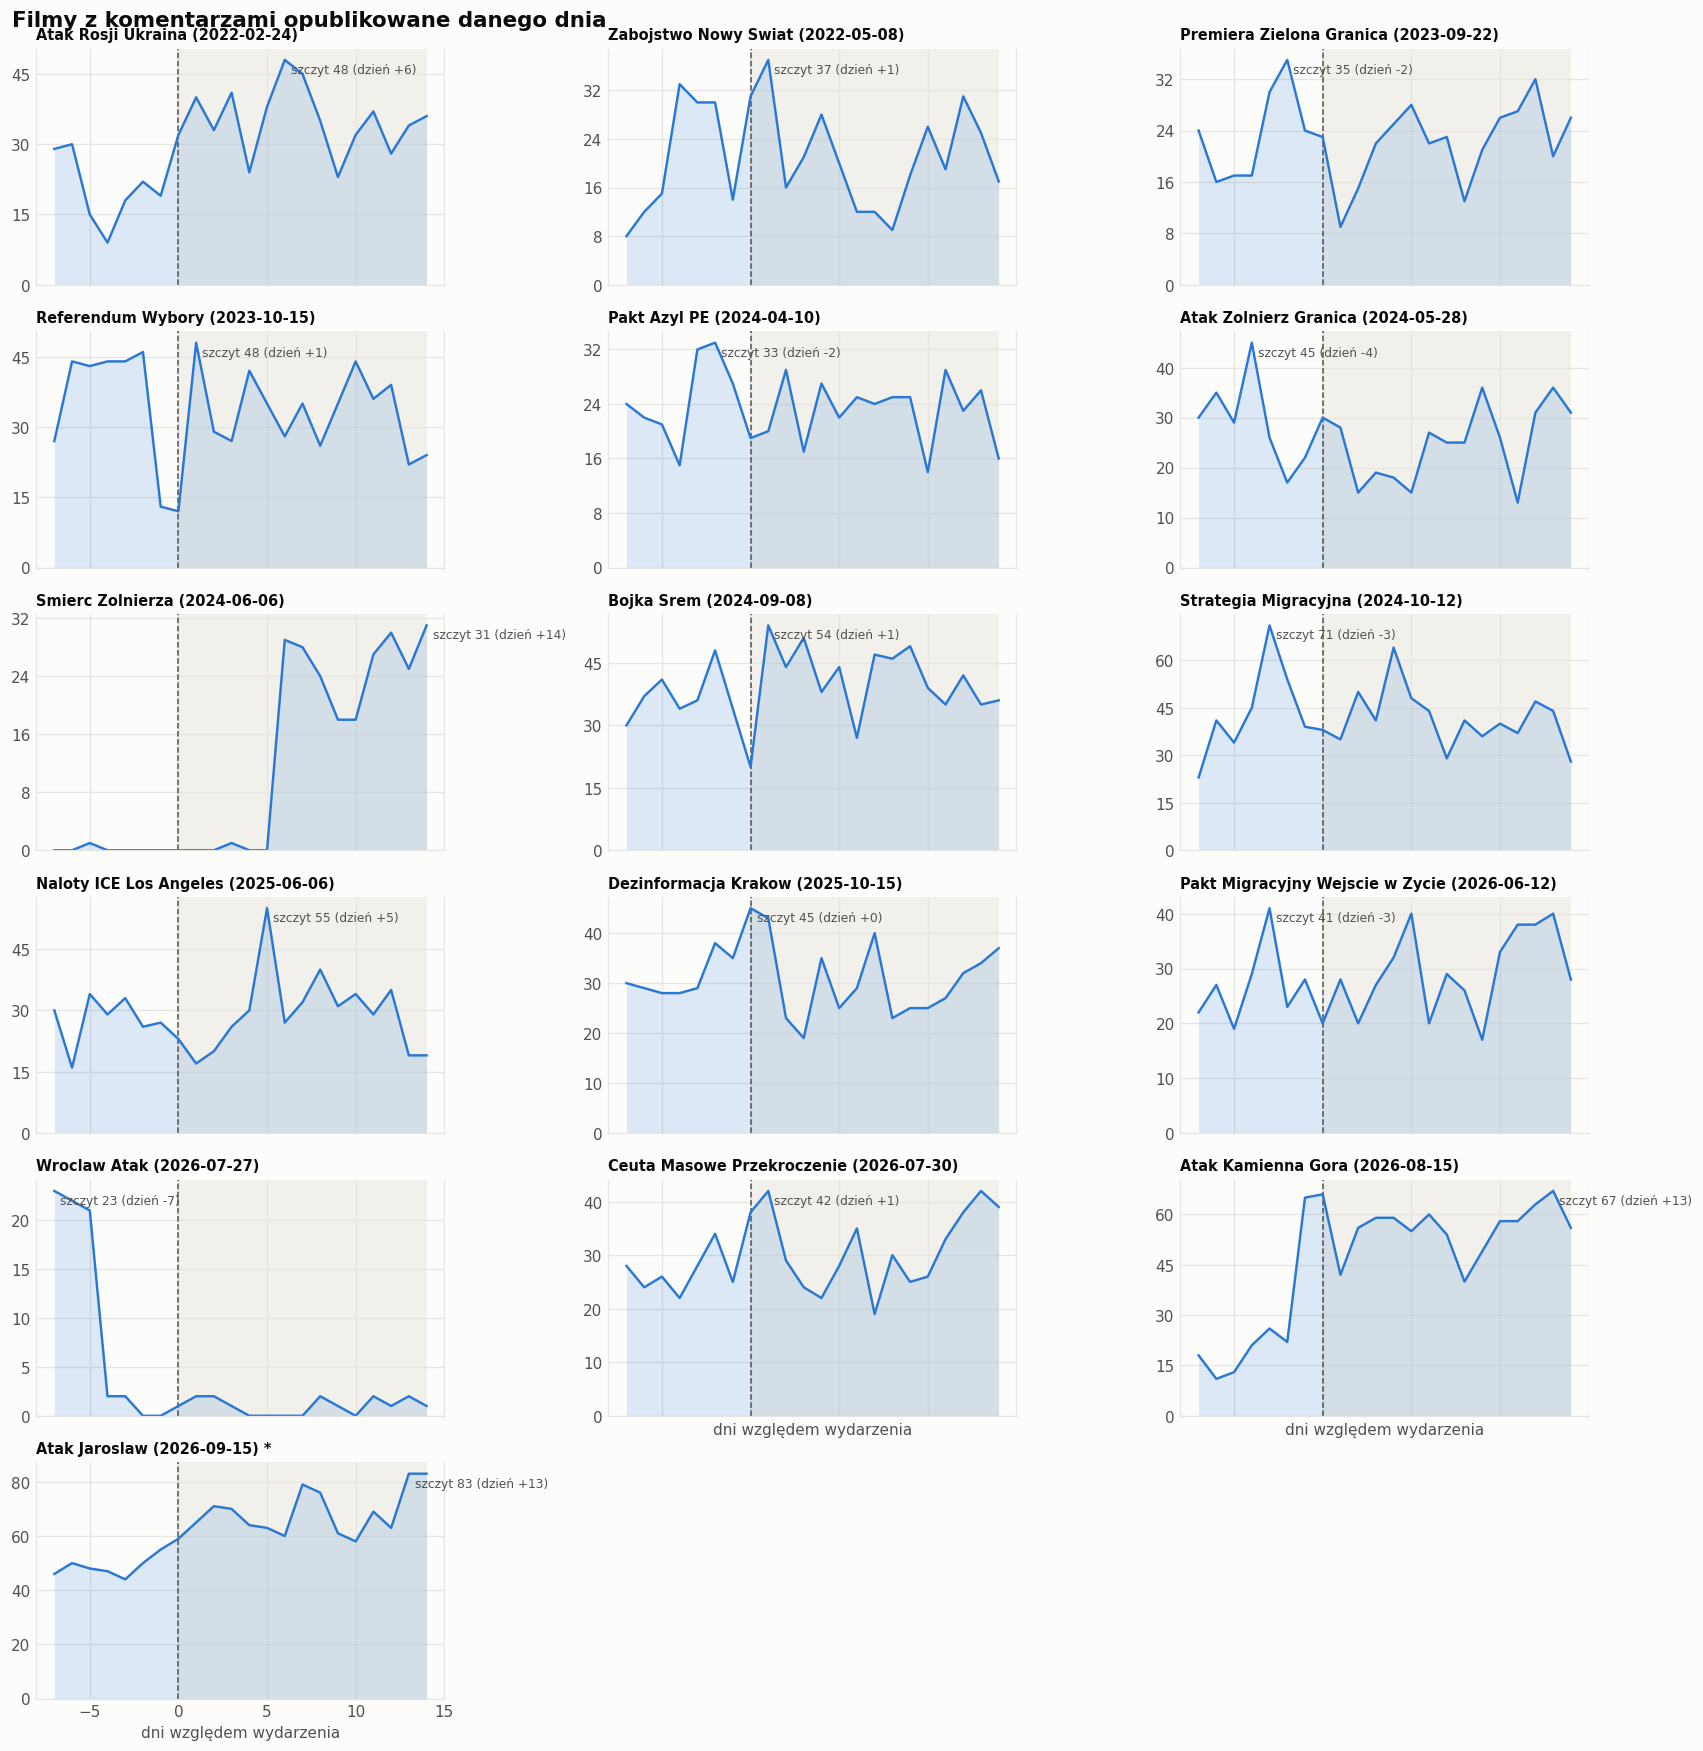

In [89]:
def daily_counts(frame, day_col, lo, hi):
    t = frame.groupby(['event_name', day_col]).size().unstack(fill_value=0)
    return t.reindex(index=EVENTS, columns=range(lo, hi + 1), fill_value=0)


def timeline_grid(table, title, xmax, color=SERIES[0]):
    fig, axes = small_multiples(len(EVENTS), sharex=True)
    for ax, e in zip(axes, EVENTS):
        v = table.loc[e]
        x, yv = v.index.values, v.values.astype(float)
        mark_event_day(ax, xmax)
        ax.fill_between(x, yv, color=color, alpha=0.15, lw=0)
        ax.plot(x, yv, color=color, lw=1.6)
        if len(yv) and np.nanmax(yv) > 0:
            i = int(np.nanargmax(yv))
            ax.annotate(f'szczyt {yv[i]:,.0f} (dzień {x[i]:+d})', (x[i], yv[i]), xytext=(4, -2),
                        textcoords='offset points', fontsize=8, color=TEXT_SECONDARY, va='top')
        ax.set_ylim(bottom=0)
        ax.set_title(LABEL[e], fontsize=9.5)
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=5))
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    for ax in axes[-3:]:
        ax.set_xlabel('dni względem wydarzenia')
    fig.suptitle(title, x=0.01, ha='left')
    fig.tight_layout()
    return fig

videos_daily = daily_counts(videos, 'video_rel_day', -WINDOW_BEFORE, WINDOW_AFTER)
savefig(timeline_grid(videos_daily, 'Filmy z komentarzami opublikowane danego dnia', WINDOW_AFTER), '03_daily_videos')

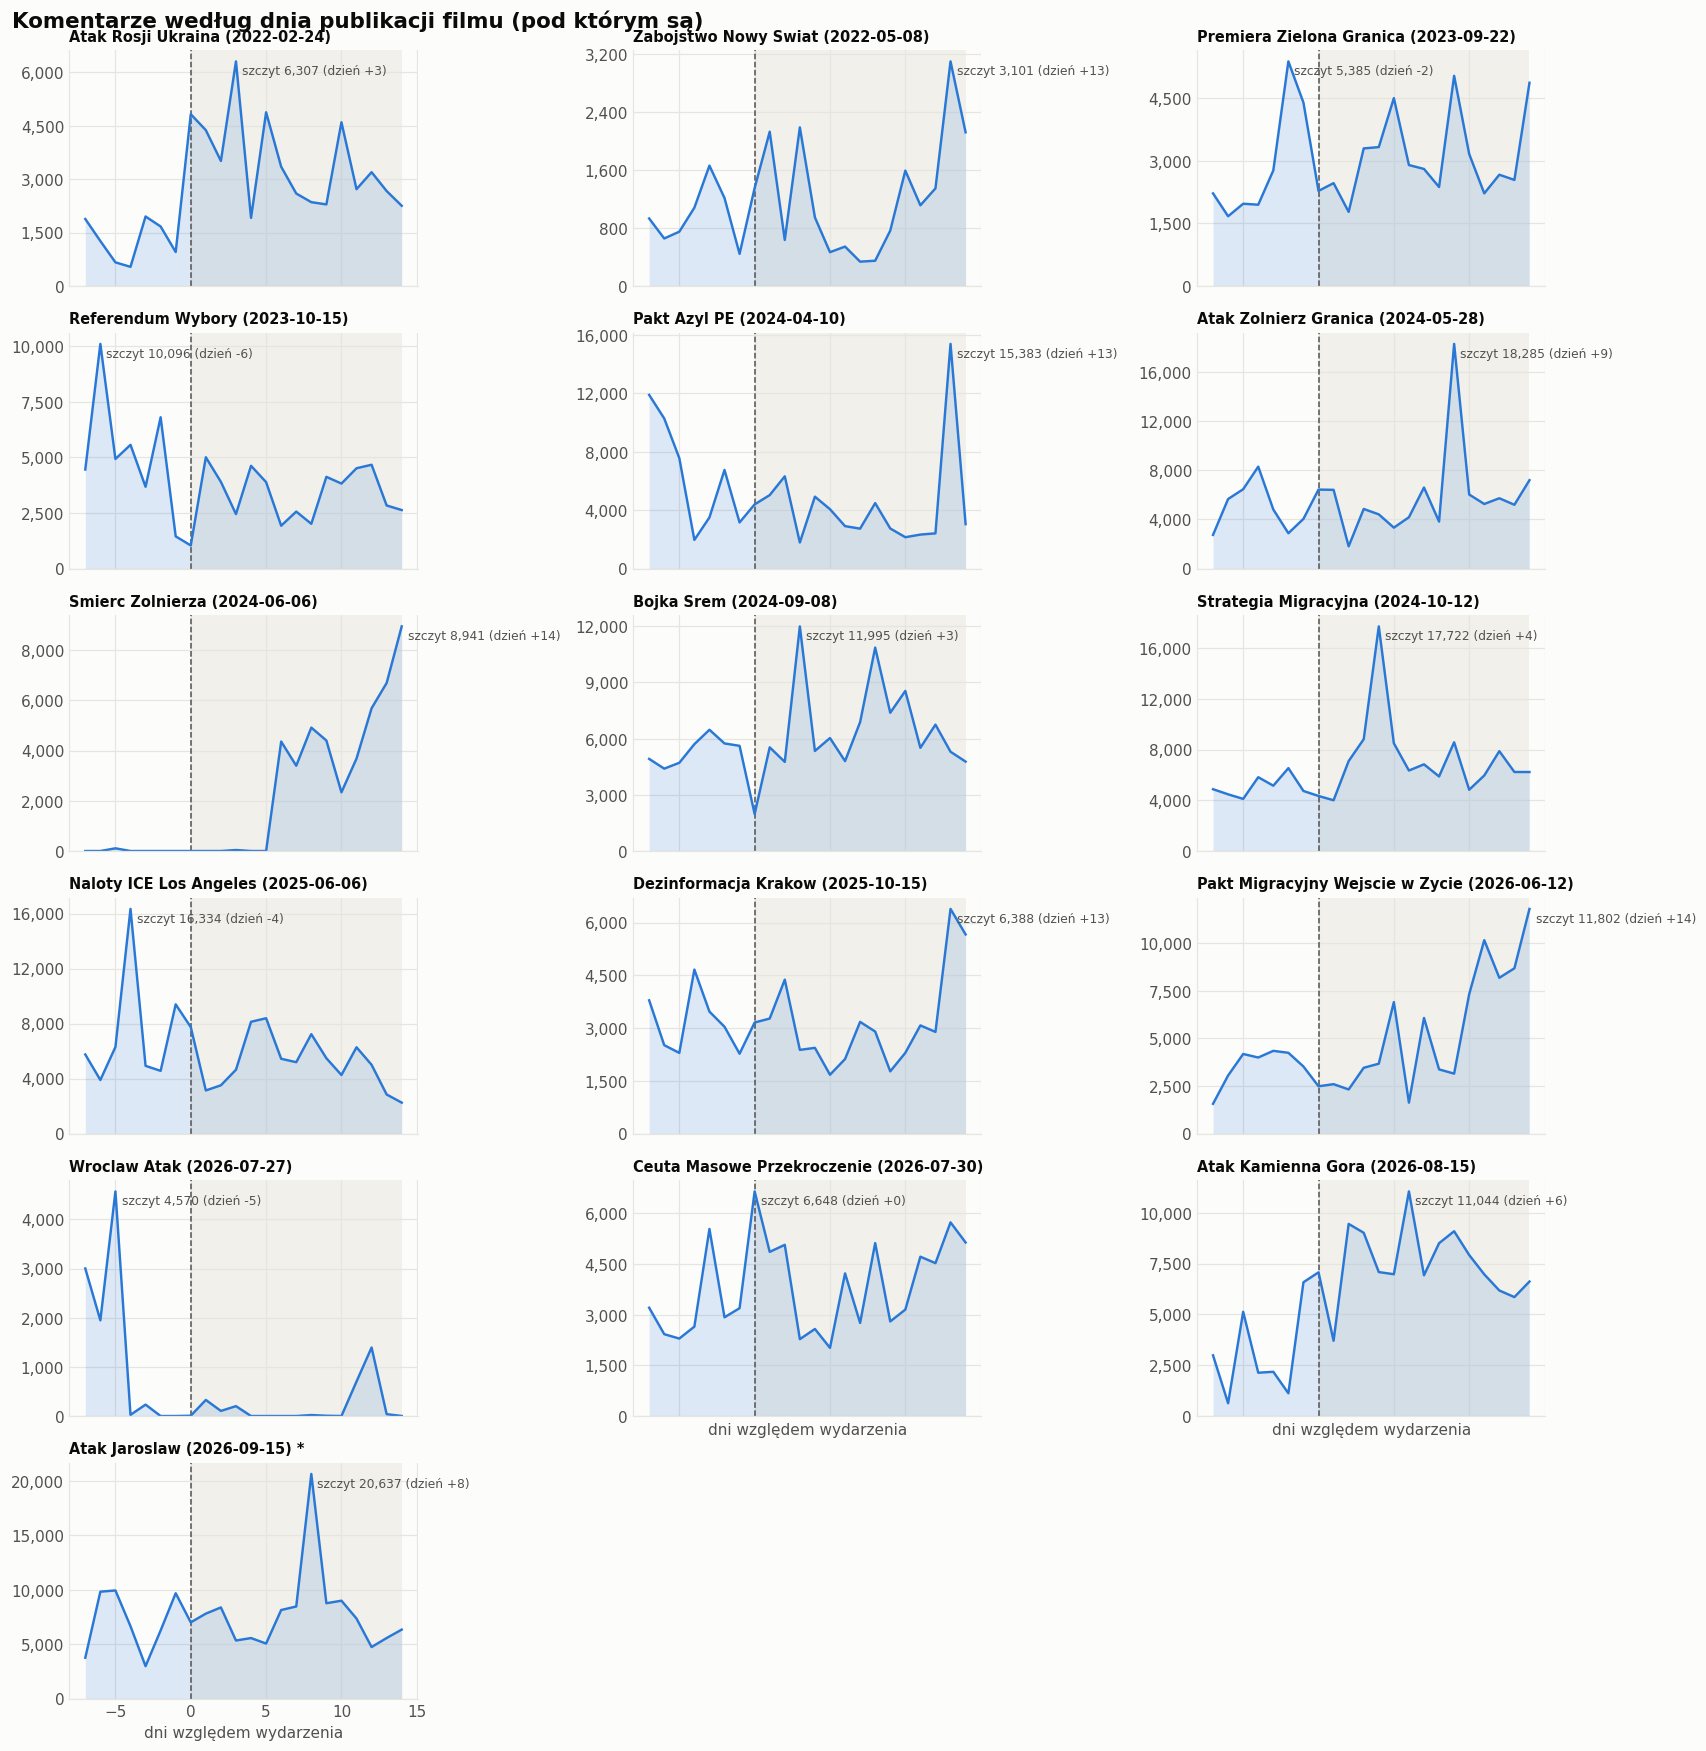

In [90]:
comments_by_video_day = daily_counts(df, 'video_rel_day', -WINDOW_BEFORE, WINDOW_AFTER)
savefig(timeline_grid(comments_by_video_day, 'Komentarze według dnia publikacji filmu (pod którym są)', WINDOW_AFTER),
        '04_comments_by_video_day')

### 3.2 Komentarze według dnia, w którym zostały napisane

To obraz reakcji widowni w czasie. Komentarze pod filmami z końca okna wychodzą poza +14 dni (aż do
`WINDOW_AFTER + MAX_AGE_DAYS`).

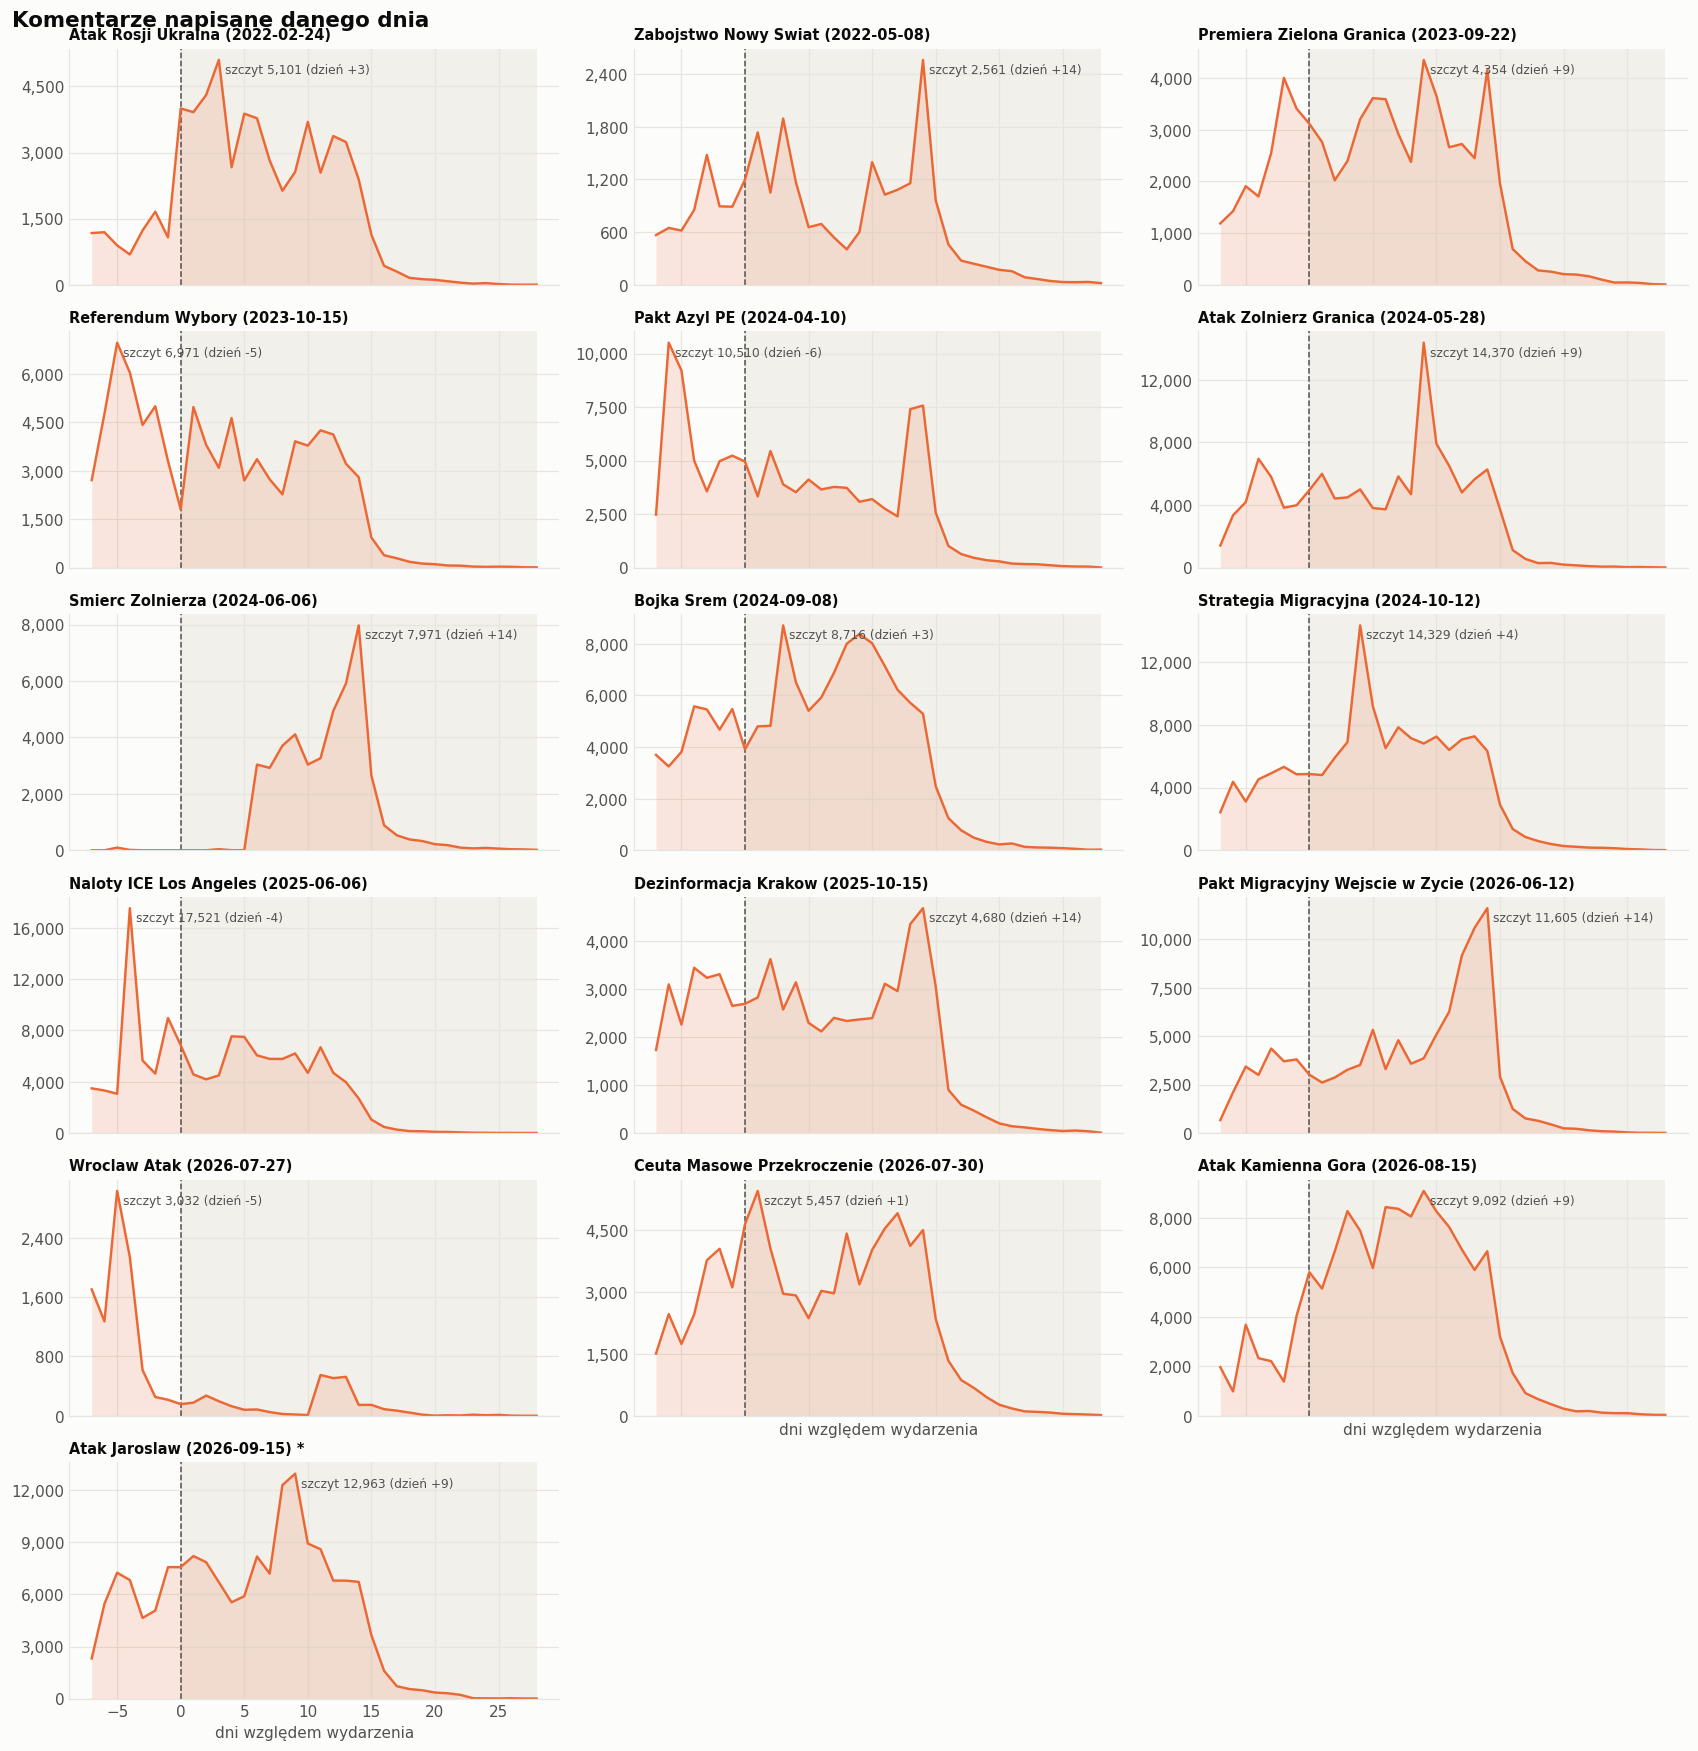

In [91]:
comments_by_day = daily_counts(df, 'comment_rel_day', -WINDOW_BEFORE, COMMENT_HI)
savefig(timeline_grid(comments_by_day, 'Komentarze napisane danego dnia', COMMENT_HI, color=SERIES[1]),
        '05_comments_by_comment_day')

### 3.3 Przed vs po wydarzeniu

Faza dotyczy **filmu**: `before` – film opublikowany przed dniem wydarzenia, `day_0` – w dniu wydarzenia,
`after` – po. Porównanie jest uczciwe tylko dzięki stałemu oknu wieku komentarzy (`MAX_AGE_DAYS`), inaczej starsze
filmy miałyby więcej czasu na zebranie komentarzy.

In [92]:
def phase_stats(e):
    v = videos[videos.event_name == e]
    d = df[df.event_name == e]
    b, a, d0 = (v[v.video_phase == p] for p in ('before', 'day_0', 'after'))
    db, da = (d[d.video_phase == p] for p in ('before', 'after'))
    def ratio(x, y):
        return (x / y - 1) * 100 if y and y > 0 else np.nan
    cpv_b = b['comments'].mean() if len(b) else np.nan
    cpv_a = a['comments'].mean() if len(a) else np.nan
    return pd.Series({
        'videos/day before': len(b) / WINDOW_BEFORE,
        'videos day 0': len(d0),
        'videos/day after': len(a) / WINDOW_AFTER,
        'comments/video before': cpv_b,
        'comments/video after': cpv_a,
        'comments/video after vs before %': ratio(cpv_a, cpv_b),
        'likes/comment before': db['like_count'].mean(),
        'likes/comment after': da['like_count'].mean(),
        'migr share before %': db['is_migr'].mean() * 100 if len(db) else np.nan,
        'migr share after %': da['is_migr'].mean() * 100 if len(da) else np.nan,
        'migr share change pp': (da['is_migr'].mean() - db['is_migr'].mean()) * 100 if len(db) and len(da) else np.nan,
        'n comments before': len(db), 'n comments after': len(da),
    })

lift = pd.DataFrame({e: phase_stats(e) for e in EVENTS}).T
lift.index.name = 'event'
lift.round(2)

,videos/day before,videos day 0,videos/day after,comments/video before,comments/video after,comments/video after vs before %,likes/comment before,likes/comment after,migr share before %,migr share after %,migr share change pp,n comments before,n comments after
event,,,,,,,,,,,,,
Atak_Rosji_Ukraina,20.29,498.0,2.29,62.84,150.75,139.90,6.15,6.31,2.17,3.85,1.68,8923.0,47019.0
Zabojstwo_Nowy_Swiat,20.29,293.0,2.21,47.46,43.65,-8.05,7.37,10.64,2.45,1.37,-1.08,6740.0,17775.0
Premiera_Zielona_Granica,23.29,311.0,1.64,124.94,99.13,-20.66,8.70,9.01,5.61,4.84,-0.77,20366.0,44016.0
Referendum_Wybory,37.29,470.0,0.86,141.55,86.33,-39.01,10.55,9.29,2.93,3.16,0.23,36945.0,48897.0
Pakt_Azyl_PE,24.86,322.0,1.36,259.14,231.11,-10.82,13.87,12.41,1.12,2.41,1.29,45090.0,60255.0
Atak_Zolnierz_Granica,29.14,345.0,2.14,170.87,214.17,25.34,11.54,12.16,2.40,8.51,6.11,34858.0,83039.0
Smierc_Zolnierza,0.14,232.0,0.00,107.00,NaN,NaN,8.98,11.85,5.61,8.07,2.46,107.0,44487.0
Bojka_Srem,37.14,587.0,1.43,144.51,98.80,-31.63,10.31,10.96,1.61,1.72,0.10,37572.0,94485.0
Strategia_Migracyjna,43.86,585.0,2.71,116.34,114.29,-1.76,11.50,11.52,1.34,2.81,1.47,35715.0,105121.0


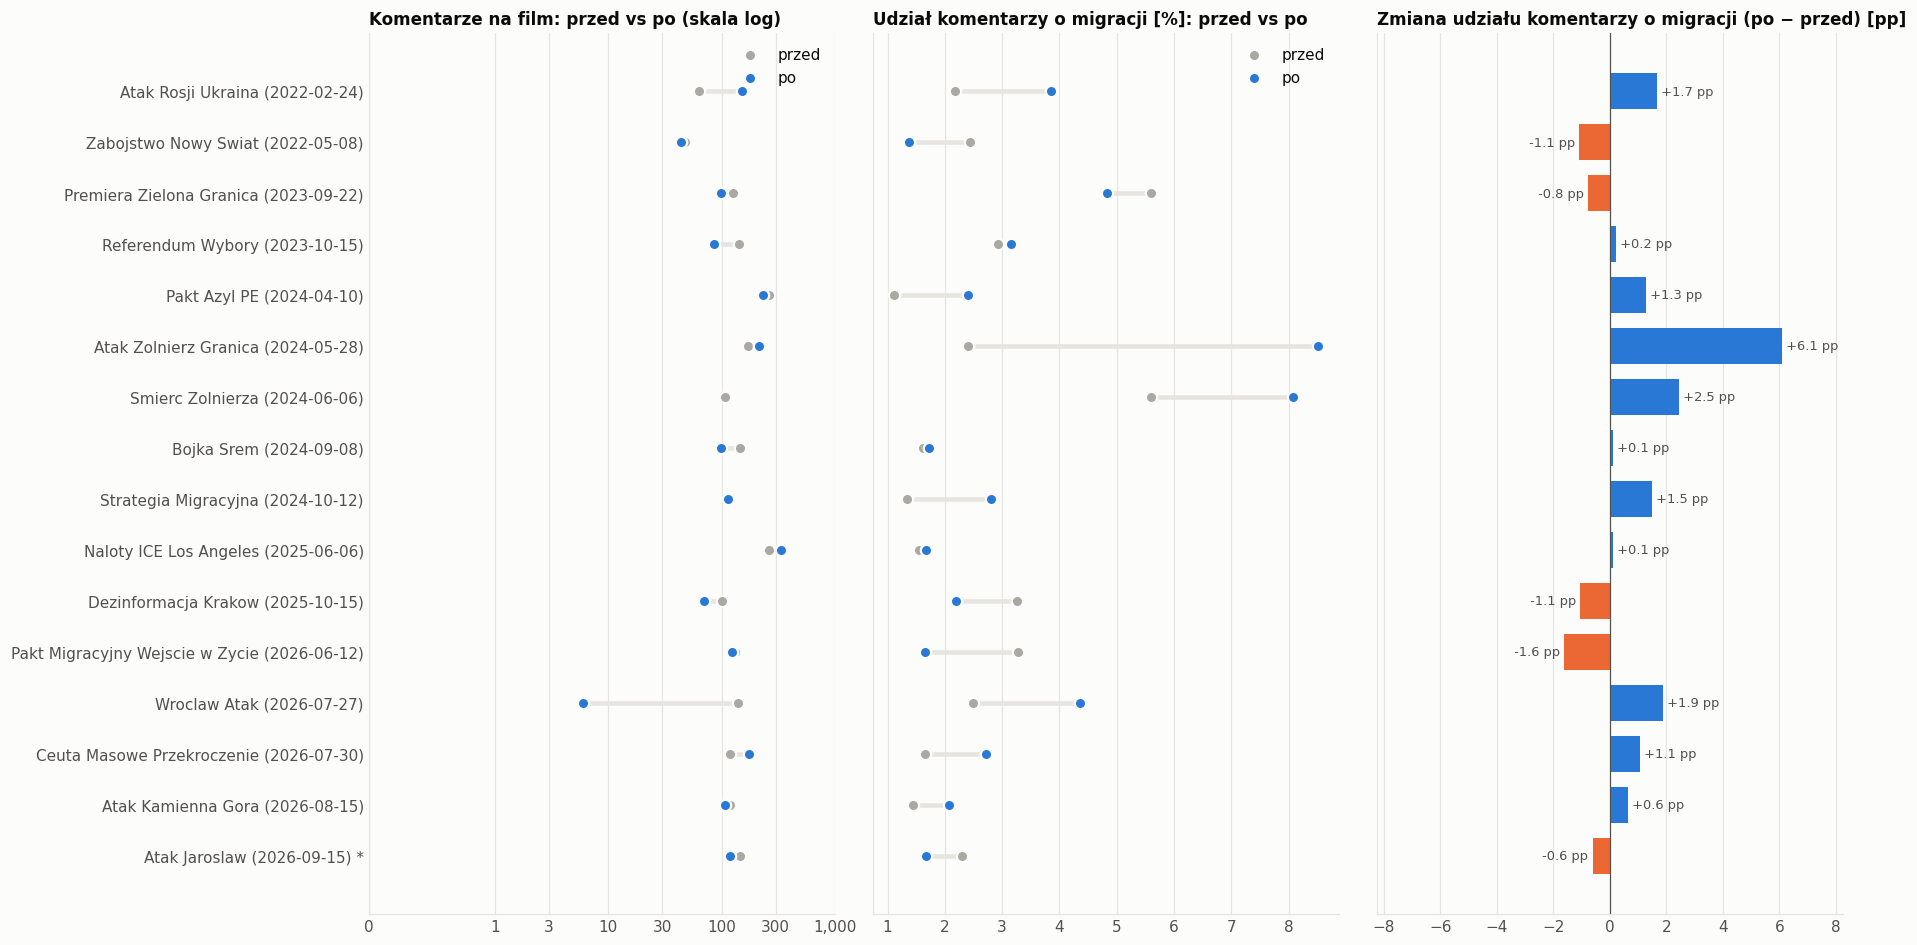

In [93]:
fig, axes = plt.subplots(1, 3, figsize=(17, 0.45 * len(EVENTS) + 1.5), sharey=True)
y = np.arange(len(EVENTS))
for ax, (b, a, title, log) in zip(axes[:2], [
        ('comments/video before', 'comments/video after', 'Komentarze na film: przed vs po (skala log)', True),
        ('migr share before %', 'migr share after %', 'Udział komentarzy o migracji [%]: przed vs po', False)]):
    bv, av = lift[b].values.astype(float), lift[a].values.astype(float)
    ax.hlines(y, np.fmin(bv, av), np.fmax(bv, av), color=GRID, lw=3)
    ax.scatter(bv, y, s=55, color=NEUTRAL, label='przed', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(av, y, s=55, color=SERIES[0], label='po', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    if log:
        ax.set_xscale('symlog', linthresh=1)
        ax.set_xticks([0, 1, 3, 10, 30, 100, 300, 1000])
        ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
        ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
    ax.legend(loc='upper right')
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis()

ch = lift['migr share change pp'].astype(float).values
axes[2].barh(y, np.nan_to_num(ch), color=np.where(ch >= 0, POS, NEG), height=0.7)
axes[2].axvline(0, color=TEXT_SECONDARY, lw=0.8)
for yi, v in zip(y, ch):
    if pd.notna(v):
        axes[2].text(v, yi, f' {v:+.1f} pp ', va='center', ha='left' if v >= 0 else 'right',
                     fontsize=8.5, color=TEXT_SECONDARY)
axes[2].set_title('Zmiana udziału komentarzy o migracji (po − przed) [pp]')
axes[2].grid(axis='y', visible=False)
pad = max(np.nanmax(np.abs(ch)) * 1.35, 1) if np.isfinite(ch).any() else 1
axes[2].set_xlim(-pad, pad)
fig.tight_layout()
savefig(fig, '06_before_after')

### 3.4 Wiek komentarzy – jak szybko komentarze się pojawiają

Rozkład wieku komentarza (dni od publikacji filmu) w **pełnym** pliku, przed zastosowaniem `MAX_AGE_DAYS`.
Pokazuje, ile informacji obcina filtr i jak szybko "wygasa" dyskusja pod filmem.

W pełnym pliku 100.0% komentarzy ma ≤ 14 dni.


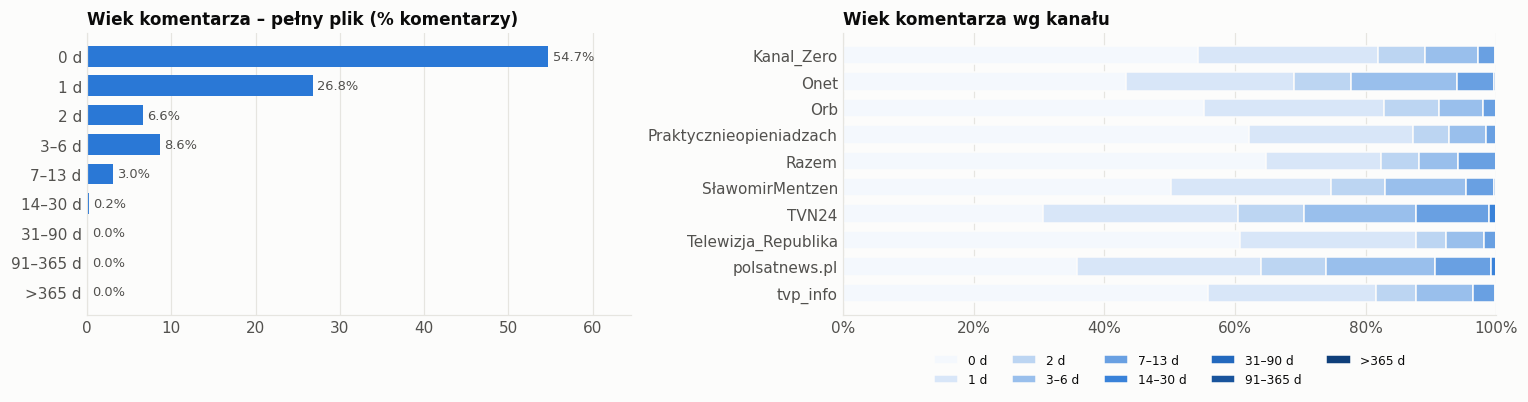

In [94]:
bins = [-1, 0, 1, 2, 6, 13, 30, 90, 365, 10**6]
names = ['0 d', '1 d', '2 d', '3–6 d', '7–13 d', '14–30 d', '31–90 d', '91–365 d', '>365 d']
age = pd.cut(df_full['days_since_video'], bins=bins, labels=names)
age_share = (age.value_counts(normalize=True).reindex(names) * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 1.2]})
hbar(axes[0], age_share, names, SERIES[0], fmt='{:.1f}%')
axes[0].set_title('Wiek komentarza – pełny plik (% komentarzy)')

ch_age = df_full.assign(age=age).groupby(['channel_name', 'age'], observed=False).size().unstack(fill_value=0).reindex(columns=names)
ch_age = ch_age.div(ch_age.sum(axis=1), axis=0) * 100
left = np.zeros(len(ch_age)); yy = np.arange(len(ch_age))
cols = [SEQ(i / (len(names) - 1)) for i in range(len(names))]
for n, c in zip(names, cols):
    axes[1].barh(yy, ch_age[n].values, left=left, color=c, height=0.7, edgecolor=SURFACE, linewidth=1, label=n)
    left += ch_age[n].values
axes[1].set_yticks(yy, ch_age.index); axes[1].invert_yaxis(); axes[1].grid(axis='y', visible=False)
axes[1].set_xlim(0, 100); axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_title('Wiek komentarza wg kanału'); axes[1].legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=8)
fig.tight_layout()
savefig(fig, '07_comment_age')
print(f'W pełnym pliku {(df_full.days_since_video <= (MAX_AGE_DAYS or 0)).mean() * 100:.1f}% komentarzy ma ≤ {MAX_AGE_DAYS} dni.')

## 4. Słowa kluczowe

Słowa kluczowe (`KEYWORDS`, sekcja 1) są dopasowywane po **rdzeniu słowa** w treści komentarza, więc komentarz
może pasować do kilku naraz. Komentarz „o migracji” (`is_migr`) to taki, który pasuje do dowolnego słowa z `CORE_KEYS`.

### 4.1 Które słowa dominują?

Filmy z danym słowem w tytule: {'Ukraina / Ukraińcy': 550, 'wojna': 248, 'granica': 158, 'migrant / imigrant': 93, 'pakt': 43, 'uchodźc*': 29, 'socjal / 800+': 8, 'relokacja': 7, 'azyl': 6, 'deportacja': 6, 'islam / muzułmanie': 6, 'obcokrajowcy': 3, 'cudzoziemcy': 2}


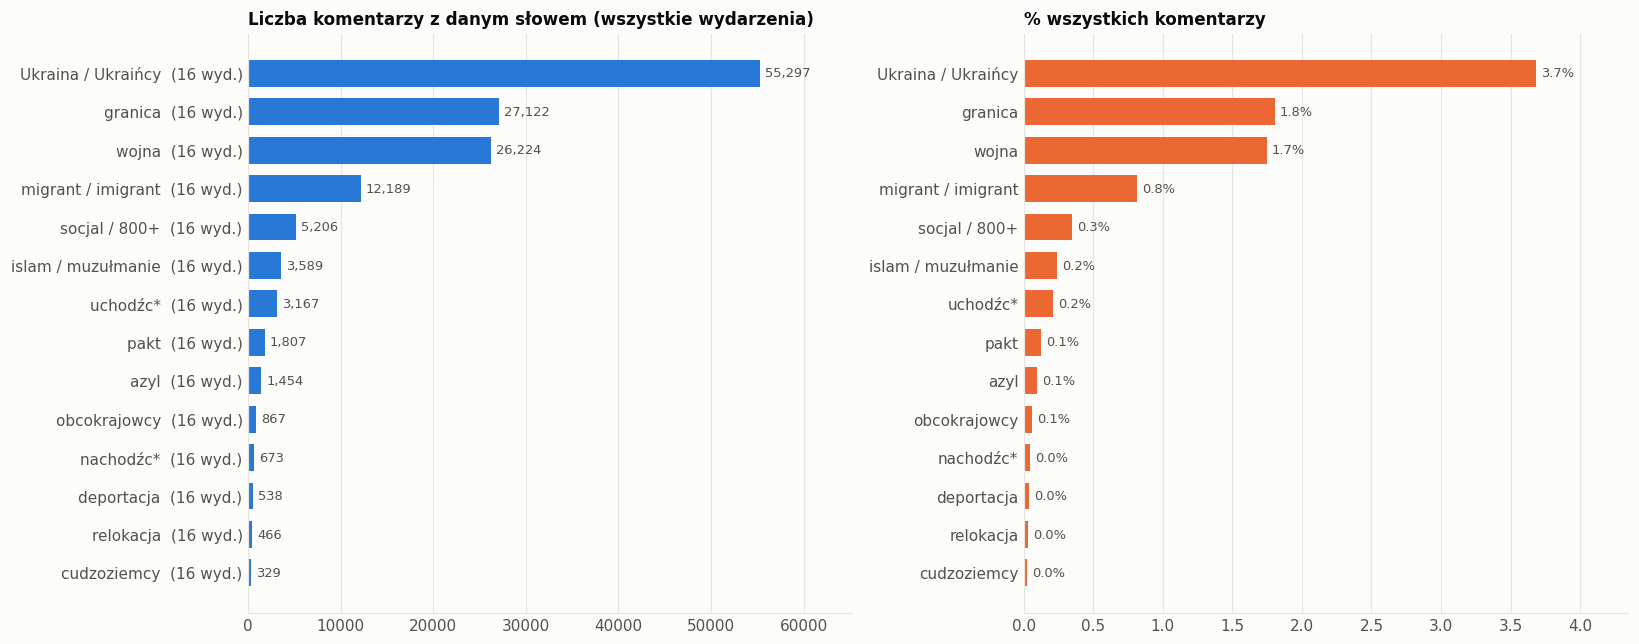

In [95]:
kw_total = KWM.sum().sort_values(ascending=False)
kw_pct = kw_total / len(df) * 100
kw_events = {k: df.loc[KWM[k], 'event_name'].nunique() for k in KWM.columns}

fig, axes = plt.subplots(1, 2, figsize=(15, 0.34 * len(kw_total) + 1.2))
hbar(axes[0], kw_total, [f'{k}  ({kw_events[k]} wyd.)' for k in kw_total.index])
axes[0].set_title('Liczba komentarzy z danym słowem (wszystkie wydarzenia)')
hbar(axes[1], kw_pct, kw_pct.index, color=SERIES[1], fmt='{:.1f}%')
axes[1].set_title('% wszystkich komentarzy')
fig.tight_layout()
savefig(fig, '08_keywords_global')

titles_lc = videos['video_title'].str.lower()
tkw = {k: int(titles_lc.str.contains(rx).sum()) for k, rx in KEYWORDS.items()}
print('Filmy z danym słowem w tytule:', {k: v for k, v in sorted(tkw.items(), key=lambda kv: -kv[1]) if v})

### 4.2 Profil słów kluczowych każdego wydarzenia

Udział komentarzy wydarzenia zawierających słowo (%). Normalizacja per wydarzenie umożliwia porównanie dużych i małych.

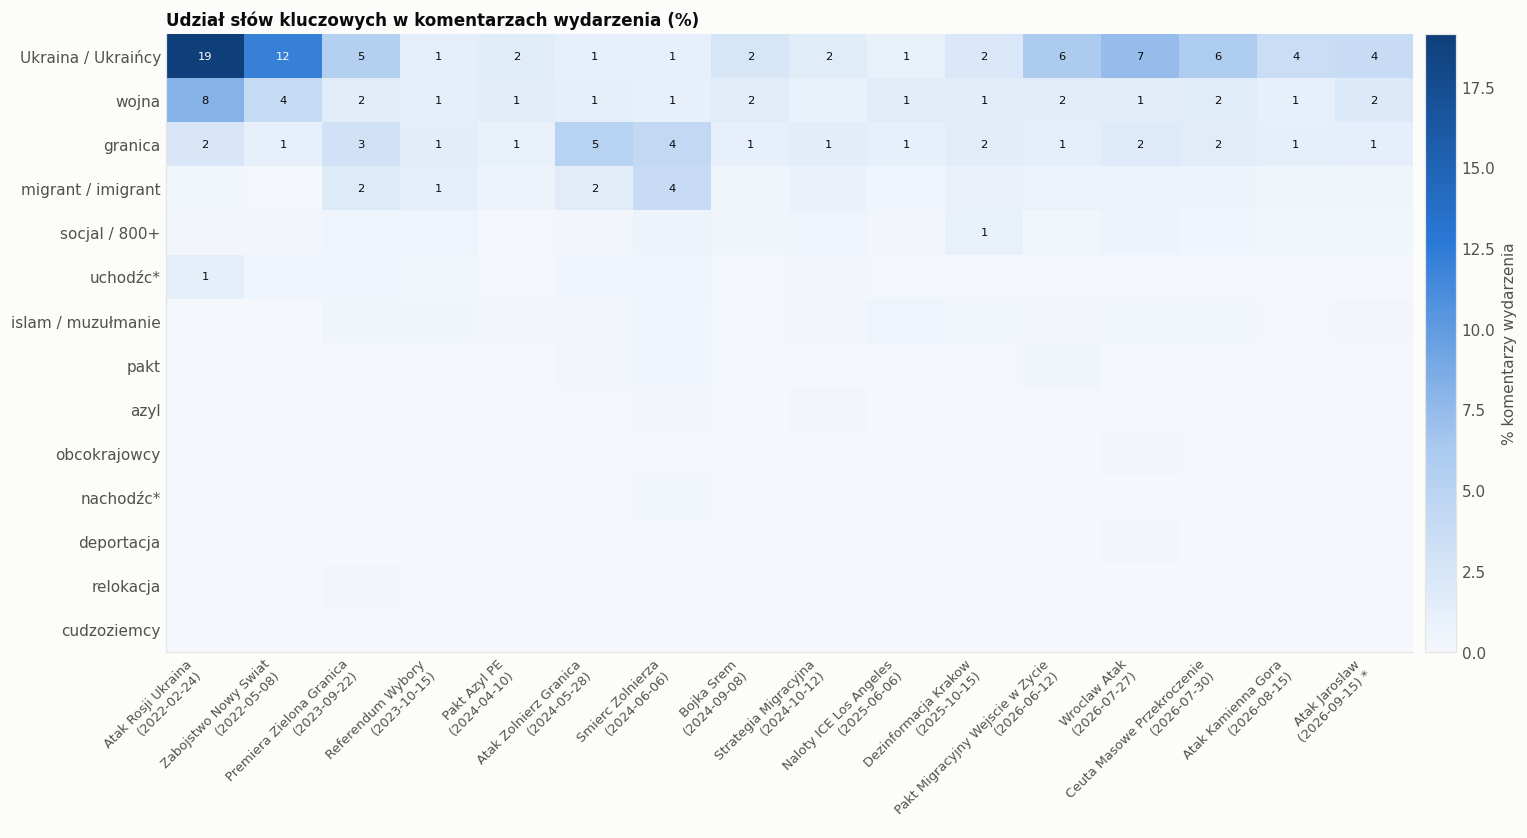

In [96]:
kw_share = (KWM.groupby(df['event_name']).mean() * 100).reindex(EVENTS).T
kw_share = kw_share.loc[kw_share.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 0.38 * len(kw_share) + 2.4))
im = ax.imshow(kw_share.values, aspect='auto', cmap=SEQ, vmin=0)
ax.set_yticks(range(len(kw_share)), kw_share.index)
ax.set_xticks(range(len(EVENTS)), [l.replace(' (', '\n(') for l in LABELS], rotation=45, ha='right', fontsize=8.5)
ax.grid(False)
vmax = kw_share.values.max()
for i in range(kw_share.shape[0]):
    for j in range(kw_share.shape[1]):
        v = kw_share.iat[i, j]
        if v >= 1:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5,
                    color='white' if v > vmax * 0.55 else TEXT_PRIMARY)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label('% komentarzy wydarzenia')
ax.set_title('Udział słów kluczowych w komentarzach wydarzenia (%)')
fig.tight_layout()
savefig(fig, '09_keyword_event_heatmap')

,komentarze,filmy,migr_pct
typ_filmu,,,
film o migracji,63232,280,14.33
inny film,1438601,10285,2.34


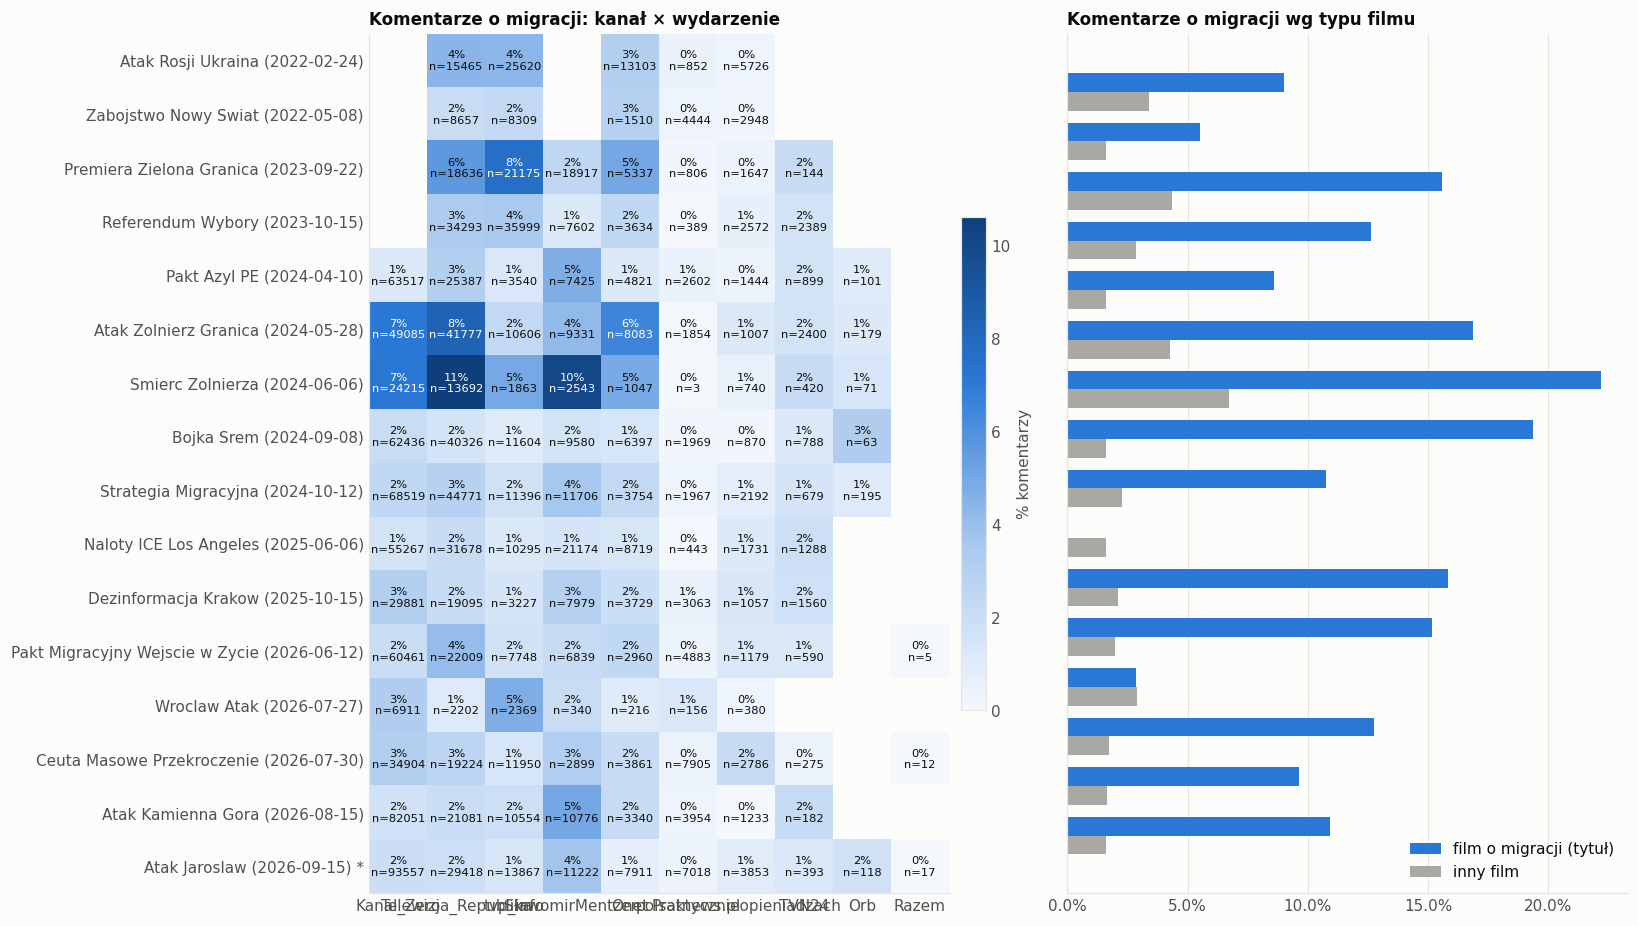

In [97]:
# Udział komentarzy o migracji: kanał x wydarzenie oraz typ filmu
mig_ch = (df.groupby(['event_name', 'channel_name'])['is_migr'].mean().unstack() * 100).reindex(index=EVENTS, columns=CHANNELS)
n_ch = df.groupby(['event_name', 'channel_name']).size().unstack().reindex(index=EVENTS, columns=CHANNELS)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(EVENTS) + 1.8), gridspec_kw={'width_ratios': [1.1, 1]})
vals = np.ma.masked_invalid(mig_ch.values.astype(float))
im = axes[0].imshow(vals, aspect='auto', cmap=SEQ, vmin=0)
axes[0].set_xticks(range(len(CHANNELS)), CHANNELS)
axes[0].set_yticks(range(len(EVENTS)), LABELS)
axes[0].grid(False)
vmax = np.nanmax(mig_ch.values) if np.isfinite(mig_ch.values).any() else 1
for i in range(len(EVENTS)):
    for j in range(len(CHANNELS)):
        v = mig_ch.iat[i, j]
        if pd.notna(v):
            axes[0].text(j, i, f'{v:.0f}%\nn={int(n_ch.iat[i, j])}', ha='center', va='center', fontsize=7.5,
                         color='white' if v > vmax * 0.55 else TEXT_PRIMARY)
axes[0].set_title('Komentarze o migracji: kanał × wydarzenie')
fig.colorbar(im, ax=axes[0], fraction=0.04, pad=0.02, label='% komentarzy')

typ = df.groupby(['event_name', 'typ_filmu'])['is_migr'].mean().unstack().reindex(EVENTS) * 100
typ = typ.reindex(columns=['film o migracji', 'inny film'])
yy = np.arange(len(EVENTS)); h = 0.38
axes[1].barh(yy - h / 2, typ['film o migracji'].fillna(0), height=h, color=SERIES[0], label='film o migracji (tytuł)')
axes[1].barh(yy + h / 2, typ['inny film'].fillna(0), height=h, color=NEUTRAL, label='inny film')
axes[1].set_yticks(yy, [''] * len(EVENTS)); axes[1].invert_yaxis(); axes[1].grid(axis='y', visible=False)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_title('Komentarze o migracji wg typu filmu'); axes[1].legend(loc='lower right')
fig.tight_layout()
savefig(fig, '10_migration_share')

t_summary = df.groupby('typ_filmu').agg(komentarze=('text', 'size'), filmy=('video_id', 'nunique'),
                                        migr_pct=('is_migr', lambda s: round(s.mean() * 100, 2)))
t_summary

### 4.3 Osie czasu słów kluczowych per wydarzenie

Dla każdego wydarzenia:
* **lewy panel** – najczęstsze słowa (% komentarzy wydarzenia),
* **prawy panel** – liczba komentarzy z `TOP_LINES` najczęstszymi słowami w kolejnych dniach (dzień napisania komentarza).

Zmień `TOP_BAR`, `TOP_LINES` lub `SMOOTH` (okno średniej kroczącej w dniach, 1 = surowe dane).

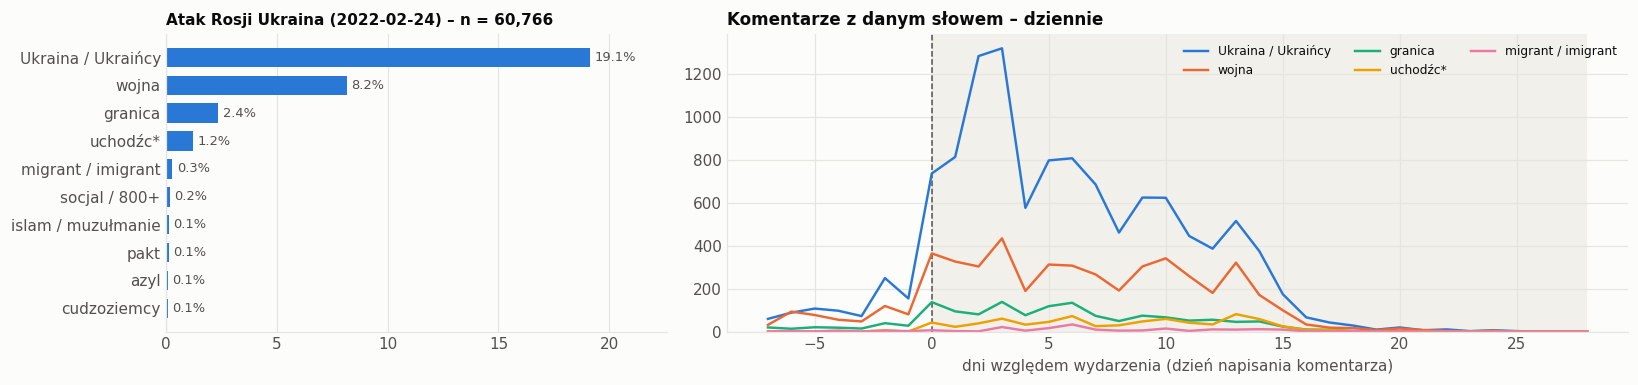

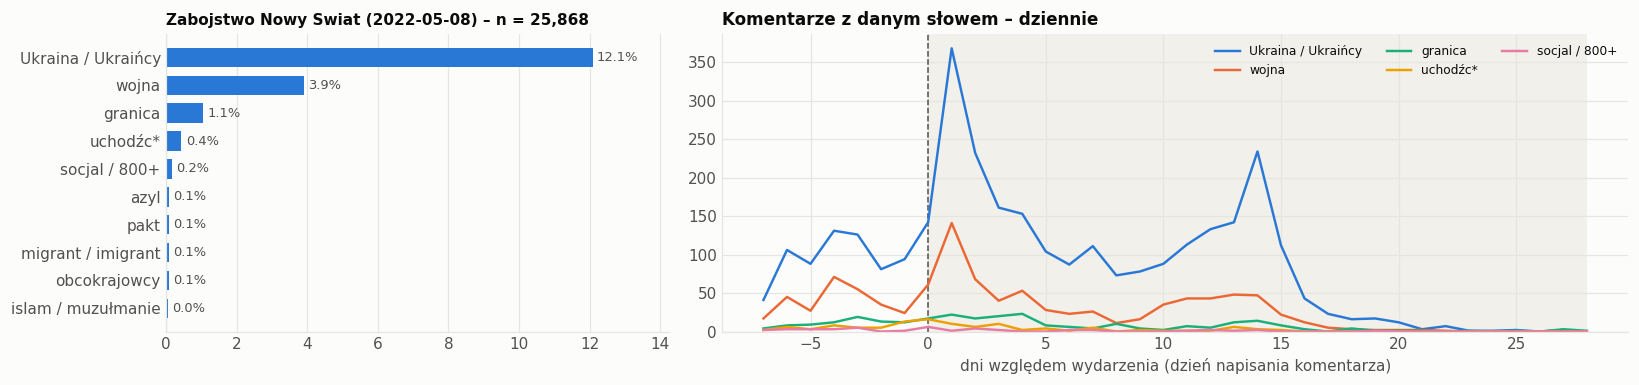

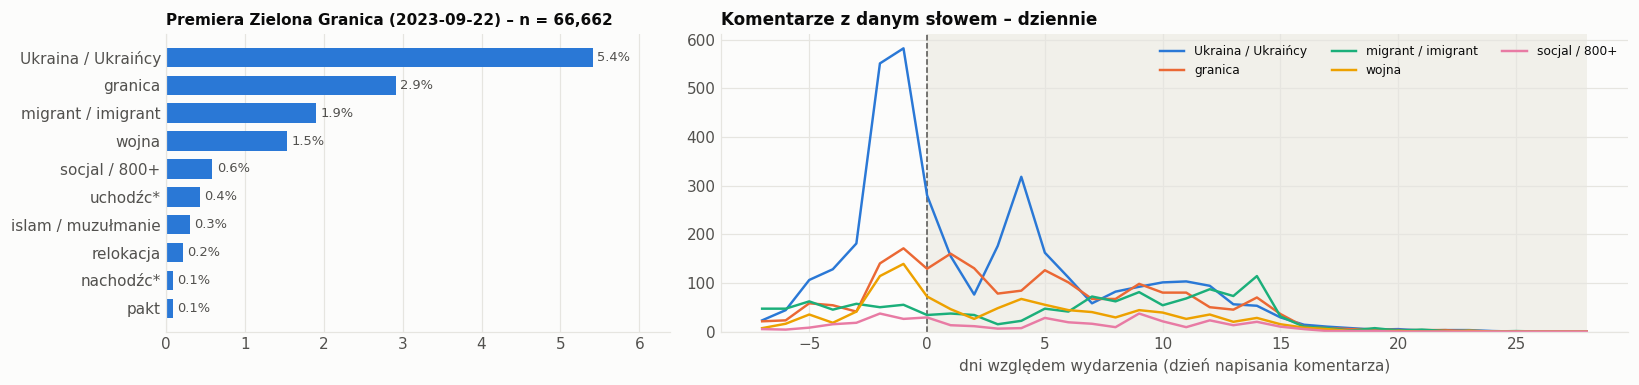

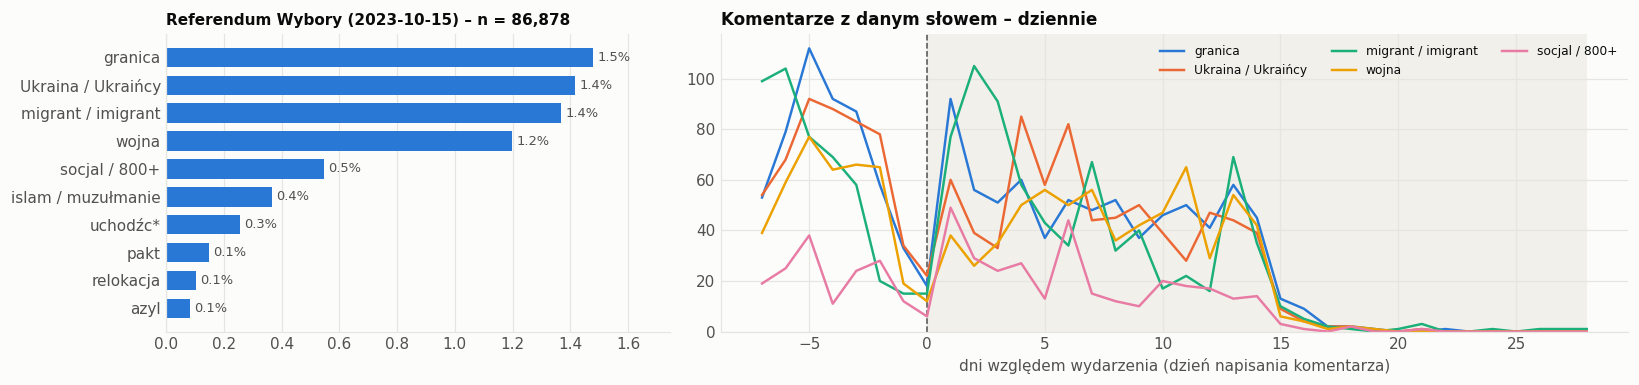

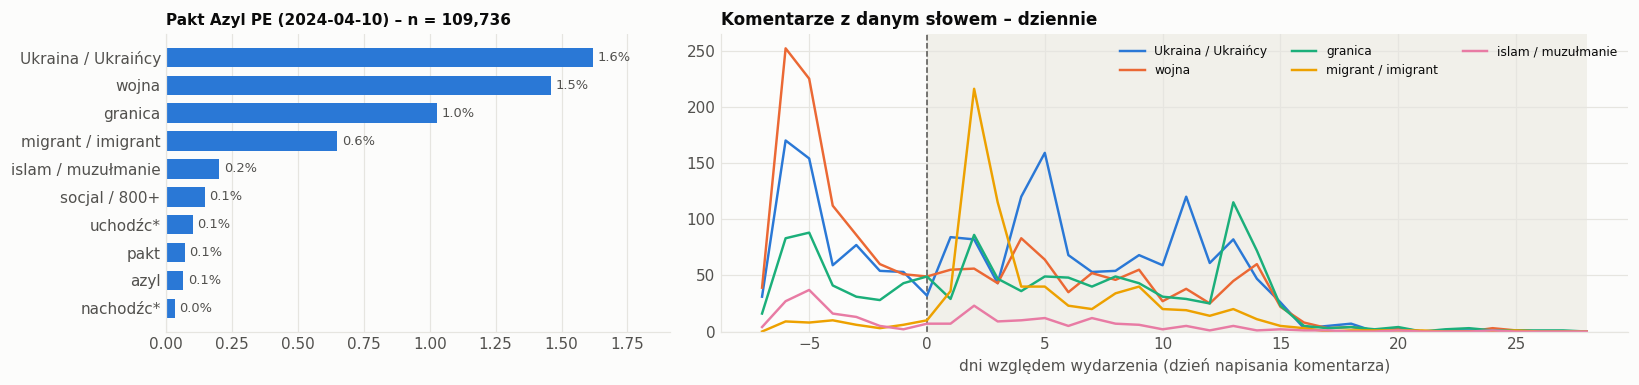

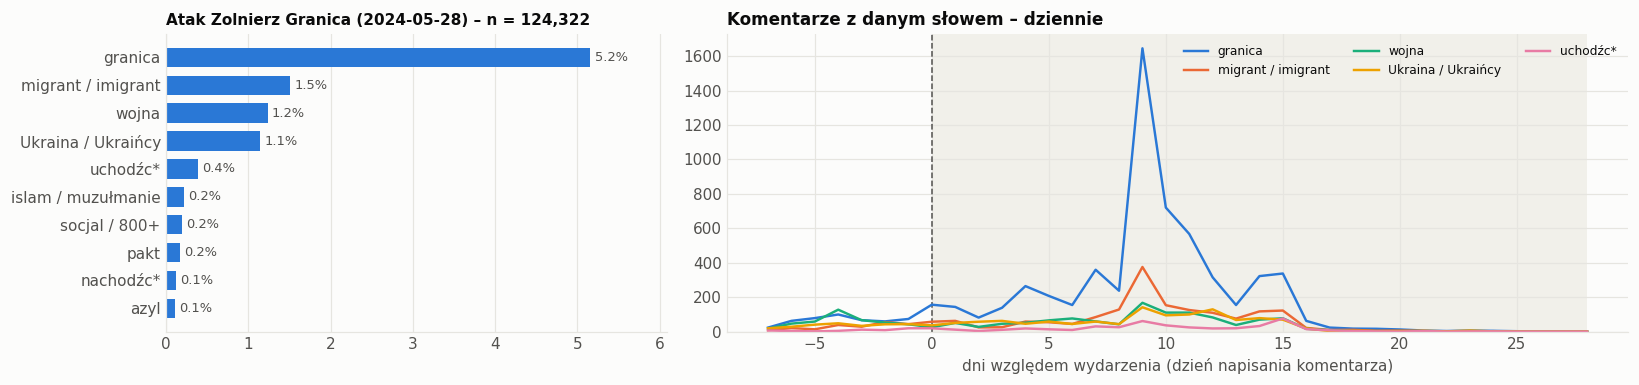

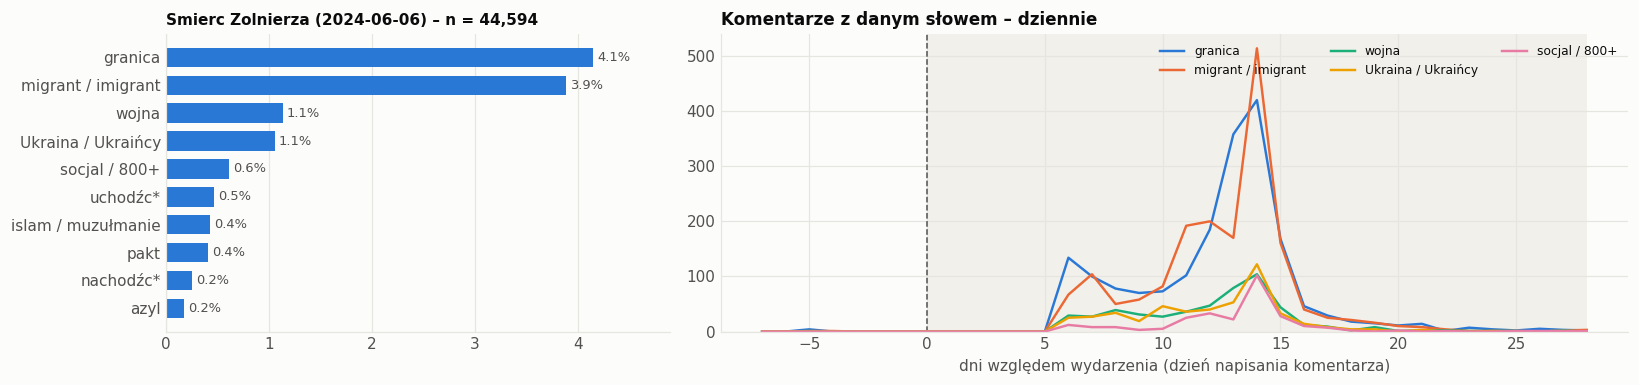

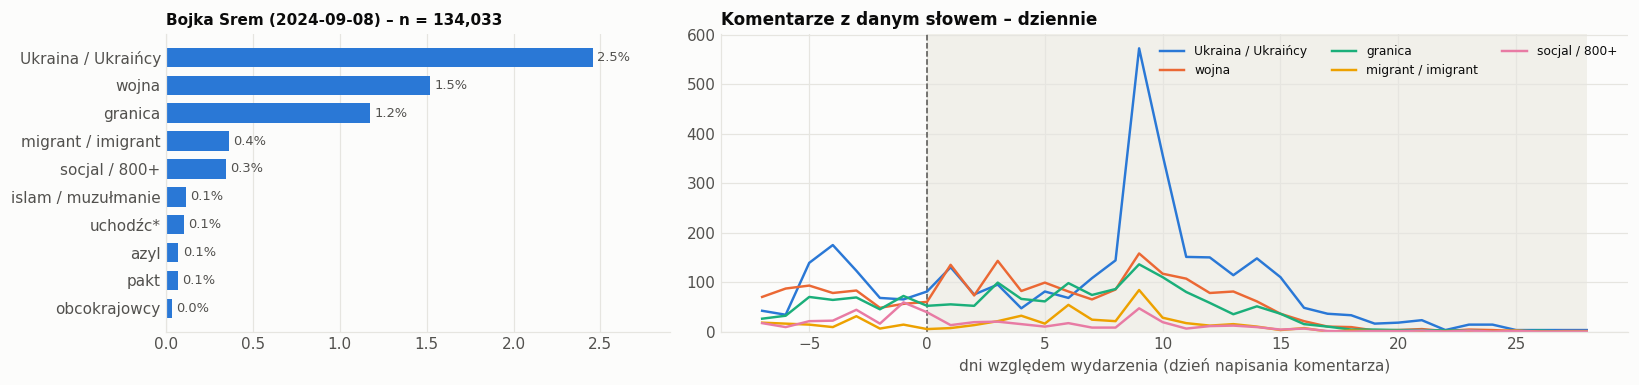

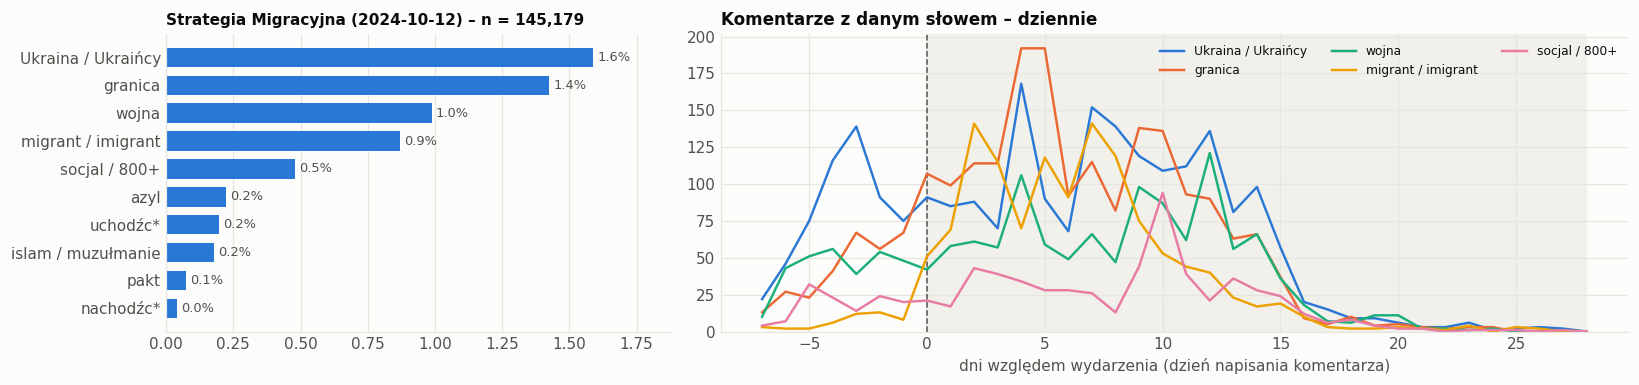

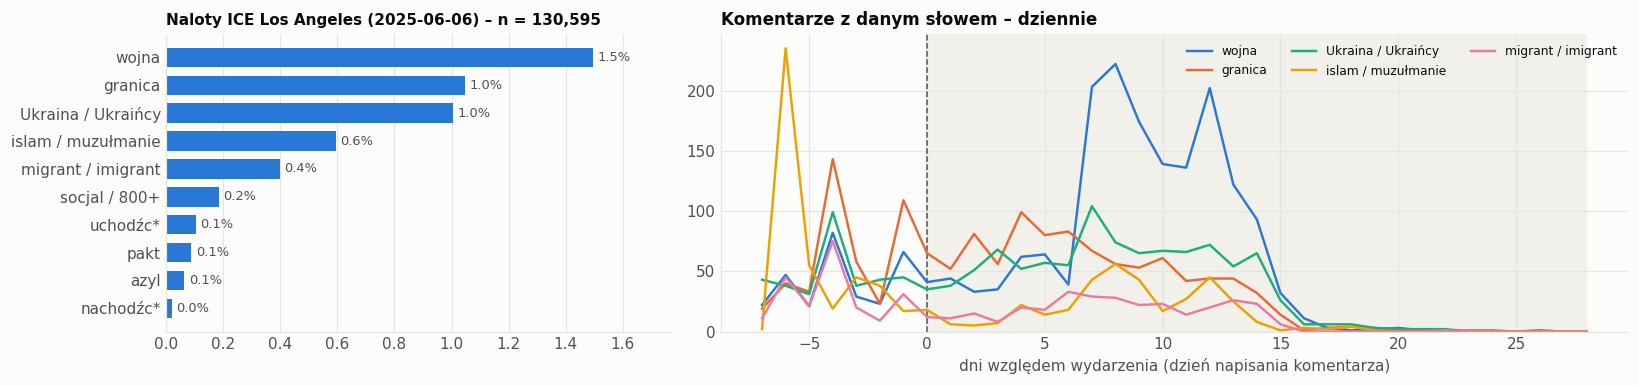

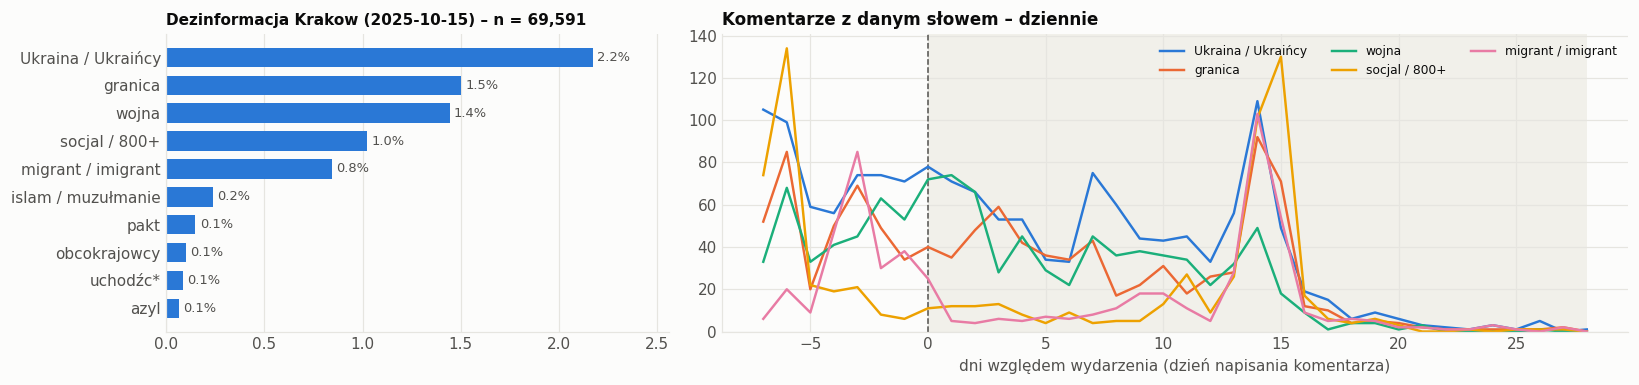

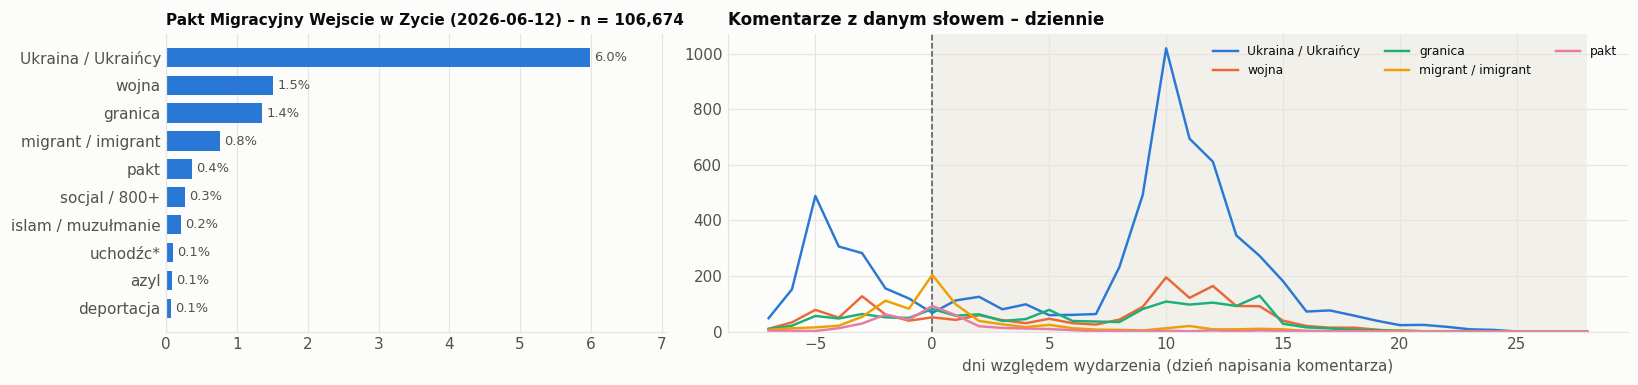

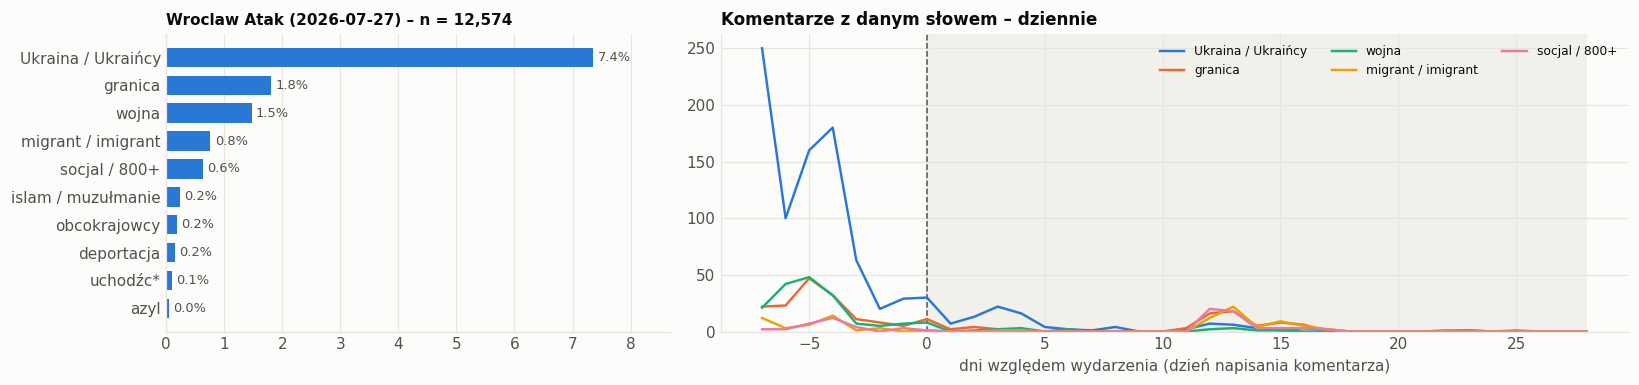

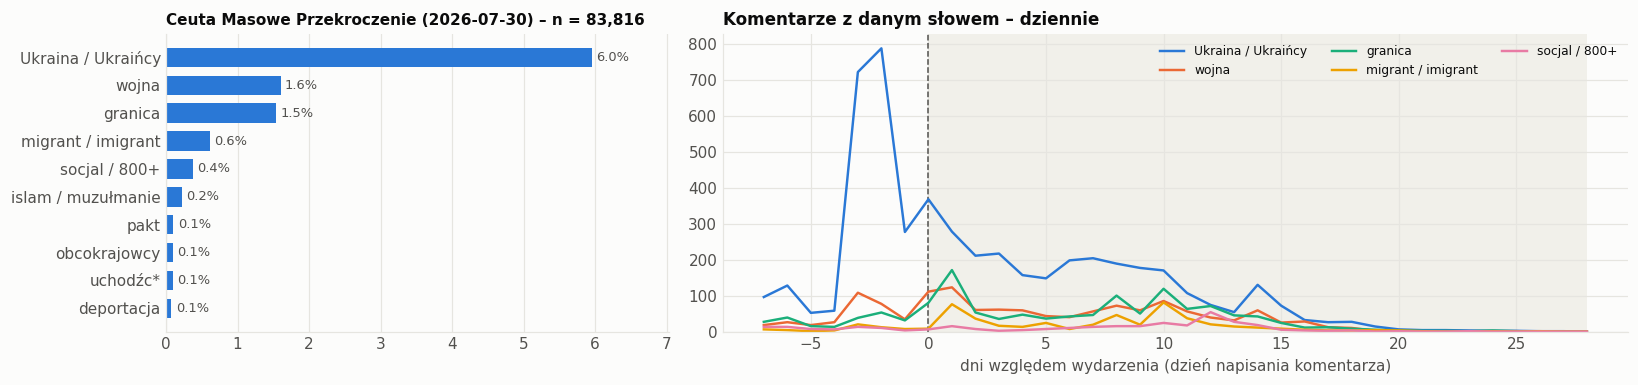

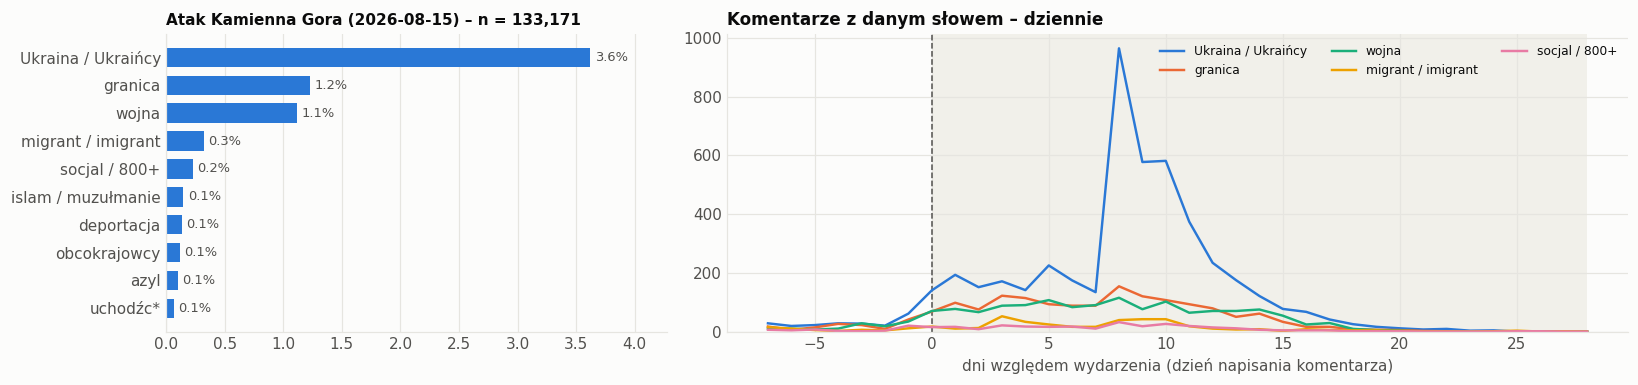

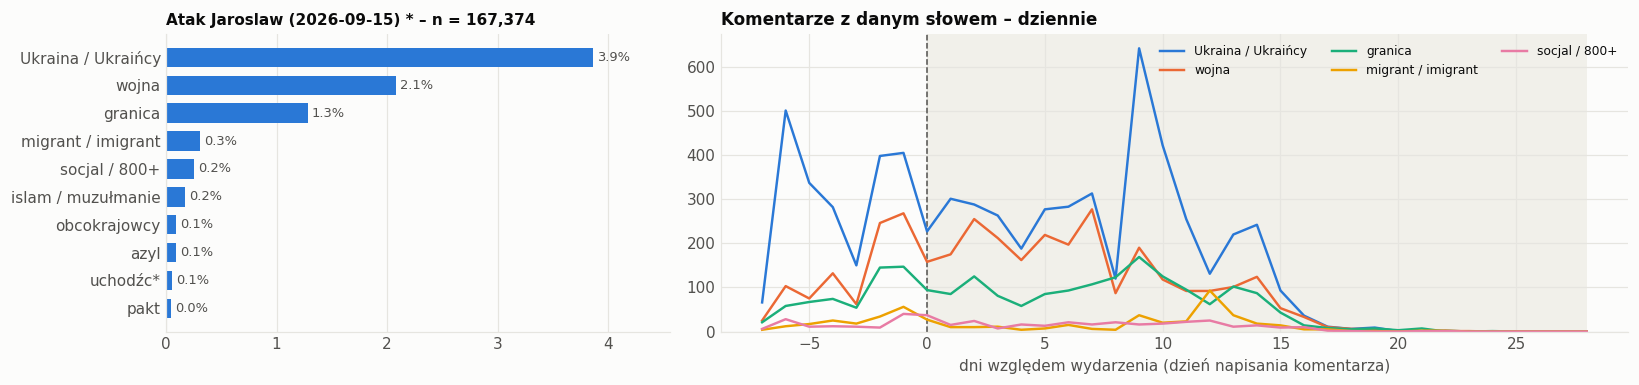

In [98]:
TOP_BAR, TOP_LINES, SMOOTH = 10, 5, 1

for e in EVENTS:
    d = df[df.event_name == e]
    k = KWM.loc[d.index]
    totals = k.sum().sort_values(ascending=False)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={'width_ratios': [1, 1.8]})
    top = totals.head(TOP_BAR)
    hbar(a1, top / len(d) * 100, top.index, fmt='{:.1f}%')
    a1.set_title(f'{LABEL[e]} – n = {len(d):,}', fontsize=10)

    names = list(totals.head(TOP_LINES).index)
    daily_kw = (k[names].groupby(d['comment_rel_day']).sum()
                .reindex(range(-WINDOW_BEFORE, COMMENT_HI + 1), fill_value=0))
    if SMOOTH > 1:
        daily_kw = daily_kw.rolling(SMOOTH, center=True, min_periods=1).mean()
    mark_event_day(a2, COMMENT_HI)
    for i, nme in enumerate(names):
        a2.plot(daily_kw.index, daily_kw[nme], color=SERIES[i % len(SERIES)], label=nme, lw=1.6)
    a2.set_ylim(bottom=0)
    a2.set_xlabel('dni względem wydarzenia (dzień napisania komentarza)')
    a2.set_title('Komentarze z danym słowem – dziennie')
    a2.legend(ncol=3, fontsize=8, loc='upper right')
    fig.tight_layout()
    savefig(fig, f'11_keywords_{e}')
    plt.show()

### 4.4 Które słowa zyskały po wydarzeniu?

Zmiana udziału komentarzy ze słowem (film opublikowany **po** vs **przed** wydarzeniem), w punktach procentowych.
Komórki oparte na mniej niż `MIN_PHASE_COMMENTS` komentarzy w którejkolwiek fazie są puste. Dla małych wydarzeń różnice
są zaszumione.

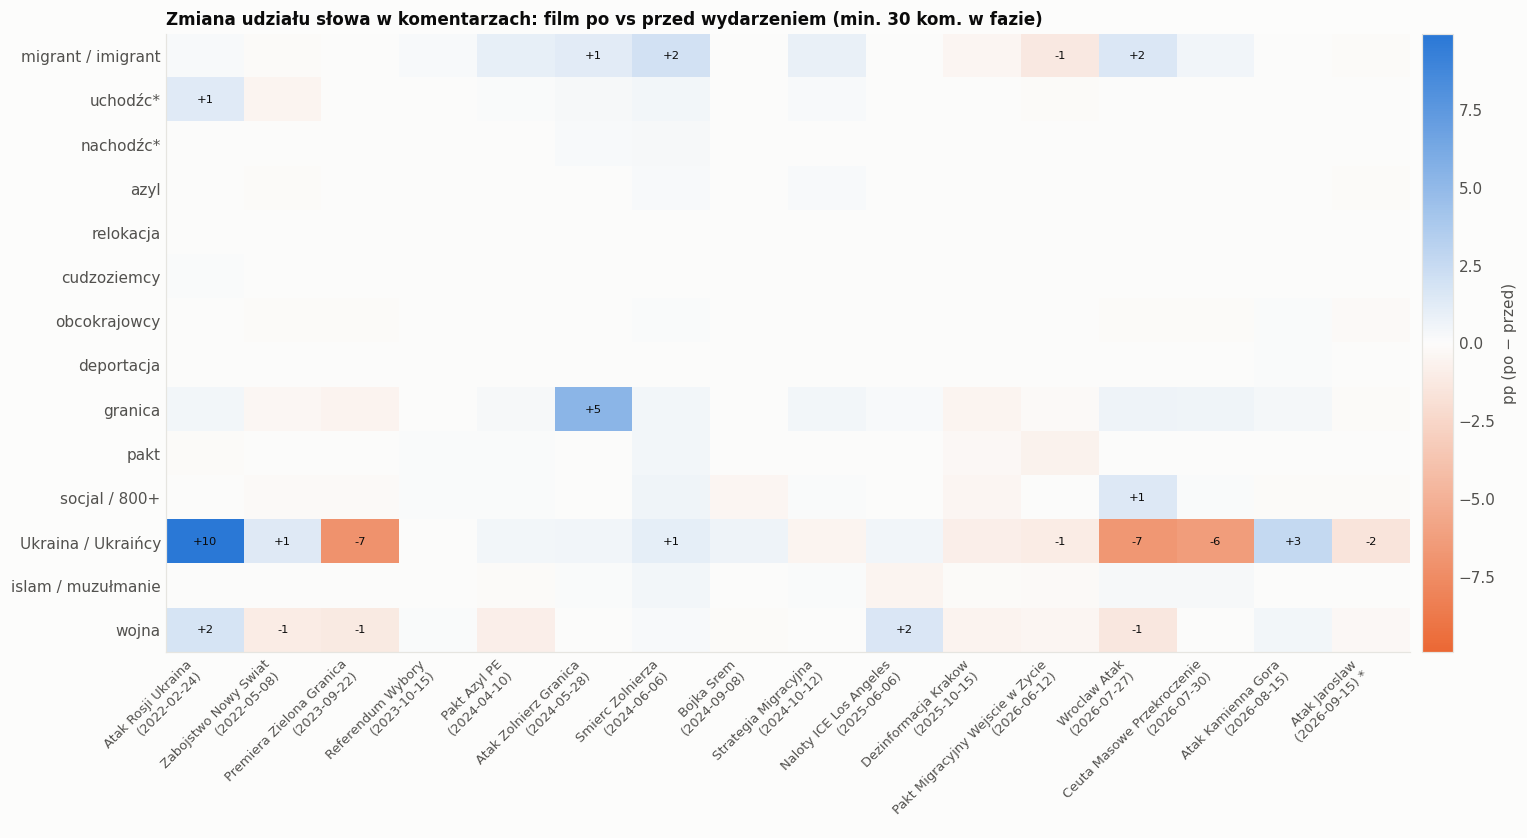

In [99]:
MIN_PHASE_COMMENTS = 30

ph_share = KWM.groupby([df['event_name'], df['video_phase']]).mean() * 100
ph_n = df.groupby(['event_name', 'video_phase']).size()

def phase_slice(p):
    if p not in ph_share.index.get_level_values('video_phase'):
        return pd.DataFrame(np.nan, index=EVENTS, columns=KWM.columns), pd.Series(0, index=EVENTS)
    return (ph_share.xs(p, level='video_phase').reindex(EVENTS),
            ph_n.xs(p, level='video_phase').reindex(EVENTS).fillna(0))

sh_b, n_b = phase_slice('before')
sh_a, n_a = phase_slice('after')
shift = (sh_a - sh_b)
shift[(n_b < MIN_PHASE_COMMENTS) | (n_a < MIN_PHASE_COMMENTS)] = np.nan
shift = shift.T

fig, ax = plt.subplots(figsize=(14, 0.38 * len(shift) + 2.4))
vmax = max(np.nanmax(np.abs(shift.values)), 1) if np.isfinite(shift.values).any() else 1
im = ax.imshow(np.ma.masked_invalid(shift.values.astype(float)), aspect='auto', cmap=DIV, vmin=-vmax, vmax=vmax)
ax.set_yticks(range(len(shift)), shift.index)
ax.set_xticks(range(len(EVENTS)), [l.replace(' (', '\n(') for l in LABELS], rotation=45, ha='right', fontsize=8.5)
ax.grid(False)
for i in range(shift.shape[0]):
    for j in range(shift.shape[1]):
        v = shift.iat[i, j]
        if pd.notna(v) and abs(v) >= 1:
            ax.text(j, i, f'{v:+.0f}', ha='center', va='center', fontsize=7.5, color=TEXT_PRIMARY)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, label='pp (po − przed)')
ax.set_title(f'Zmiana udziału słowa w komentarzach: film po vs przed wydarzeniem (min. {MIN_PHASE_COMMENTS} kom. w fazie)')
fig.tight_layout()
savefig(fig, '12_keyword_shift')

### 4.5 Współwystępowanie słów

Jak często dwa słowa występują w tym samym komentarzu (indeks Jaccarda: komentarze z oboma / komentarze z którymkolwiek).

**Liczba słów kluczowych w komentarzu** (udział %): 0: 92.2% · 1: 6.6% · 2: 1.0% · 3: 0.1% · 4: 0.0% · 5+: 0.0%

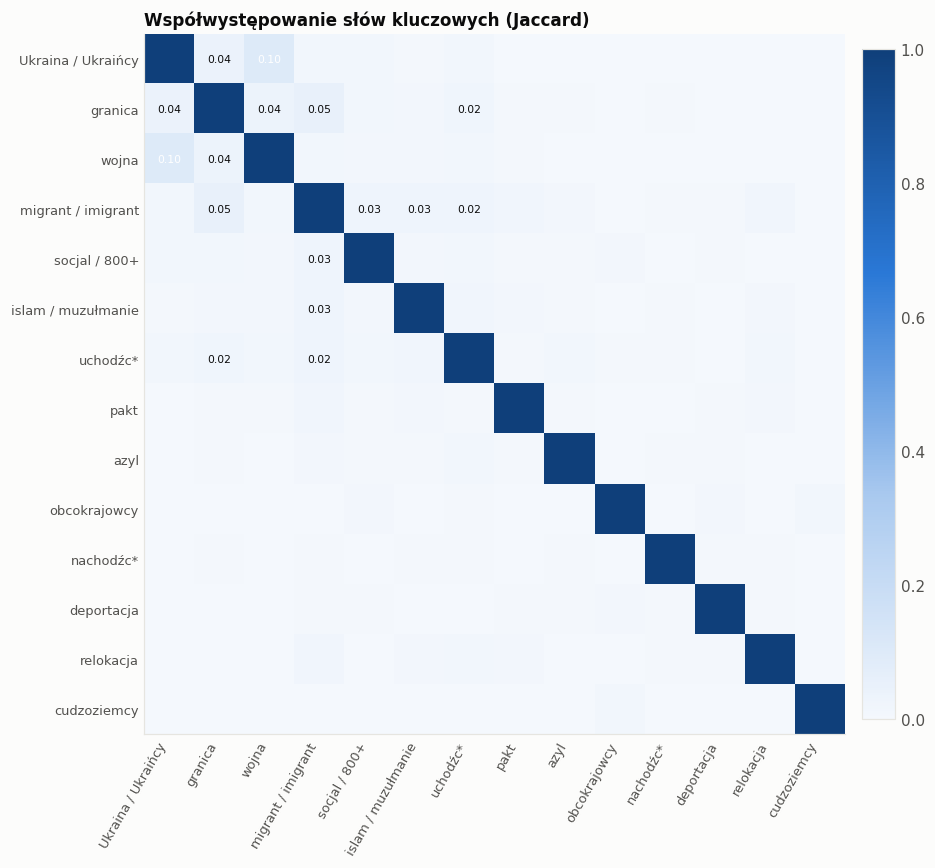

In [100]:
M = KWM.values.astype(np.float32)
inter = M.T @ M
cnt = np.diag(inter)
union = cnt[:, None] + cnt[None, :] - inter
jac = pd.DataFrame(np.where(union > 0, inter / np.where(union > 0, union, 1), 0), index=KWM.columns, columns=KWM.columns)
order = list(kw_total.index)
jac = jac.loc[order, order]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(jac.values, cmap=SEQ, vmin=0)
ax.set_xticks(range(len(order)), order, rotation=60, ha='right', fontsize=8.5)
ax.set_yticks(range(len(order)), order, fontsize=8.5)
ax.grid(False)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j and jac.iat[i, j] >= 0.02:
            ax.text(j, i, f'{jac.iat[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if jac.iat[i, j] > jac.values[~np.eye(len(order), dtype=bool)].max() * 0.55 else TEXT_PRIMARY)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
ax.set_title('Współwystępowanie słów kluczowych (Jaccard)')
fig.tight_layout()
savefig(fig, '13_cooccurrence')

# Ile słów kluczowych ma pojedynczy komentarz?
nk = df['n_keywords'].clip(upper=5).value_counts().sort_index()
nk.index = [str(i) if i < 5 else '5+' for i in nk.index]
display(Markdown('**Liczba słów kluczowych w komentarzu** (udział %): ' +
                 ' · '.join(f'{i}: {v / len(df) * 100:.1f}%' for i, v in nk.items())))

## 5. Zaangażowanie

Zaangażowanie komentarza to `like_count`. Rozkład polubień jest skrajnie skośny – mediana i udział komentarzy bez
żadnego polubienia mówią więcej niż średnia.

In [101]:
eng = df.groupby('event_name').agg(
    comments=('like_count', 'size'), likes_total=('like_count', 'sum'), likes_mean=('like_count', 'mean'),
    likes_median=('like_count', 'median'), likes_p90=('like_count', lambda s: s.quantile(.9)),
    likes_max=('like_count', 'max'), zero_likes_pct=('like_count', lambda s: (s == 0).mean() * 100)).reindex(EVENTS)
eng.round(2)

,comments,likes_total,likes_mean,likes_median,likes_p90,likes_max,zero_likes_pct
event_name,,,,,,,
Atak_Rosji_Ukraina,60766,390528,6.43,1.0,13.0,5465,44.95
Zabojstwo_Nowy_Swiat,25868,245870,9.50,1.0,16.0,9326,34.55
Premiera_Zielona_Granica,66662,590816,8.86,1.0,19.0,4393,45.51
Referendum_Wybory,86878,853212,9.82,1.0,22.0,8034,39.58
Pakt_Azyl_PE,109736,1458039,13.29,1.0,17.0,24282,44.00
Atak_Zolnierz_Granica,124322,1488782,11.98,1.0,18.0,7381,46.39
Smierc_Zolnierza,44594,528272,11.85,0.0,16.0,6656,50.27
Bojka_Srem,134033,1439274,10.74,1.0,18.0,5261,45.36
Strategia_Migracyjna,145179,1671017,11.51,1.0,18.0,9140,47.48


**Koncentracja polubień:** top 1% komentarzy → 45.2% wszystkich polubień · top 10% komentarzy → 85.5% wszystkich polubień

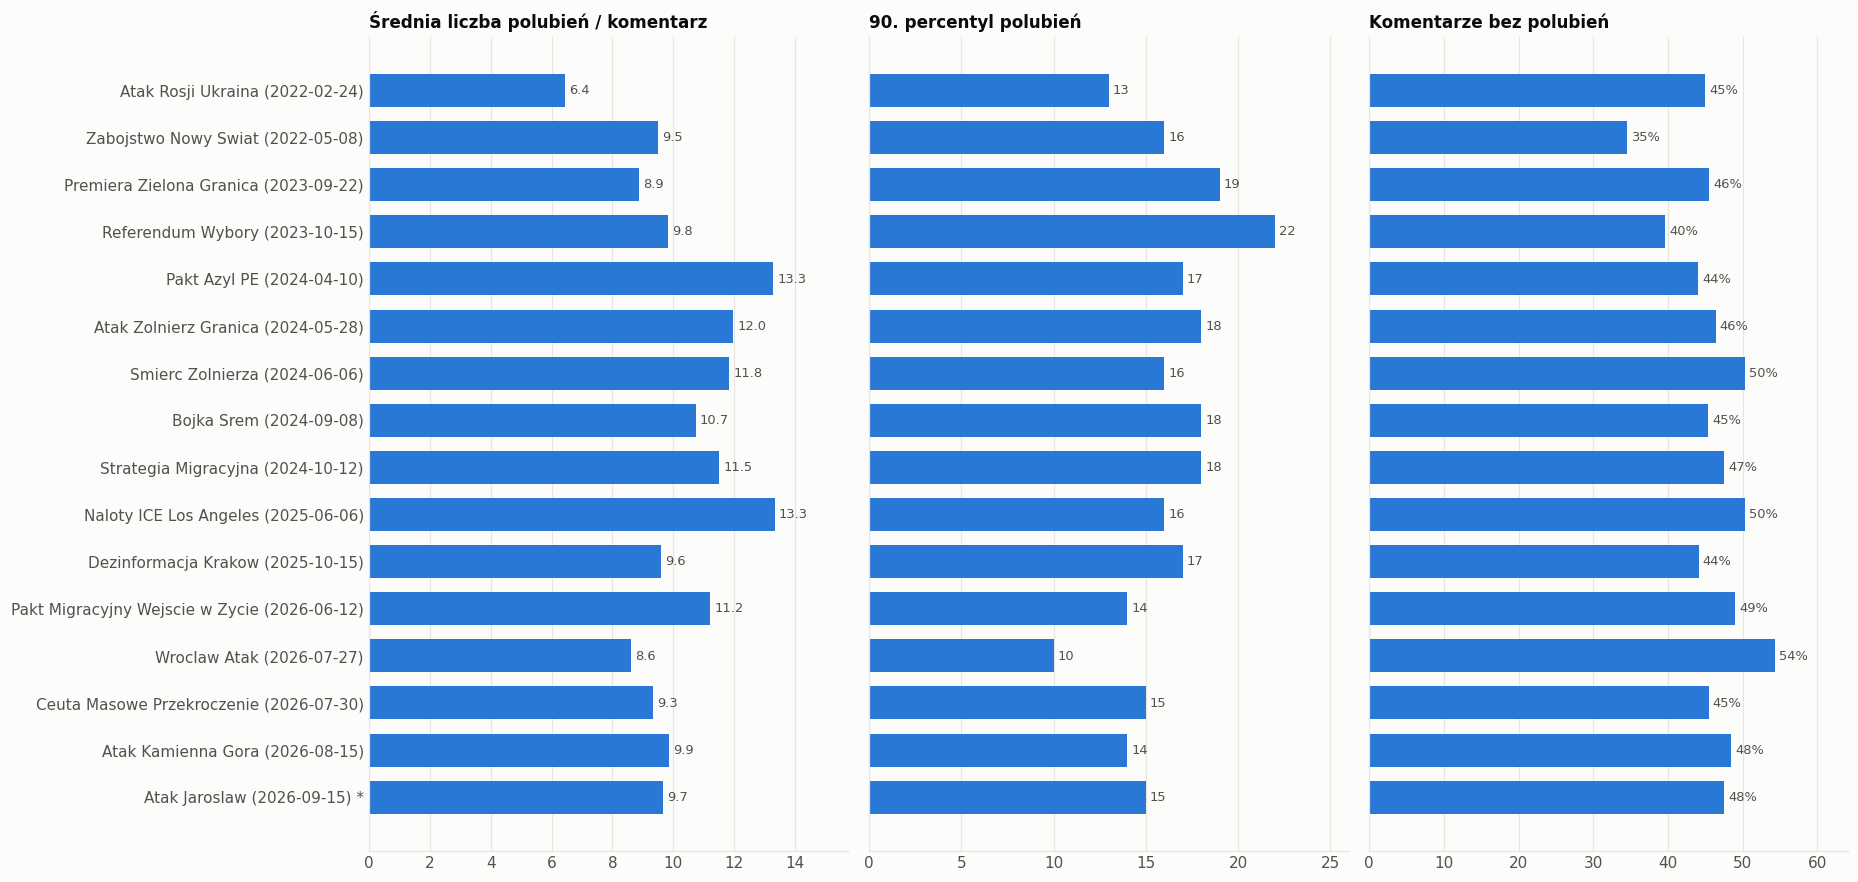

In [102]:
fig, axes = plt.subplots(1, 3, figsize=(17, 0.42 * len(EVENTS) + 1.4), sharey=True)
hbar(axes[0], eng['likes_mean'], LABELS, SERIES[0], fmt='{:.1f}'); axes[0].set_title('Średnia liczba polubień / komentarz')
hbar(axes[1], eng['likes_p90'], LABELS, SERIES[0], fmt='{:.0f}'); axes[1].set_title('90. percentyl polubień')
hbar(axes[2], eng['zero_likes_pct'], LABELS, SERIES[0], fmt='{:.0f}%'); axes[2].set_title('Komentarze bez polubień')
fig.tight_layout()
savefig(fig, '14_engagement')

# Koncentracja polubień: jaki udział polubień mają top 1% / 10% komentarzy
s = df['like_count'].sort_values(ascending=False).values
tot = s.sum()
conc = {f'top {p}% komentarzy': s[:max(int(len(s) * p / 100), 1)].sum() / tot * 100 if tot else np.nan for p in (1, 10)}
display(Markdown('**Koncentracja polubień:** ' + ' · '.join(f'{k} → {v:.1f}% wszystkich polubień' for k, v in conc.items())))

In [103]:
# Polubienia wg fazy filmu oraz komentarze o migracji vs pozostałe
by_phase = df.pivot_table(index='event_name', columns='video_phase', values='like_count', aggfunc='mean').reindex(EVENTS)
by_phase = by_phase.reindex(columns=[c for c in ('before', 'day_0', 'after') if c in by_phase.columns])

by_topic = df.groupby(['event_name', 'is_migr'])['like_count'].agg(['mean', 'median']).unstack().reindex(EVENTS)
by_topic.columns = [f"{stat} – {'migracja' if flag else 'inne'}" for stat, flag in by_topic.columns]
display(Markdown('**Średnie polubienia wg fazy filmu**'))
display(by_phase.round(2))
display(Markdown('**Komentarze o migracji vs pozostałe**'))
display(by_topic.round(2))

**Średnie polubienia wg fazy filmu**

video_phase,before,day_0,after
event_name,,,
Atak_Rosji_Ukraina,6.15,8.06,6.31
Zabojstwo_Nowy_Swiat,7.37,5.22,10.64
Premiera_Zielona_Granica,8.70,7.40,9.01
Referendum_Wybory,10.55,8.82,9.29
Pakt_Azyl_PE,13.87,19.34,12.41
Atak_Zolnierz_Granica,11.54,12.00,12.16
Smierc_Zolnierza,8.98,NaN,11.85
Bojka_Srem,10.31,8.47,10.96
Strategia_Migracyjna,11.50,11.26,11.52


**Komentarze o migracji vs pozostałe**

,mean – inne,mean – migracja,median – inne,median – migracja
event_name,,,,
Atak_Rosji_Ukraina,6.50,4.42,1.0,1.0
Zabojstwo_Nowy_Swiat,9.59,4.72,1.0,1.0
Premiera_Zielona_Granica,8.92,7.79,1.0,1.0
Referendum_Wybory,9.86,8.60,1.0,1.0
Pakt_Azyl_PE,13.28,13.76,1.0,1.0
Atak_Zolnierz_Granica,11.79,14.68,1.0,1.0
Smierc_Zolnierza,11.63,14.31,0.0,0.0
Bojka_Srem,10.74,10.65,1.0,1.0
Strategia_Migracyjna,11.60,8.09,1.0,0.0


In [104]:
# Najczęściej polubiane komentarze
cols = ['event_name', 'channel_name', 'like_count', 'is_migr', 'video_title', 'text']
top_liked = df.nlargest(20, 'like_count')[cols].copy()
top_liked['video_title'] = top_liked['video_title'].map(lambda t: short(t, 70))
top_liked['text'] = top_liked['text'].map(lambda t: short(t, 200))
top_liked.reset_index(drop=True)

,event_name,channel_name,like_count,is_migr,video_title,text
0,Pakt_Azyl_PE,Kanal_Zero,24282,False,GODZINA ZERO #27: AMBASADOR IZRAELA - YACOV LIWNE I ROBERT MAZUREK,"Skoro taki człowiek jest ambasadorem Izraela w Polsce, to ambasadorem Polski w Izraelu powinien zostać Grzegorz Braun."
1,Naloty_ICE_Los_Angeles,SławomirMentzen,16777,False,Mentzen dzień po wyborach,"Kolicja śmiała się, że do Mentzena przychodziły dzieci na wiece, a to te dzieci zmiotły Trzaskowskiego z planszy... XD"
2,Pakt_Migracyjny_Wejscie_w_Zycie,Kanal_Zero,11811,False,GODZINA ZERO #194: KRZYSZTOF STANOWSKI I DR EMIL JĘDRZEJEWSKI,"Na początku 2023 roku, doktor Jędrzejewski usunął mi raka jelita grubego.. już w trzecim stadium... ratując mi życie ❤️.. byłem załamany..."
3,Pakt_Migracyjny_Wejscie_w_Zycie,Kanal_Zero,11606,False,"STANOWSKI: NIE WIERZĘ JUŻ W TO PAŃSTWO, PANIE TUSK","Można się było spodziewać takiego działania. Ja tylko proszę, w imieniu szarych obywateli, nie zostawcie tej sprawy. Dziękuję."
4,Pakt_Migracyjny_Wejscie_w_Zycie,Kanal_Zero,10668,False,GODZINA ZERO #194: KRZYSZTOF STANOWSKI I DR EMIL JĘDRZEJEWSKI,Najważniejszy wywiad tego roku. Pan doktor stał się dzisiaj bohaterem narodowym.
5,Pakt_Azyl_PE,Kanal_Zero,9549,False,MAZUREK I STANOWSKI PODSUMOWUJĄ ROZMOWĘ Z AMBASADOREM IZRAELA,"Ambasador do wydalenia, człowiek bezczelny, butny i arogancki. Jeżeli on jest reprezentatem wszystkich Izraelczyków to jak tu nie być an..."
6,Zabojstwo_Nowy_Swiat,Praktycznieopieniadzach,9326,False,PRZEGRAŁEM.,"wracaj do zdrowia i kolejna walka walka jest twoja, szacun i wielkie pozdro!"
7,Pakt_Azyl_PE,Kanal_Zero,9226,False,GODZINA ZERO #27: AMBASADOR IZRAELA - YACOV LIWNE I ROBERT MAZUREK,"Ambasador Izraela powinien zostać odwolany, buta i chamstwo w obliczu tragedii, za grosz empatii"
8,Strategia_Migracyjna,SławomirMentzen,9140,False,Mężczyźni w Polsce są dyskryminowani!,W końcu jakiś facet porusza i mówi otwarcie o postępującej dyskryminacji mężczyzn.
9,Naloty_ICE_Los_Angeles,SławomirMentzen,8852,False,Mentzen dzień po wyborach,"Berlin w żałobie, cesarzowa w żałobie, Tusk w żałobie... Coś wspaniałego"


In [105]:
# Korelacja Spearmana: polubienia vs długość komentarza, liczba słów kluczowych, wiek komentarza
corr_cols = ['like_count', 'text_len', 'n_keywords', 'days_since_video', 'video_rel_day']
df[corr_cols].corr(method='spearman').round(3)

,like_count,text_len,n_keywords,days_since_video,video_rel_day
like_count,1.000,0.016,-0.017,-0.292,-0.005
text_len,0.016,1.000,0.241,-0.010,0.013
n_keywords,-0.017,0.241,1.000,-0.005,0.006
days_since_video,-0.292,-0.010,-0.005,1.000,-0.014
video_rel_day,-0.005,0.013,0.006,-0.014,1.000


## 6. Filmy

Ile komentarzy zbiera film, jak bardzo dyskusja jest skoncentrowana na kilku filmach i czy filmy z migracją w tytule
zbierają więcej (lub inne) komentarze.

,videos,comments,max_comments,median_comments,top_film_share_%,gini_comments_per_video
event_name,,,,,,
Atak_Rosji_Ukraina,672,60766,1658,35.5,2.7,0.66
Zabojstwo_Nowy_Swiat,466,25868,957,27.0,3.7,0.61
Premiera_Zielona_Granica,497,66662,2467,49.0,3.7,0.66
Referendum_Wybory,743,86878,7239,41.0,8.3,0.69
Pakt_Azyl_PE,515,109736,9387,58.0,8.6,0.76
Atak_Zolnierz_Granica,579,124322,8678,90.0,7.0,0.68
Smierc_Zolnierza,233,44594,3783,64.0,8.5,0.69
Bojka_Srem,867,134033,3778,56.0,2.8,0.67
Strategia_Migracyjna,930,145179,5199,47.0,3.6,0.71


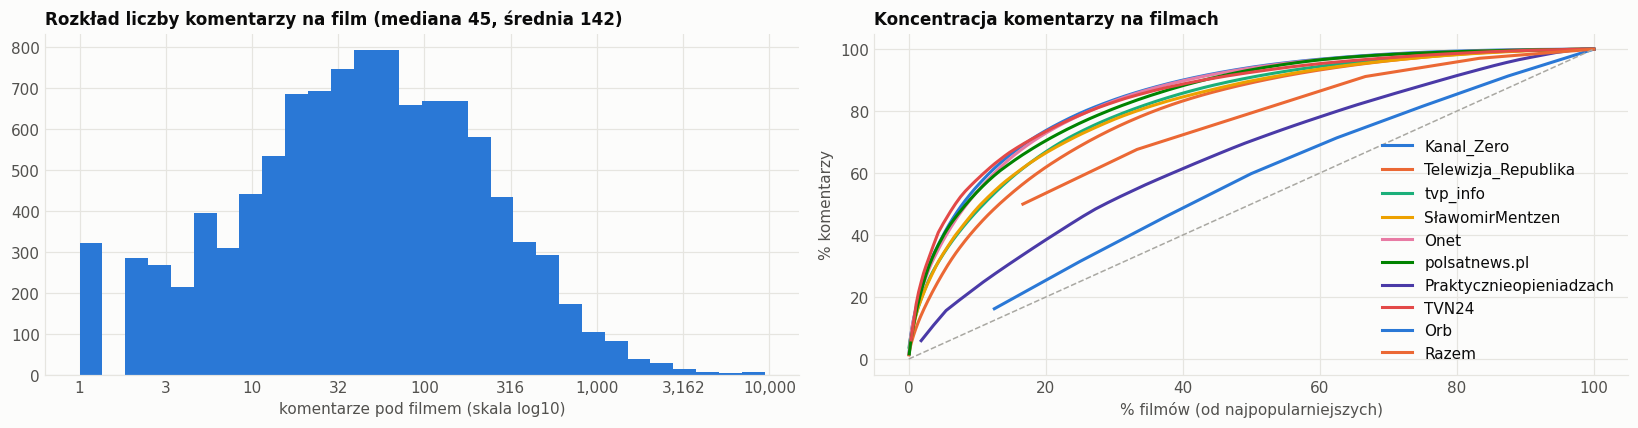

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
cpv = videos['comments']
axes[0].hist(np.log10(cpv.clip(lower=1)), bins=30, color=SERIES[0])
axes[0].set_xlabel('komentarze pod filmem (skala log10)')
axes[0].set_title(f'Rozkład liczby komentarzy na film (mediana {cpv.median():.0f}, średnia {cpv.mean():.0f})')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{10 ** v:,.0f}'))

for c in CHANNELS:
    v = videos.loc[videos.channel_name == c, 'comments'].sort_values(ascending=False).values
    if len(v):
        axes[1].plot(np.arange(1, len(v) + 1) / len(v) * 100, np.cumsum(v) / v.sum() * 100, color=CH_COLOR[c], label=c)
axes[1].plot([0, 100], [0, 100], color=NEUTRAL, ls='--', lw=1)
axes[1].set_xlabel('% filmów (od najpopularniejszych)'); axes[1].set_ylabel('% komentarzy')
axes[1].set_title('Koncentracja komentarzy na filmach'); axes[1].legend()
fig.tight_layout()
savefig(fig, '15_video_distribution')

conc_v = videos.groupby('event_name').agg(
    videos=('video_id', 'size'), comments=('comments', 'sum'), max_comments=('comments', 'max'),
    median_comments=('comments', 'median'))
conc_v['top_film_share_%'] = (conc_v['max_comments'] / conc_v['comments'] * 100).round(1)
conc_v['gini_comments_per_video'] = [round(gini(videos.loc[videos.event_name == e, 'comments']), 2) for e in conc_v.index]
conc_v.reindex(EVENTS)

In [107]:
# Najpopularniejsze filmy
top_videos = (videos.nlargest(20, 'comments')
              [['event_name', 'channel_name', 'video_rel_day', 'comments', 'likes', 'migr_comments', 'video_title']].copy())
top_videos['migr_%'] = (top_videos['migr_comments'] / top_videos['comments'] * 100).round(1)
top_videos['video_title'] = top_videos['video_title'].map(lambda t: short(t, 90))
top_videos.drop(columns='migr_comments').reset_index(drop=True)

,event_name,channel_name,video_rel_day,comments,likes,video_title,migr_%
0,Pakt_Azyl_PE,Kanal_Zero,-7,9387,169873,GODZINA ZERO #27: AMBASADOR IZRAELA - YACOV LIWNE I ROBERT MAZUREK,1.1
1,Atak_Zolnierz_Granica,Kanal_Zero,9,8678,143963,POLSCY ŻOŁNIERZE ZAKUCI W KAJDANKI NA GRANICY Z BIAŁORUSIĄ - ROBERT MAZUREK KOMENTUJE,15.6
2,Pakt_Azyl_PE,Kanal_Zero,-6,8153,99609,MAZUREK I STANOWSKI PODSUMOWUJĄ ROZMOWĘ Z AMBASADOREM IZRAELA,1.2
3,Pakt_Migracyjny_Wejscie_w_Zycie,Kanal_Zero,14,7913,107942,"STANOWSKI: NIE WIERZĘ JUŻ W TO PAŃSTWO, PANIE TUSK",1.0
4,Naloty_ICE_Los_Angeles,SławomirMentzen,-4,7477,92772,Mentzen dzień po wyborach,1.9
5,Referendum_Wybory,tvp_info,-6,7239,85406,Debata wyborcza 2023,3.0
6,Pakt_Azyl_PE,Kanal_Zero,13,6335,77303,GODZINA ZERO #33: OSTATNIE POKOLENIE - AKTYWIŚCI KLIMATYCZNI | MAZUREK I STANOWSKI,1.1
7,Pakt_Migracyjny_Wejscie_w_Zycie,Kanal_Zero,11,5895,176033,GODZINA ZERO #194: KRZYSZTOF STANOWSKI I DR EMIL JĘDRZEJEWSKI,0.7
8,Atak_Kamienna_Gora,SławomirMentzen,8,5725,97701,Sprawa dla Mentzena: Pobicie polskiego dziecka w Suwałkach,6.0
9,Strategia_Migracyjna,Telewizja_Republika,4,5199,104872,Prezydent Andrzej Duda miażdży pomysły Donalda Tuska! Zobacz! Orędzie Prezydenta Andrzeja…,1.8


In [108]:
# Typ filmu (tytuł o migracji vs inny) x kanał
type_ch = videos.groupby(['channel_name', 'title_migr']).agg(
    filmy=('video_id', 'size'), komentarze=('comments', 'sum'),
    mediana_kom_na_film=('comments', 'median'), srednia_kom_na_film=('comments', 'mean')).round(1)
type_ch.rename(index={True: 'tytuł o migracji', False: 'inny tytuł'}, level=1)

filmy  komentarze  mediana_kom_na_film  srednia_kom_na_film
channel_name            title_migr                                                                   
Kanal_Zero              inny tytuł         2093      599616                 95.0                286.5
                        tytuł o migracji     57       31188                207.0                547.2
Onet                    inny tytuł         1453       75933                 17.0                 52.3
                        tytuł o migracji     34        2489                 49.0                 73.2
Orb                     inny tytuł            8         727                 92.5                 90.9
Praktycznieopieniadzach inny tytuł           55       31365                462.0                570.3
Razem                   inny tytuł            6          34                  4.0                  5.7
SławomirMentzen         inny tytuł          286      121931                187.5                426.3
                        tytuł o migracji     10        6402                259.5                640.2
TVN24                   inny tytuł          276       11998                 14.0                 43.5
                        tytuł o migracji      2           9                  4.5                  4.5
Telewizja_Republika     inny tytuł         3041      372097                 61.0                122.4
                        tytuł o migracji     99       15614                 72.0                157.7
polsatnews.pl           inny tytuł         1150       41995                 15.0                 36.5
                        tytuł o migracji      4         313                 35.0                 78.2
tvp_info                inny tytuł         1918      182905                 40.0                 95.4
                        tytuł o migracji     74        7217                 48.0                 97.5

## 7. Czas komentowania

### 7.1 Opóźnienie względem publikacji filmu

Skumulowany udział komentarzy w czasie od publikacji filmu (pierwsze 14 dni; oś X w skali log). Duża część
komentarzy pojawia się w pierwszych godzinach.

,count,mean,std,min,25%,50%,75%,90%,max
channel_name,,,,,,,,,
Kanal_Zero,630804.0,23.6,44.4,-10.9,1.9,7.0,22.5,64.2,350.9
Telewizja_Republika,387711.0,16.5,37.5,-4.8,1.1,3.3,12.6,43.6,350.1
tvp_info,190122.0,25.1,49.0,-0.3,1.7,6.1,21.7,72.9,351.3
SławomirMentzen,128333.0,32.3,54.6,-1.3,2.5,8.9,34.7,94.9,349.9
Onet,78422.0,38.7,58.9,-1.4,2.7,12.5,48.7,120.0,348.9
polsatnews.pl,42308.0,46.8,69.5,-7.4,2.4,16.5,60.2,144.9,350.9
Praktycznieopieniadzach,31365.0,16.6,34.8,-1.3,1.1,3.6,17.1,43.9,341.7
TVN24,12007.0,55.4,78.6,-7.5,4.1,18.7,71.0,175.5,347.7
Orb,727.0,20.4,36.4,0.0,1.8,5.6,22.6,51.1,298.1


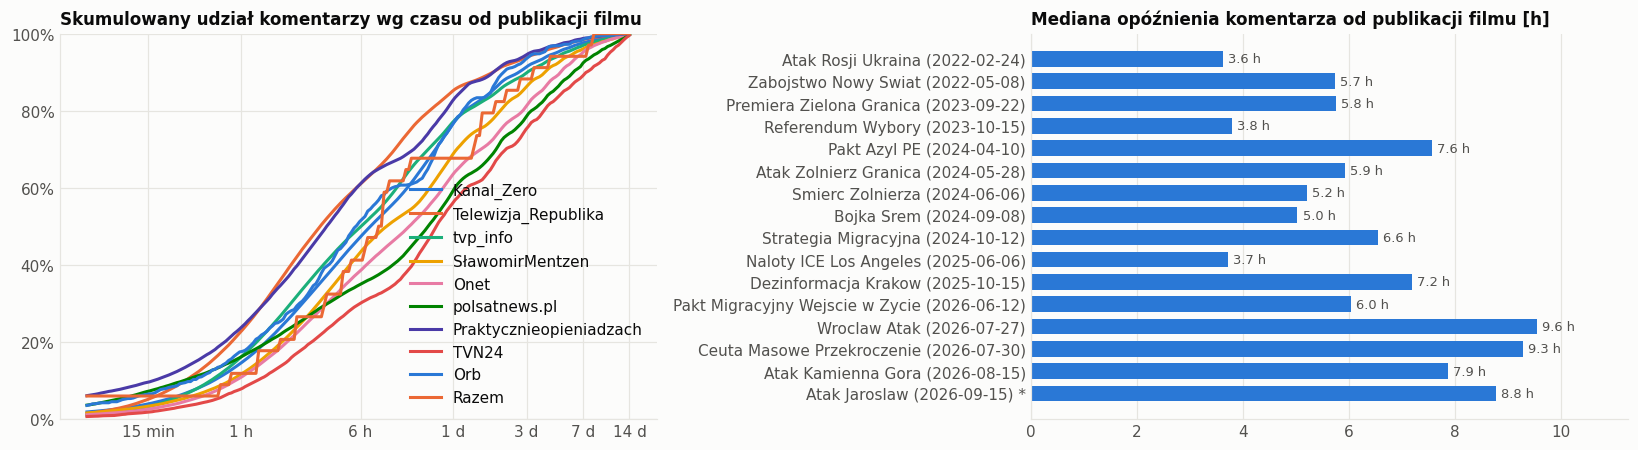

In [109]:
lat = df['hours_since_video'].clip(lower=0.01)
xs = np.logspace(-1, math.log10(24 * 14), 200)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for c in CHANNELS:
    v = np.sort(lat[df.channel_name == c].values)
    if len(v):
        axes[0].plot(xs, np.searchsorted(v, xs, side='right') / len(v) * 100, color=CH_COLOR[c], label=c)
axes[0].set_xscale('log')
axes[0].set_xticks([0.25, 1, 6, 24, 72, 168, 336], ['15 min', '1 h', '6 h', '1 d', '3 d', '7 d', '14 d'])
axes[0].xaxis.set_minor_locator(mticker.NullLocator())
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter()); axes[0].set_ylim(0, 100)
axes[0].set_title('Skumulowany udział komentarzy wg czasu od publikacji filmu'); axes[0].legend(loc='lower right')

lat_ev = (df.groupby('event_name')['hours_since_video'].median()).reindex(EVENTS)
hbar(axes[1], lat_ev, LABELS, SERIES[0], fmt='{:.1f} h')
axes[1].set_title('Mediana opóźnienia komentarza od publikacji filmu [h]')
fig.tight_layout()
savefig(fig, '16_latency')

lat_tab = df.groupby('channel_name')['hours_since_video'].describe(percentiles=[.25, .5, .75, .9]).round(1)
lat_tab.loc[CHANNELS]

### 7.2 Kiedy ludzie komentują – dzień tygodnia × godzina

Udział komentarzy (%) w komórce dzień × godzina (czas lokalny Europe/Warsaw), osobno dla każdego kanału.

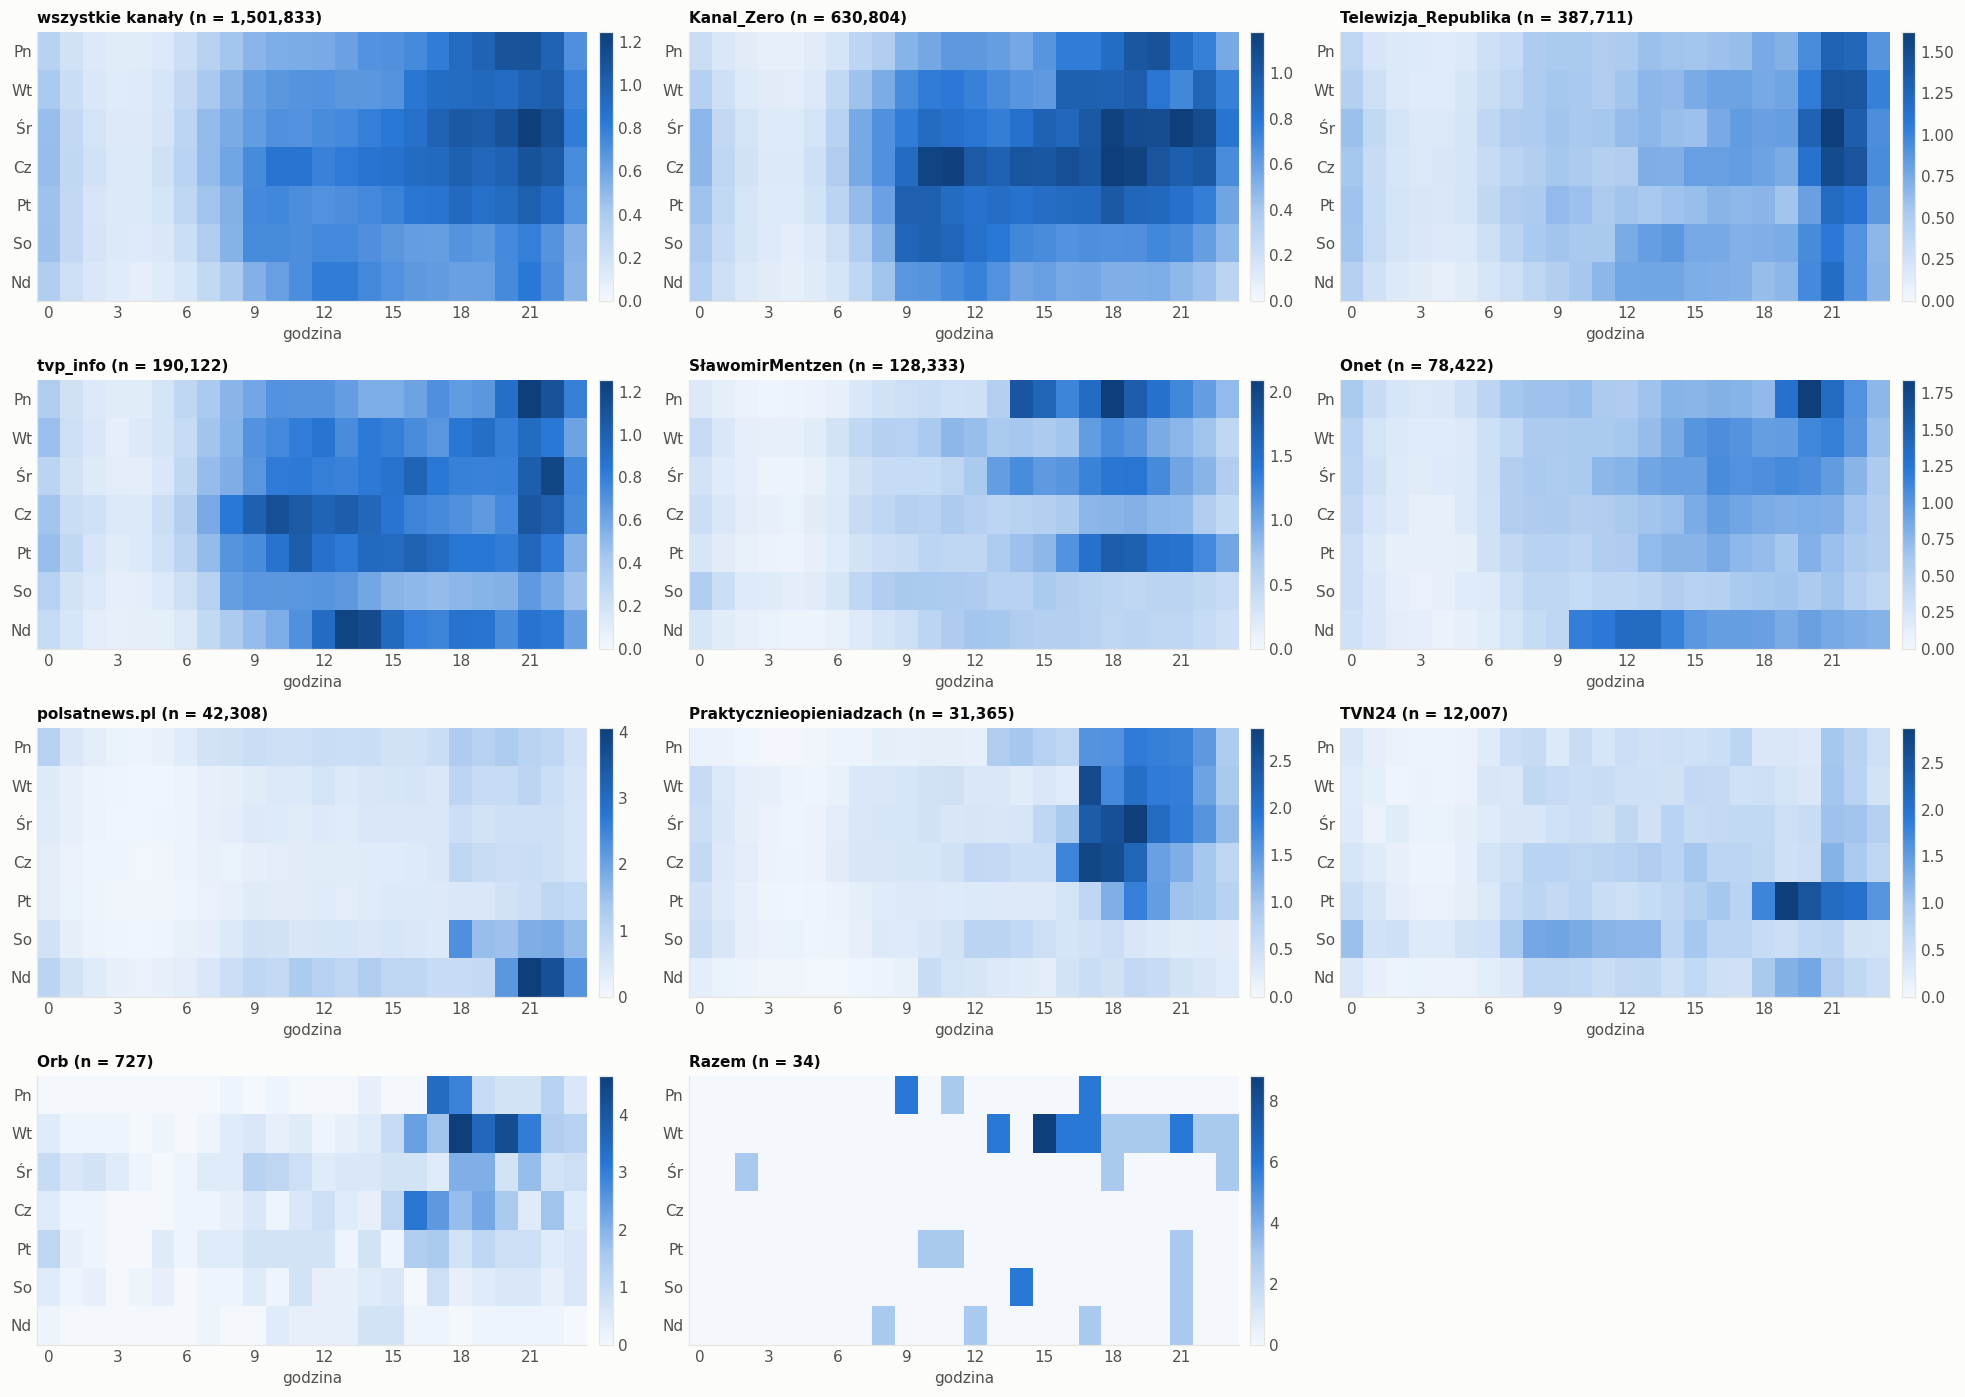

In [110]:
DOW = ['Pn', 'Wt', 'Śr', 'Cz', 'Pt', 'So', 'Nd']
fig, axes = small_multiples(len(CHANNELS) + 1, ncols=min(len(CHANNELS) + 1, 3), w=6, h=3.2)
for ax, (name, sub) in zip(axes, [('wszystkie kanały', df)] + [(c, df[df.channel_name == c]) for c in CHANNELS]):
    m = (sub.groupby([sub['comment_local'].dt.dayofweek, sub['comment_local'].dt.hour]).size()
         .unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0))
    m = m / max(m.values.sum(), 1) * 100
    im = ax.imshow(m.values, aspect='auto', cmap=SEQ, vmin=0)
    ax.set_yticks(range(7), DOW); ax.set_xticks(range(0, 24, 3)); ax.grid(False)
    ax.set_title(f'{name} (n = {len(sub):,})', fontsize=10); ax.set_xlabel('godzina')
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
fig.tight_layout()
savefig(fig, '17_weekday_hour')

## 8. Tekst

### 8.1 Długość i cechy komentarzy

,len_median,len_mean,words_median,url_pct,mention_pct,emoji_pct,excl_pct,question_pct,caps_shouting_pct
event_name,,,,,,,,,
Atak_Rosji_Ukraina,75.0,137.4,12.0,1.8,0.1,10.6,16.5,16.1,3.7
Zabojstwo_Nowy_Swiat,68.0,117.6,10.0,1.0,0.1,15.0,15.5,13.3,4.3
Premiera_Zielona_Granica,74.0,126.3,11.0,0.4,0.3,19.5,14.8,13.5,3.7
Referendum_Wybory,77.0,129.3,12.0,0.2,0.1,19.8,14.7,12.8,4.3
Pakt_Azyl_PE,77.0,129.9,12.0,0.1,0.1,18.8,13.1,13.6,2.0
Atak_Zolnierz_Granica,74.0,122.3,11.0,0.0,0.1,18.0,14.5,13.1,2.8
Smierc_Zolnierza,75.0,125.5,12.0,0.0,0.1,18.0,13.0,13.9,2.5
Bojka_Srem,72.0,119.2,11.0,0.1,0.1,19.3,13.6,13.6,2.3
Strategia_Migracyjna,72.0,120.8,11.0,0.0,0.1,20.9,13.2,12.7,2.3


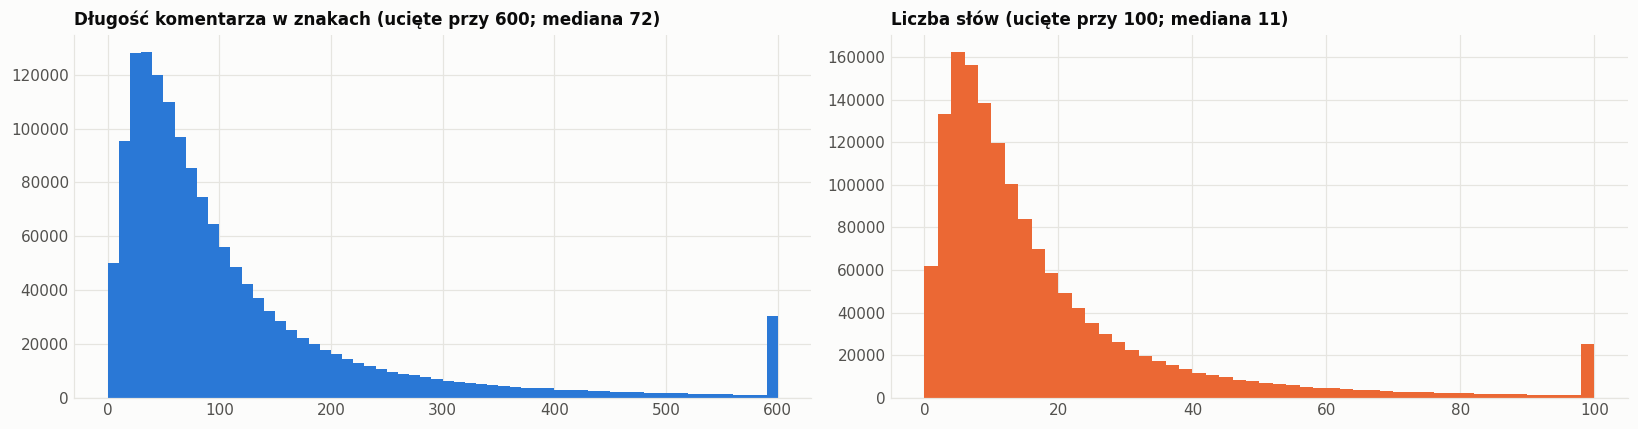

In [111]:
URL_RE = re.compile(r'https?://\S+|\bwww\.\S+', re.I)
MENTION_RE = re.compile(r'@\w+')
HASHTAG_RE = re.compile(r'#\w+')
EMOJI_RE = re.compile('[\U0001F300-\U0001FAFF☀-➿⭐⭕←-⇿]')
TIMESTAMP_RE = re.compile(r'\b\d{1,2}:\d{2}(?::\d{2})?\b')

df['n_words'] = df['text'].map(lambda t: len(re.findall(r'[^\W\d_]+', URL_RE.sub(' ', MENTION_RE.sub(' ', t)))))
df['has_url'] = df['text'].str.contains(URL_RE)
df['has_mention'] = df['text'].str.contains(MENTION_RE)
df['has_hashtag'] = df['text'].str.contains(HASHTAG_RE)
df['has_emoji'] = df['text'].str.contains(EMOJI_RE)
df['has_timestamp'] = df['text'].str.contains(TIMESTAMP_RE)
df['has_excl'] = df['text'].str.contains(r'!')
df['has_question'] = df['text'].str.contains(r'\?')
df['caps_ratio'] = df['text'].map(lambda t: (sum(ch.isupper() for ch in t) / max(sum(ch.isalpha() for ch in t), 1)))
df['shouting'] = (df['caps_ratio'] > 0.7) & (df['n_words'] >= 3)

feat = df.groupby('event_name').agg(
    len_median=('text_len', 'median'), len_mean=('text_len', 'mean'), words_median=('n_words', 'median'),
    url_pct=('has_url', lambda s: s.mean() * 100), mention_pct=('has_mention', lambda s: s.mean() * 100),
    emoji_pct=('has_emoji', lambda s: s.mean() * 100), excl_pct=('has_excl', lambda s: s.mean() * 100),
    question_pct=('has_question', lambda s: s.mean() * 100), caps_shouting_pct=('shouting', lambda s: s.mean() * 100),
).reindex(EVENTS).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(df['text_len'].clip(upper=600), bins=60, color=SERIES[0])
axes[0].set_title(f'Długość komentarza w znakach (ucięte przy 600; mediana {df.text_len.median():.0f})')
axes[1].hist(df['n_words'].clip(upper=100), bins=50, color=SERIES[1])
axes[1].set_title(f'Liczba słów (ucięte przy 100; mediana {df.n_words.median():.0f})')
fig.tight_layout()
savefig(fig, '18_text_length')
feat

### 8.2 Najczęstsze słowa

Tokenizacja jest prosta (słowa ≥ 3 litery, bez stop-słów i linków). Dla języka polskiego bez lematyzacji
formy fleksyjne liczą się osobno – to tylko orientacyjny obraz słownictwa.

Najczęstsze hashtagi: [('#konfederacja', 27), ('#1', 26), ('#2', 14), ('#muremzapolskimmundurem', 13), ('#polexit', 10), ('#standwithukraine', 9), ('#możemywszystko', 9), ('#nigdy_wiecej_tüska', 9), ('#anonymous', 7), ('#nigdy_więcej_tüska', 7)]


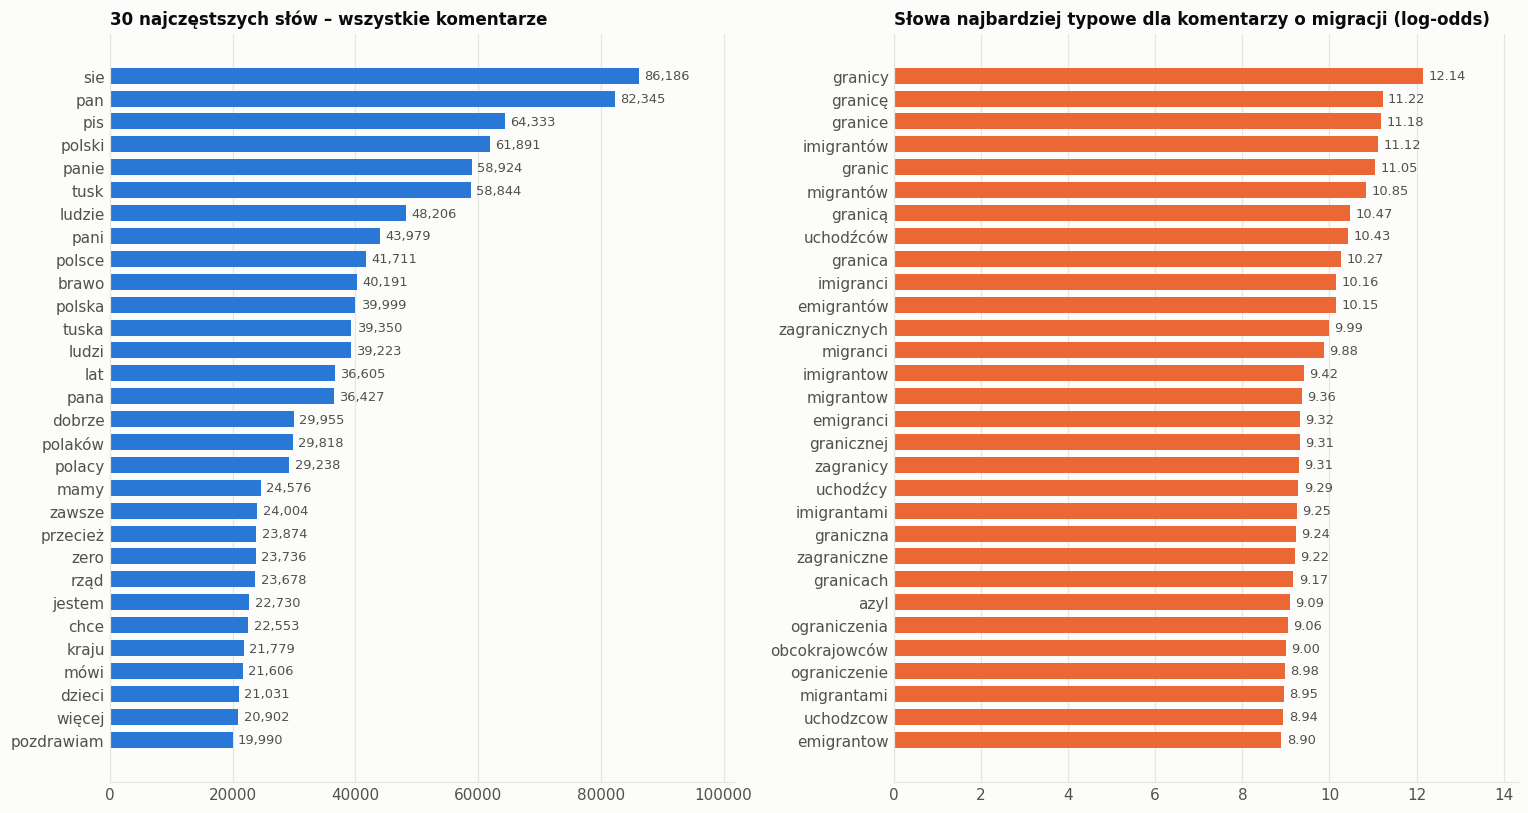

In [112]:
STOPWORDS = set("""
i w we z za na do od po przez dla o u ze że się nie to jest są był była było byli były być będzie będą bym by aby
żeby czy ale lub albo oraz też także tylko jak jako gdy gdzie kiedy który która które którzy tego tej ten ta te tym
tych nim nią nich ich jej jego mu go ją je im mi mnie ci cię tobie ty ja my wy oni one on ona ono nas was wam nam
więc bo bez już jeszcze bardzo może można trzeba mam ma masz mają mieć miał co czego czym tak taki taka takie
nawet tutaj tu tam teraz potem przed pod nad między wszystko wszyscy wszystkich jeden jedna jedno przy gdyby gdyż
ponieważ jednak dlatego sobie siebie swoje swój swoja swoich sam sama coś ktoś nic nikt każdy każda kto czemu
dlaczego jakie jaki jaka bardziej mogą niż niech niby chyba oby ani są tez jak tym ich był nic oni ten
https http www com pl youtube tvn24 br amp quot
""".split())
WORD_RE = re.compile(r'[^\W\d_]{3,}', re.UNICODE)

def tokenize(t):
    t = URL_RE.sub(' ', MENTION_RE.sub(' ', t))
    return [w for w in WORD_RE.findall(t) if w not in STOPWORDS]

df['tokens'] = df['text_lc'].map(tokenize)

def top_words(frame, n=30):
    c = Counter()
    for toks in frame['tokens']:
        c.update(toks)
    return c

all_c = top_words(df)
mig_c, oth_c = top_words(df[df.is_migr]), top_words(df[~df.is_migr])

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
top = pd.Series(dict(all_c.most_common(30)))
hbar(axes[0], top, top.index); axes[0].set_title('30 najczęstszych słów – wszystkie komentarze')

# Słowa nadreprezentowane w komentarzach o migracji (log-odds ze wygładzaniem)
Nm, No = sum(mig_c.values()), sum(oth_c.values())
rows = []
for w, cm in mig_c.items():
    if cm >= 20:
        co = oth_c.get(w, 0)
        rows.append((w, cm, np.log((cm + .5) / (Nm + 1)) - np.log((co + .5) / (No + 1))))
over = pd.DataFrame(rows, columns=['word', 'count_migr', 'log_odds']).sort_values('log_odds', ascending=False).head(30)
hbar(axes[1], over.set_index('word')['log_odds'], over['word'], color=SERIES[1], fmt='{:.2f}')
axes[1].set_title('Słowa najbardziej typowe dla komentarzy o migracji (log-odds)')
fig.tight_layout()
savefig(fig, '19_top_words')

kw_hash = Counter(h.lower() for t in df.loc[df.has_hashtag, 'text'] for h in HASHTAG_RE.findall(t))
print('Najczęstsze hashtagi:', kw_hash.most_common(10) if kw_hash else '— brak')

### 8.3 Słowa rosnące po wydarzeniu

Dla każdego wydarzenia: słowa, których względna częstość wzrosła najbardziej między komentarzami pod filmami z fazy
*przed* a z fazy *po* (wygładzony log-ratio; słowo musi wystąpić ≥ `MIN_AFTER` razy po wydarzeniu).
To często ujawnia słownictwo specyficzne dla wydarzenia (miejsca, nazwiska), którego nie ma na liście słów kluczowych.

In [113]:
MIN_AFTER, TOP_RISING = 5, 12

rising = {}
for e in EVENTS:
    d = df[df.event_name == e]
    cb = top_words(d[d.video_phase == 'before'])
    ca = top_words(d[d.video_phase == 'after'])
    nb, na = sum(cb.values()), sum(ca.values())
    if nb < 200 or na < 200:
        rising[LABEL[e]] = ['(za mało danych)']
        continue
    sc = {w: np.log((c + .5) / (na + 1)) - np.log((cb.get(w, 0) + .5) / (nb + 1)) for w, c in ca.items() if c >= MIN_AFTER}
    rising[LABEL[e]] = [w for w, _ in sorted(sc.items(), key=lambda kv: -kv[1])[:TOP_RISING]]

pd.DataFrame({k: pd.Series(v) for k, v in rising.items()}).T

,0,1,2,3,4,5,6,7,8,9,10,11
Atak Rosji Ukraina (2022-02-24),anonymous,paramaxil,xayoo,stankiewicz,ochojska,szpaku,industries,gierej,slava,zet,subów,migi
Zabojstwo Nowy Swiat (2022-05-08),koncert,justyna,doda,stuu,dody,krystyna,farba,wygrałeś,straciły,enigmy,licze,dorota
Premiera Zielona Granica (2023-09-22),napieralski,kropiwnicki,gierej,wasserman,joński,patryku,fryzjer,biedroń,patryk,dyduch,kożuszku,matczak
Referendum Wybory (2023-10-15),napieralski,nowicka,szejna,molek,pawliczak,gramatyka,sterczewski,sawicki,libicki,goha,freak,zaświadczenia
Pakt Azyl PE (2024-04-10),dioz,protasiewicz,kaminski,wyszkoni,numeru,gibała,danielu,nba,spoofing,kamiński,tytus,protasiewicza
Atak Zolnierz Granica (2024-05-28),dymisja,matczaka,olbrychski,żołnierz,żołnierzami,strzały,żandarmeria,mundurem,broniących,siara,spoczywaj,ostrzegawcze
Smierc Zolnierza (2024-06-06),polski,ludzi,polska,sie,dobrze,mazurek,rząd,pan,zawsze,zero,niemcy,pracy
Bojka Srem (2024-09-08),powódź,retencyjnych,powodzi,powodzianom,zbiorników,powodzią,wałów,powodzian,zalewska,zbiornik,zbiorniki,powodzie
Strategia Migracyjna (2024-10-12),orędzie,ochojska,rondzie,budda,zaucha,azylu,hazard,ciężarówek,rondach,rond,gosek,integracji
Naloty ICE Los Angeles (2025-06-06),iranu,iran,iranie,probierz,greta,taśm,iranowi,trenera,irak,iranem,cenckiewicz,gierej


In [114]:
# Najczęstsze słowa wg kanału
pd.DataFrame({c: pd.Series([f'{w} ({n})' for w, n in top_words(df[df.channel_name == c]).most_common(15)]) for c in CHANNELS})

,Kanal_Zero,Telewizja_Republika,tvp_info,SławomirMentzen,Onet,polsatnews.pl,Praktycznieopieniadzach,TVN24,Orb,Razem
0,pan (36149),tusk (29375),pis (13617),pan (11959),pan (4546),odcinek (2606),gimper (2360),pis (937),jurek (43),zandberg (6)
1,sie (33655),sie (26506),pan (10763),mentzen (7903),sie (4482),super (1797),sie (1871),tvn (649),orbcast (27),owca (4)
2,ludzie (22824),polski (25009),polski (10685),panie (7898),panie (3479),taniec (1270),dobrze (938),sie (639),jurka (25),kraju (4)
3,panie (22577),pis (23527),sie (10645),sie (7219),pis (3414),sie (1145),ludzie (865),ludzie (467),bartek (24),super (3)
4,pani (20373),tuska (19630),panie (8469),pis (6066),polski (3284),pani (924),film (634),ludzi (416),sie (23),polityków (3)
5,zero (20298),pan (17798),tusk (8351),polski (5269),tusk (2735),brawo (913),jestem (628),lat (412),podcast (22),piękne (3)
6,ludzi (18395),panie (15465),pani (7406),polsce (4496),ludzie (2459),występ (883),ludzi (554),polski (403),razem (21),owcę (3)
7,mazurek (18164),polska (14651),polska (6970),pana (4377),brawo (2359),pięknie (787),wiem (494),polsce (364),więcej (19),razem (2)
8,lat (17434),brawo (13686),brawo (6775),konfederacja (4245),pani (2210),pan (691),fagata (488),pan (315),lewica (19),zawsze (2)
9,pana (17059),polsce (13300),polsce (6042),ludzie (4177),polsce (2148),panie (686),stuu (475),pani (285),tort (18),spotkanie (2)


## 9. Jakość komentarzy

Komentarze z YouTube są mocno zróżnicowane: obok merytorycznych wypowiedzi są same emoji, znaczniki czasu („1:23”),
jednowyrazowe reakcje, linki, komentarze w innym języku i spam. Każdy komentarz dostaje jedną etykietę `quality`
(sprawdzaną w tej kolejności):

| etykieta | reguła |
|---|---|
| `no_text` | pusty albo tylko linki / wzmianki / hashtagi / liczby / znaczniki czasu / interpunkcja |
| `emoji_only` | wyłącznie emoji (plus ewentualne linki, wzmianki, interpunkcja) |
| `very_short` | mniej niż `MIN_WORDS` słów po usunięciu linków i wzmianek |
| `english` / `other_language` | wykryty język inny niż polski (angielski / cyrylica) |
| `unclear_language` | nie da się rozstrzygnąć |
| `polish` | polski tekst z co najmniej `MIN_WORDS` słowami – **czyste** komentarze |

Detekcja języka to lekka heurystyka (słowa funkcyjne polskie i angielskie, polskie znaki diakrytyczne, cyrylica).
Do analiz właściwych użyj prawdziwego detektora (np. `lingua-language-detector`). Nic nie jest tu usuwane –
etykiety są flagami, a `df_clean` to przefiltrowany widok.

**Czyste komentarze:** 1,312,884 z 1,501,833 (87.4%)

quality,polish,unclear_language,very_short,emoji_only,no_text,english,other_language,total,clean_pct
event_name,,,,,,,,,
Atak_Rosji_Ukraina,51824,3300,3823,771,442,308,298,60766,85.3
Zabojstwo_Nowy_Swiat,21539,1539,2069,370,131,78,142,25868,83.3
Premiera_Zielona_Granica,57865,3155,4105,1068,317,69,83,66662,86.8
Referendum_Wybory,76728,4201,4477,975,300,69,128,86878,88.3
Pakt_Azyl_PE,96223,4715,6734,1548,301,146,69,109736,87.7
Atak_Zolnierz_Granica,109168,5892,7267,1606,275,80,34,124322,87.8
Smierc_Zolnierza,39479,1857,2545,558,116,24,15,44594,88.5
Bojka_Srem,116819,5822,8890,2029,341,87,45,134033,87.2
Strategia_Migracyjna,125814,6991,9455,2329,403,121,66,145179,86.7


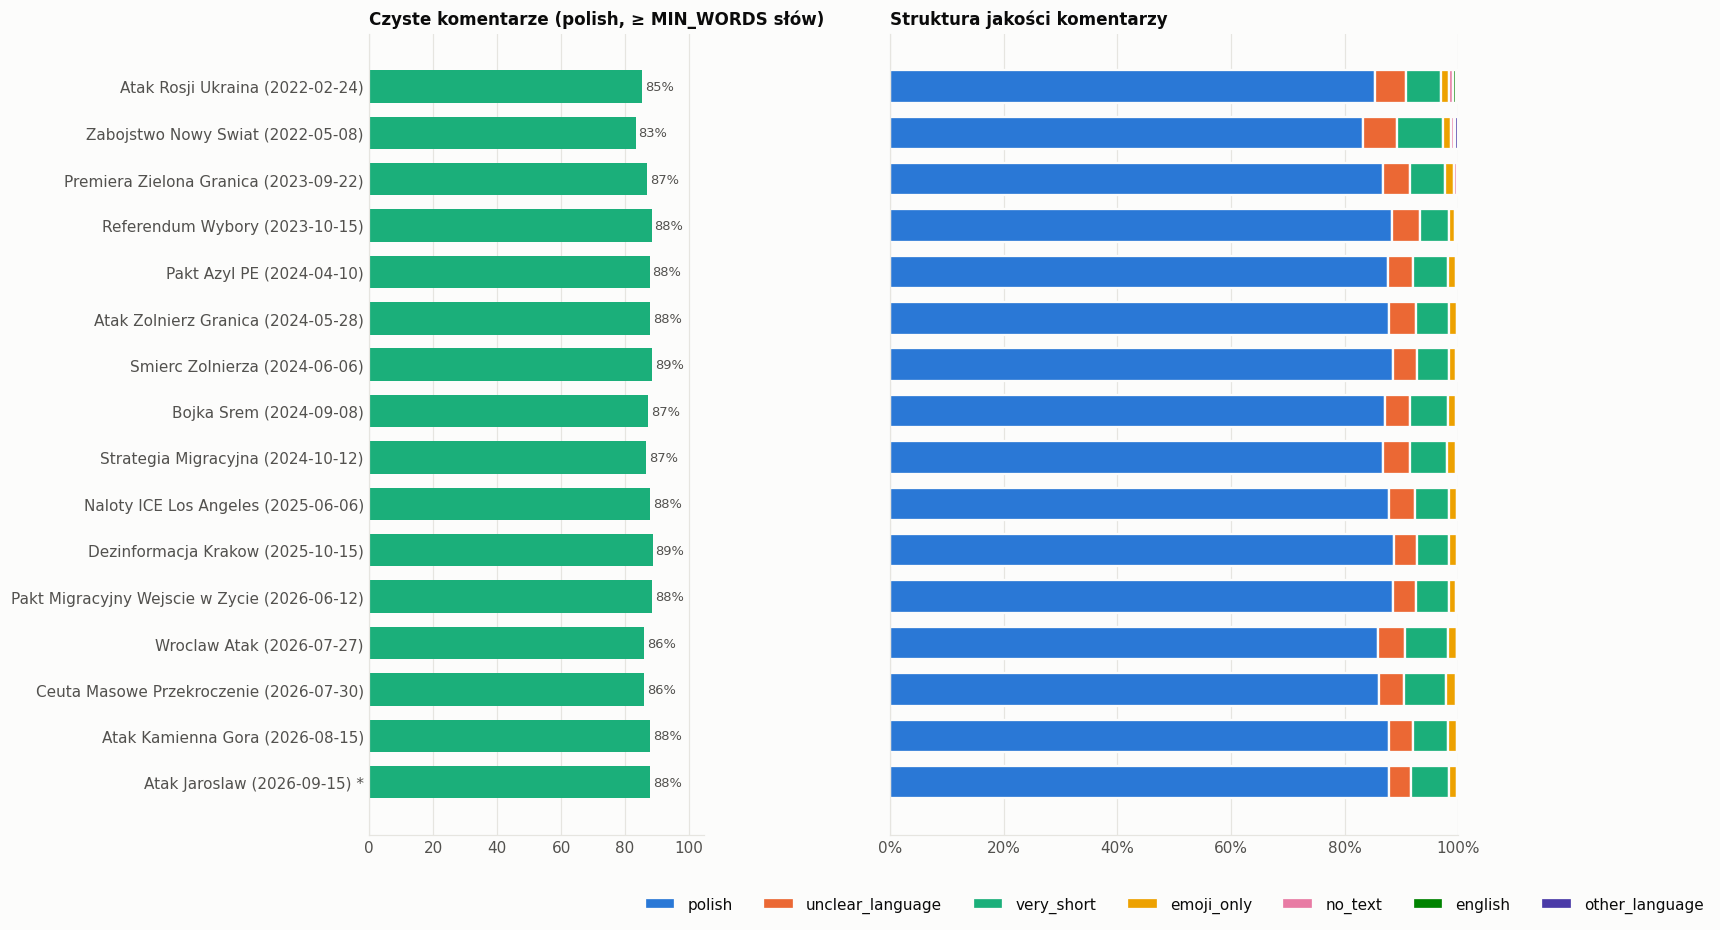

In [115]:
MIN_WORDS = 3
CLEAN_LABELS = {'polish'}

PL_FUNC = set('nie się że jest na w z do co jak ale tak czy już tylko dla przez po od za są był ich jego tego bo więc '
              'jeszcze bardzo może mi mnie ci go ją być będzie które który tym tych nas wam nam tu tam kto gdzie '
              'jeśli jeżeli ponieważ żeby oraz też'.split())
EN_FUNC = set('the and is are of that it you this for with not they was have be but what if so we he she just all your '
              'my dont don im its an at from or will would can about there their them who why how when out up people '
              'yes been has had were more than these those because'.split())
DIACRITICS_RE = re.compile('[ąćęłńóśźż]')
CYRILLIC_RE = re.compile('[Ѐ-ӿ]')
PUNCT_ONLY_RE = re.compile(r'^[\W_\d]*$')


def classify(text):
    t = TIMESTAMP_RE.sub(' ', URL_RE.sub(' ', MENTION_RE.sub(' ', HASHTAG_RE.sub(' ', text))))
    if PUNCT_ONLY_RE.match(t.strip().replace('[link]', '')):
        # nic poza znakami niealfabetycznymi: same emoji czy pusty?
        return 'emoji_only' if EMOJI_RE.search(t) else 'no_text'
    stripped = EMOJI_RE.sub('', t)
    low = stripped.lower()
    words = re.findall(r'[^\W\d_]+', low)
    if not words:
        return 'emoji_only' if EMOJI_RE.search(t) else 'no_text'
    if len(words) < MIN_WORDS:
        return 'very_short'
    if len(CYRILLIC_RE.findall(low)) / max(len(low), 1) > 0.3:
        return 'other_language'
    pl = sum(w in PL_FUNC for w in words) + 2 * min(len(DIACRITICS_RE.findall(low)), 3)
    en = sum(w in EN_FUNC for w in words)
    if pl == 0 and en == 0:
        return 'unclear_language'
    if en >= 2 and en > pl * 1.5:
        return 'english'
    if pl >= en and pl > 0:
        return 'polish'
    return 'unclear_language'


df['quality'] = df['text'].map(classify)
df['is_clean'] = df['quality'].isin(CLEAN_LABELS)
df_clean = df[df['is_clean']]
QUALITY_ORDER = ['polish', 'unclear_language', 'very_short', 'emoji_only', 'no_text', 'english', 'other_language']
QUALITY_ORDER = [q for q in QUALITY_ORDER if q in set(df['quality'])]

q = df.groupby(['event_name', 'quality']).size().unstack(fill_value=0).reindex(index=EVENTS, columns=QUALITY_ORDER, fill_value=0)
q_share = q.div(q.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(EVENTS) + 1.8), sharey=True, gridspec_kw={'width_ratios': [1, 1.7]})
hbar(axes[0], q_share.get('polish', pd.Series(0, index=EVENTS)), LABELS, SERIES[2], fmt='{:.0f}%')
axes[0].set_title('Czyste komentarze (polish, ≥ MIN_WORDS słów)')
left = np.zeros(len(EVENTS)); y = np.arange(len(EVENTS))
for i, lab in enumerate(QUALITY_ORDER):
    axes[1].barh(y, q_share[lab].values, left=left, color=SERIES[i % len(SERIES)], height=0.7, edgecolor=SURFACE, linewidth=1.5, label=lab)
    left += q_share[lab].values
axes[1].set_xlim(0, 100); axes[1].xaxis.set_major_formatter(mticker.PercentFormatter()); axes[1].grid(axis='y', visible=False)
axes[1].set_title('Struktura jakości komentarzy'); axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=len(QUALITY_ORDER))
fig.tight_layout()
savefig(fig, '20_quality')

display(Markdown(f'**Czyste komentarze:** {len(df_clean):,} z {len(df):,} ({len(df_clean) / len(df) * 100:.1f}%)'))
q.assign(total=q.sum(axis=1), clean_pct=q_share.get('polish', 0).round(1))

In [116]:
# Jakość wg kanału oraz udział komentarzy o migracji wśród czystych
q_ch = df.groupby(['channel_name', 'quality']).size().unstack(fill_value=0).reindex(columns=QUALITY_ORDER, fill_value=0)
display((q_ch.div(q_ch.sum(axis=1), axis=0) * 100).round(1).loc[CHANNELS])
display(Markdown(f'Udział komentarzy o migracji: wszystkie **{df.is_migr.mean() * 100:.1f}%**, czyste **{df_clean.is_migr.mean() * 100:.1f}%**'))

quality,polish,unclear_language,very_short,emoji_only,no_text,english,other_language
channel_name,,,,,,,
Kanal_Zero,88.5,3.6,6.4,1.3,0.2,0.1,0.0
Telewizja_Republika,88.3,5.6,4.5,1.2,0.2,0.1,0.1
tvp_info,87.6,5.1,5.5,1.0,0.4,0.2,0.2
SławomirMentzen,86.3,3.2,7.8,2.1,0.4,0.1,0.0
Onet,86.6,5.1,6.1,1.5,0.3,0.2,0.2
polsatnews.pl,70.9,5.9,16.5,6.0,0.4,0.2,0.0
Praktycznieopieniadzach,82.1,6.3,10.3,0.5,0.7,0.1,0.0
TVN24,87.9,4.3,6.3,1.3,0.2,0.0,0.0
Orb,84.0,2.3,11.1,0.7,1.7,0.1,0.0


Udział komentarzy o migracji: wszystkie **2.8%**, czyste **3.2%**

### 9.1 Przykłady dla każdej etykiety

Losowe przykłady do ręcznego sprawdzenia etykiet. Zmień `EXAMPLE_SEED`, żeby zobaczyć inne. Jeśli etykieta wygląda źle,
dopasuj listy słów, `MIN_WORDS` lub `CLEAN_LABELS`.

In [117]:
EXAMPLE_SEED, N_EXAMPLES = 0, 8
ex = pd.concat([g.sample(min(len(g), N_EXAMPLES), random_state=EXAMPLE_SEED)
                for _, g in df.groupby('quality')])[['quality', 'channel_name', 'text']]
ex['text'] = ex['text'].map(lambda t: short(t, 160))
ex.sort_values('quality').reset_index(drop=True)

,quality,channel_name,text
0,emoji_only,Kanal_Zero,😆😆😆
1,emoji_only,Kanal_Zero,😂
2,emoji_only,Kanal_Zero,❤❤❤❤❤❤
3,emoji_only,Onet,😢😢😢
4,emoji_only,Telewizja_Republika,🤡🐑🤡🐑🤡🤡🐑🤡
5,emoji_only,Kanal_Zero,👍👏
6,emoji_only,SławomirMentzen,😂
7,emoji_only,tvp_info,😂😂😂😂😂😂🙈🙈🙈🙈🙈🙈🙈
8,english,Onet,Crazy it's my life ..
9,english,tvp_info,"I really liked the show. Smart, competent, to the point, insightful. Thank you very much 👍🏽"


In [118]:
# Powtarzające się teksty wśród czystych komentarzy w obrębie wydarzenia (copy-paste, boty, spam)
rep = (df_clean[df_clean.n_words >= MIN_WORDS]
       .groupby(['event_name', 'text_lc']).agg(powtorzen=('text', 'size'), kanaly=('channel_name', 'nunique'), tekst=('text', 'first')))
rep = rep[rep['powtorzen'] >= 3].sort_values('powtorzen', ascending=False)
rep['tekst'] = rep['tekst'].map(lambda t: short(t, 140))
dupe_total = int(rep['powtorzen'].sum())
display(Markdown(f'Teksty powtórzone ≥ 3 razy w obrębie wydarzenia: **{len(rep):,}** unikalnych, łącznie **{dupe_total:,}** komentarzy.'))
rep.reset_index().drop(columns='text_lc').head(20)

Teksty powtórzone ≥ 3 razy w obrębie wydarzenia: **3,398** unikalnych, łącznie **15,663** komentarzy.

,event_name,powtorzen,kanaly,tekst
0,Bojka_Srem,56,4,Nie Bać Tuska
1,Bojka_Srem,42,2,Komentarz dla zasięgu niech to leci dalej
2,Atak_Zolnierz_Granica,40,2,Komentarz dla zasięgów ^^
3,Atak_Zolnierz_Granica,40,2,Tak dla CPK
4,Atak_Kamienna_Gora,38,3,Kradniemy nie gadamy
5,Bojka_Srem,36,2,Komentarz dla zasięgu niech to lata dalej
6,Bojka_Srem,32,1,Taktyczny taktyczny taktyczny taktyczny taktyczny taktyczny dla zasięgów bo trzeba
7,Atak_Zolnierz_Granica,32,1,",,,,, danuta holecka, ty stara durna kłamliwa manipulatorska c++o, nie do ciebie należy ocena czy to są prawdziwe polskie wiadomości, al..."
8,Atak_Jaroslaw,30,2,",,Przyjdźcie do Mnie wszyscy, którzy utrudzeni i obciążeni jesteście, a Ja was pokrzepię. Weźcie moje jarzmo na siebie i uczcie się ode ..."
9,Strategia_Migracyjna,30,4,Nie bać Tuska


### 9.2 Nakładanie się okien wydarzeń

Okna filmów (−7 … +14 dni) sąsiednich wydarzeń mogą się pokrywać (np. 28.05 i 06.06.2024 albo 27.07 i 30.07.2026).
`laczenie_plikow.py` usuwa duplikaty po `(text, video_id, published_at)` **niezależnie od wydarzenia**, więc komentarz
pod filmem z części wspólnej trafia tylko do jednego wydarzenia (do pierwszego w pliku). Poniżej: pary wydarzeń z nakładającymi się oknami i liczba filmów w części wspólnej.

In [119]:
vd = videos.assign(vdate=videos['video_local'].dt.tz_localize(None).dt.normalize())
rows = []
for i, a in enumerate(EVENTS):
    for b in EVENTS[i + 1:]:
        gap = (EVENT_DATES[b] - EVENT_DATES[a]).days
        if gap > WINDOW_BEFORE + WINDOW_AFTER:
            continue
        lo, hi = EVENT_DATES[b] - pd.Timedelta(days=WINDOW_BEFORE), EVENT_DATES[a] + pd.Timedelta(days=WINDOW_AFTER)
        inside = vd[vd.vdate.between(lo, hi) & vd.event_name.isin([a, b])]
        rows.append({'wydarzenie A': a, 'wydarzenie B': b, 'odstęp [dni]': gap,
                     'wspólne dni okna': (hi - lo).days + 1,
                     'filmy w części wspólnej': len(inside),
                     'przypisane do A': int((inside.event_name == a).sum()),
                     'przypisane do B': int((inside.event_name == b).sum())})
overlap = pd.DataFrame(rows)
overlap if len(overlap) else display(Markdown('Brak nakładających się okien.'))

,wydarzenie A,wydarzenie B,odstęp [dni],wspólne dni okna,filmy w części wspólnej,przypisane do A,przypisane do B
0,Atak_Zolnierz_Granica,Smierc_Zolnierza,9,13,319,317,2
1,Wroclaw_Atak,Ceuta_Masowe_Przekroczenie,3,19,557,19,538
2,Wroclaw_Atak,Atak_Kamienna_Gora,19,3,46,4,42
3,Ceuta_Masowe_Przekroczenie,Atak_Kamienna_Gora,16,6,314,203,111


## 10. Najważniejsze wnioski (generowane automatycznie)

In [120]:
def n(x):
    return f'{x:,.0f}'.replace(',', ' ')

L = []
L.append(f"- **Zbiór:** {n(len(df))} komentarzy pod {n(len(videos))} filmami, {len(EVENTS)} wydarzeń, "
         f"{len(CHANNELS)} kanałów ({', '.join(CHANNELS)}); komentarze z {df.comment_local.min():%Y-%m-%d} do {df.comment_local.max():%Y-%m-%d}"
         + (f"; uwzględniono komentarze do {MAX_AGE_DAYS} dni po publikacji filmu." if MAX_AGE_DAYS is not None else "."))
big = summary['comments'].idxmax(); small = summary['comments'].idxmin()
L.append(f"- **Największe wydarzenie:** {LABEL[big]} ({n(summary.loc[big, 'comments'])} kom.); najmniejsze: "
         f"{LABEL[small]} ({n(summary.loc[small, 'comments'])}).")
top_ch = ch_summary['comments'].idxmax()
L.append(f"- **Kanały:** najwięcej komentarzy ma {top_ch} ({ch_summary.loc[top_ch, 'comments'] / len(df) * 100:.0f}%); "
         f"najwięcej komentarzy na film: {ch_summary['comments_per_video'].idxmax()} ({ch_summary['comments_per_video'].max():.0f}).")
L.append(f"- **Migracja w komentarzach:** {df.is_migr.mean() * 100:.1f}% komentarzy zawiera słowo rdzeniowe; "
         f"najwyższy udział – {LABEL[summary['migr_comments_%'].idxmax()]} ({summary['migr_comments_%'].max():.1f}%), "
         f"najniższy – {LABEL[summary['migr_comments_%'].idxmin()]} ({summary['migr_comments_%'].min():.1f}%).")
L.append(f"- **Najczęstsze słowo kluczowe:** „{kw_total.index[0]}” ({kw_pct.iloc[0]:.1f}% komentarzy), potem „{kw_total.index[1]}” ({kw_pct.iloc[1]:.1f}%).")
d_ok = lift['migr share change pp'].dropna()
d_ok = d_ok[(lift['n comments before'] >= MIN_PHASE_COMMENTS) & (lift['n comments after'] >= MIN_PHASE_COMMENTS)]
if len(d_ok):
    up, dn = d_ok.idxmax(), d_ok.idxmin()
    L.append(f"- **Przed → po:** największy wzrost udziału komentarzy o migracji – {LABEL[up]} ({d_ok[up]:+.1f} pp), "
             f"największy spadek – {LABEL[dn]} ({d_ok[dn]:+.1f} pp) (wydarzenia z ≥ {MIN_PHASE_COMMENTS} komentarzami w obu fazach).")
L.append(f"- **Polubienia:** {(df.like_count == 0).mean() * 100:.0f}% komentarzy bez polubień, mediana {df.like_count.median():.0f}, "
         f"max {n(df.like_count.max())}; top 1% komentarzy ma {conc['top 1% komentarzy']:.0f}% polubień.")
L.append(f"- **Filmy:** mediana {videos.comments.median():.0f} komentarzy na film; film nr 1 w wydarzeniu ma średnio "
         f"{conc_v['top_film_share_%'].mean():.0f}% jego komentarzy.")
L.append(f"- **Czas:** połowa komentarzy powstaje w ciągu {df.hours_since_video.median():.1f} h od publikacji filmu.")
L.append(f"- **Jakość:** {len(df_clean) / len(df) * 100:.0f}% komentarzy to czyste polskie teksty (≥ {MIN_WORDS} słów); "
         f"same emoji / bez tekstu: {df.quality.isin(['emoji_only', 'no_text']).mean() * 100:.1f}%, "
         f"zbyt krótkie: {(df.quality == 'very_short').mean() * 100:.1f}%, inny język: {df.quality.isin(['english', 'other_language']).mean() * 100:.1f}%.")
L.append(f"- **Duplikaty:** {n(dupe_total)} komentarzy to teksty powtórzone ≥ 3 razy w obrębie wydarzenia.")
if len(overlap):
    L.append(f"- **Nakładanie się okien:** liczba par wydarzeń ze wspólnymi dniami okna: {len(overlap)} – komentarze pod filmami z części wspólnej "
             f"są przypisane tylko do jednego wydarzenia (patrz 9.2).")
if INCOMPLETE:
    L.append(f"- **Uwaga:** wydarzenia oznaczone * ({', '.join(INCOMPLETE)}) zebrano przed końcem okna – ostatnie filmy mogą mieć niepełne komentarze.")
display(Markdown('\n'.join(L)))

- **Zbiór:** 1 501 833 komentarzy pod 10 566 filmami, 16 wydarzeń, 10 kanałów (Kanal_Zero, Telewizja_Republika, tvp_info, SławomirMentzen, Onet, polsatnews.pl, Praktycznieopieniadzach, TVN24, Orb, Razem); komentarze z 2022-02-17 do 2026-10-12; uwzględniono komentarze do 14 dni po publikacji filmu.
- **Największe wydarzenie:** Atak Jaroslaw (2026-09-15) * (167 374 kom.); najmniejsze: Wroclaw Atak (2026-07-27) (12 574).
- **Kanały:** najwięcej komentarzy ma Kanal_Zero (42%); najwięcej komentarzy na film: Praktycznieopieniadzach (570).
- **Migracja w komentarzach:** 2.8% komentarzy zawiera słowo rdzeniowe; najwyższy udział – Smierc Zolnierza (2024-06-06) (8.1%), najniższy – Naloty ICE Los Angeles (2025-06-06) (1.6%).
- **Najczęstsze słowo kluczowe:** „Ukraina / Ukraińcy” (3.7% komentarzy), potem „granica” (1.8%).
- **Przed → po:** największy wzrost udziału komentarzy o migracji – Atak Zolnierz Granica (2024-05-28) (+6.1 pp), największy spadek – Pakt Migracyjny Wejscie w Zycie (2026-06-12) (-1.6 pp) (wydarzenia z ≥ 30 komentarzami w obu fazach).
- **Polubienia:** 46% komentarzy bez polubień, mediana 1, max 24 282; top 1% komentarzy ma 45% polubień.
- **Filmy:** mediana 45 komentarzy na film; film nr 1 w wydarzeniu ma średnio 6% jego komentarzy.
- **Czas:** połowa komentarzy powstaje w ciągu 6.0 h od publikacji filmu.
- **Jakość:** 87% komentarzy to czyste polskie teksty (≥ 3 słów); same emoji / bez tekstu: 1.7%, zbyt krótkie: 6.2%, inny język: 0.2%.
- **Duplikaty:** 15 663 komentarzy to teksty powtórzone ≥ 3 razy w obrębie wydarzenia.
- **Nakładanie się okien:** liczba par wydarzeń ze wspólnymi dniami okna: 4 – komentarze pod filmami z części wspólnej są przypisane tylko do jednego wydarzenia (patrz 9.2).
- **Uwaga:** wydarzenia oznaczone * (Atak_Jaroslaw) zebrano przed końcem okna – ostatnie filmy mogą mieć niepełne komentarze.